**Trade-off Analysis: 7 Abordagens de Agregação de Chunks**

Este notebook compara sete abordagens de processamento de texto para fine-tuning do modelo LegalBERT:
- **Truncation (512)**: Trunca o texto em 512 tokens (baseline)
- **Mean Pooling - Stride 0**: Chunks sem sobreposição + média
- **Mean Pooling - Stride 128**: Chunks com 384 tokens de sobreposição + média
- **Mean Pooling - Stride 256**: Chunks com 256 tokens de sobreposição + média
- **Max Pooling - Stride 0**: Chunks sem sobreposição + máximo
- **Max Pooling - Stride 128**: Chunks com 384 tokens de sobreposição + máximo
- **Max Pooling - Stride 256**: Chunks com 256 tokens de sobreposição + máximo

### Import Libraries and Set the intial variables

In [1]:
#!pip install transformers

In [2]:
# Import necessary libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from pylab import rcParams

from sklearn.metrics import confusion_matrix, classification_report

# Torch ML libraries
from transformers import BertModel, AutoTokenizer, get_linear_schedule_with_warmup
import torch

from torch import nn
from torch.utils.data import Dataset, DataLoader, Sampler
# Misc.
import warnings
warnings.filterwarnings('ignore')

In [3]:
# Set intial variables and constants
%config InlineBackend.figure_format='retina'

# Graph Designs
sns.set(style='whitegrid', palette='muted', font_scale=1.2)
HAPPY_COLORS_PALETTE = ["#01BEFE", "#FFDD00", "#FF7D00", "#FF006D", "#ADFF02", "#8F00FF"]
sns.set_palette(sns.color_palette(HAPPY_COLORS_PALETTE))
rcParams['figure.figsize'] = 12, 8

# Random seed for reproducibilty
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Set GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


##Parametrização conforme ambiente de execução.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
BASE_PATH_GENERAL = '/content/drive/MyDrive/_Mestrado PUCPR/'
BASE_PATH_DATASET = f'{BASE_PATH_GENERAL}Datasets/'

MODEL_CHECKPOINT = 'raquelsilveira/legalbertpt_fp'
NUM_LAYERS = 12

RANDOM_STATE = 42
EPOCHS = 200
APPROACH_EXECUTION = 'epoch' #'step'
LEARNING_RATE = 2e-5
BATCH_SIZE = 8
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
EARLY_STOPPING = 5
TRAIN_MODEL = True  # True: treina e salva modelos; False: apenas carrega modelos salvos e roda inferencias
USE_BUCKETED_BATCHING = True  # Agrupa documentos por num_chunks para reduzir padding no treino
BUCKET_SIZE_MULTIPLIER = 50   # Tamanho do bucket = batch_size * multiplicador
class_names = ['Desfavorável ao Réu', 'Favorável ao Réu']

# ---------------------------------------------------------------------------
# Sliding Window — Configurações
# ---------------------------------------------------------------------------
# CHUNK_SIZE: tamanho TOTAL da janela de entrada do modelo (inclui [CLS] e [SEP]).
# O BERT-base suporta no máximo 512 posições.
# Tokens de conteúdo efetivo por chunk = CHUNK_SIZE - 2  →  512 - 2 = 510
CHUNK_SIZE = 512
EFFECTIVE_CHUNK_TOKENS = CHUNK_SIZE - 2  # 510 tokens de conteúdo por chunk (sem [CLS]/[SEP])

STRIDE = 128
MAX_CHUNKS = None
# Desconsidera chunks com menos de MIN_CHUNK_TOKENS tokens reais de conteúdo
# (conta apenas os tokens do texto, sem [CLS], [SEP] e padding)
MIN_CHUNK_TOKENS = 64

# ---------------------------------------------------------------------------
# Abordagens a executar (trade-off Truncation vs Sliding Window)
# ---------------------------------------------------------------------------
# Cada abordagem define explicitamente: label, stride efetivo, max_chunks, batch_size e pooling.
APPROACHES = [
    # ---------------------------------------------------------------------------
    # Abordagens disponíveis — Trade-off Stride vs Qualidade Semântica
    # ---------------------------------------------------------------------------
    #
    # STRIDE 0 (sem sobreposição) → stride efetivo = CHUNK_SIZE
    #   Chunk 1: [ tokens  1 …  510 ]
    #   Chunk 2: [ tokens 511 … 1020 ]
    #   O token 510 e o token 511 NUNCA aparecem juntos na mesma janela de
    #   atenção. Se formavam uma frase ou expressão, o modelo jamais verá esse
    #   contexto combinado → efeito de borda nas fronteiras dos chunks.
    #   Vantagem: menor custo computacional (menos chunks por documento).
    #
    # STRIDE 128 (sobreposição de 382 tokens)
    #   Chunk 1: [ tokens   1 …  510 ]
    #   Chunk 2: [ tokens 129 …  638 ]  ← 382 tokens em comum com chunk 1
    #   Chunk 3: [ tokens 257 …  766 ]  ← 382 tokens em comum com chunk 2
    #   Tokens de fronteira aparecem em múltiplos chunks, preservando o contexto
    #   ao redor deles. Maior cobertura semântica, porém mais chunks por doc.
    #
    # STRIDE 256 (sobreposição de 254 tokens)
    #   Chunk 1: [ tokens   1 …  510 ]
    #   Chunk 2: [ tokens 257 …  766 ]  ← 254 tokens em comum com chunk 1
    #   Chunk 3: [ tokens 513 … 1022 ]  ← 254 tokens em comum com chunk 2
    #   Equilíbrio intermediário entre cobertura semântica e custo computacional.
    #
    # NOTA: "stride=0" é representado internamente como stride=CHUNK_SIZE porque
    #       stride literal 0 causaria loop infinito (janela nunca avançaria).
    #       O label "Stride 0" é semântico: significa "sem sobreposição".
    # ---------------------------------------------------------------------------

    # 1 — Truncation (baseline)
    {
        'label': 'Truncation (512)',
        'stride': CHUNK_SIZE,
        'max_chunks': 1,
        'batch_size': 32,
        'pooling': 'max',
        'min_chunk_tokens': 1,
    },
    # 2 — Mean Pooling, sem sobreposição
    {
        'label': 'Mean Pooling - Stride 0',
        'stride': CHUNK_SIZE,
        'max_chunks': MAX_CHUNKS,
        'batch_size': BATCH_SIZE,
        'pooling': 'mean',
        'min_chunk_tokens': MIN_CHUNK_TOKENS,
    },
    # 3 — Mean Pooling, sobreposição de 384 tokens
    {
        'label': 'Mean Pooling - Stride 128',
        'stride': 128,
        'max_chunks': MAX_CHUNKS,
        'batch_size': BATCH_SIZE,
        'pooling': 'mean',
        'min_chunk_tokens': MIN_CHUNK_TOKENS,
    },
    # 4 — Mean Pooling, sobreposição de 256 tokens
    {
        'label': 'Mean Pooling - Stride 256',
        'stride': 256,
        'max_chunks': MAX_CHUNKS,
        'batch_size': BATCH_SIZE,
        'pooling': 'mean',
        'min_chunk_tokens': MIN_CHUNK_TOKENS,
    },
    # 5 — Max Pooling, sem sobreposição
    {
        'label': 'Max Pooling - Stride 0',
        'stride': CHUNK_SIZE,
        'max_chunks': MAX_CHUNKS,
        'batch_size': BATCH_SIZE,
        'pooling': 'max',
        'min_chunk_tokens': MIN_CHUNK_TOKENS,
    },
    # 6 — Max Pooling, sobreposição de 384 tokens
    {
        'label': 'Max Pooling - Stride 128',
        'stride': 128,
        'max_chunks': MAX_CHUNKS,
        'batch_size': BATCH_SIZE,
        'pooling': 'max',
        'min_chunk_tokens': MIN_CHUNK_TOKENS,
    },
    # 7 — Max Pooling, sobreposição de 256 tokens
    {
        'label': 'Max Pooling - Stride 256',
        'stride': 256,
        'max_chunks': MAX_CHUNKS,
        'batch_size': BATCH_SIZE,
        'pooling': 'max',
        'min_chunk_tokens': MIN_CHUNK_TOKENS,
    },
]

# Performance knobs
NUM_WORKERS = 2

In [6]:
import os

# Paths padrão para reprodutibilidade
train_path = f"{BASE_PATH_DATASET}preprocessed_acordaos_HC_under_2021_2026_train-punct.csv"
test_path = f"{BASE_PATH_DATASET}preprocessed_acordaos_HC_under_2021_2026_test-punct.csv"

# Apenas carrega os arquivos já persistidos (sem split)
if not os.path.exists(train_path):
    raise FileNotFoundError(f"Arquivo de treino não encontrado: {train_path}")
if not os.path.exists(test_path):
    raise FileNotFoundError(f"Arquivo de teste não encontrado: {test_path}")

print("Carregando arquivos de treino e teste persistidos...")
df_train = pd.read_csv(train_path, sep=';')
df_test = pd.read_csv(test_path, sep=';')

print(f"Treino carregado de: {train_path} | shape: {df_train.shape}")
print(f"Teste carregado de: {test_path} | shape: {df_test.shape}")

Carregando arquivos de treino e teste persistidos...
Treino carregado de: /content/drive/MyDrive/_Mestrado PUCPR/Datasets/preprocessed_acordaos_HC_under_2021_2026_train-punct.csv | shape: (4356, 23)
Teste carregado de: /content/drive/MyDrive/_Mestrado PUCPR/Datasets/preprocessed_acordaos_HC_under_2021_2026_test-punct.csv | shape: (1089, 23)


In [7]:
# Function para converter a decisão em valor inteiro (0 = Desfavorável, 1 = Favorável)
def cast_decisao_to_int(decisao_favoravel):
    if decisao_favoravel == 'S':
        return 1
    else:
        return 0

# Apply to train and test datasets
if 'DECISAO_FAVORAVEL' in df_train.columns and 'classe' not in df_train.columns:
    df_train['classe'] = df_train.DECISAO_FAVORAVEL.apply(cast_decisao_to_int)
if 'DECISAO_FAVORAVEL' in df_test.columns and 'classe' not in df_test.columns:
    df_test['classe'] = df_test.DECISAO_FAVORAVEL.apply(cast_decisao_to_int)

print(f"Classes no treino: {df_train['classe'].value_counts().to_dict()}")
print(f"Classes no teste:  {df_test['classe'].value_counts().to_dict()}")

Classes no treino: {0: 2180, 1: 2176}
Classes no teste:  {0: 545, 1: 544}


# BERT

### Preparing Torch Dataset

###  `HCAcordaoSTJ` (Custom Dataset com Sliding Window)

In [8]:
from functools import partial
from typing import Dict, List, Union, Iterator
import math
import numpy as np
import torch
from torch.utils.data import Dataset
from torch.nn.utils.rnn import pad_sequence
class HCAcordaoSTJ(Dataset):
    """Dataset com Sliding Window para textos longos."""
    def __init__(self, reports: np.ndarray, targets: np.ndarray, tokenizer,
                 chunk_size: int, stride: int, max_chunks: int = None,
                 min_chunk_tokens: int = 1) -> None:
        self.reports = reports.astype(str)
        self.targets = targets
        self.chunk_size = chunk_size
        self.stride = stride
        self.max_chunks = max_chunks
        self.min_chunk_tokens = max(1, min_chunk_tokens)
        self.pad_token_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
        self.doc_chunk_counts: List[int] = []
        # Tokens especiais [CLS] (id=101) e [SEP] (id=102) ocupam 2 posições.
        # effective_length = tokens de CONTEÚDO por chunk = chunk_size - 2
        # Ex.: chunk_size=512  ?  effective_length=510 tokens de conteúdo
        #      input final:  [CLS] + 510 tokens + [SEP]  =  512  (limite do modelo)
        self.effective_length = chunk_size - 2
        # Tokeniza sem truncar para obter todos os tokens
        all_encodings = tokenizer(
            self.reports.tolist(),
            add_special_tokens=False,
            return_attention_mask=False,
        )
        # Cria chunks por documento
        self.all_input_ids: List[List[torch.Tensor]] = []
        self.all_attention_masks: List[List[torch.Tensor]] = []
        cls_id = tokenizer.cls_token_id
        sep_id = tokenizer.sep_token_id
        # Contadores para relatório de impacto do filtro min_chunk_tokens
        total_chunks_before_filter = 0
        total_chunks_after_filter = 0
        total_chunks_after_max = 0
        for doc_tokens in all_encodings['input_ids']:
            chunks_ids = []
            chunks_mask = []
            doc_chunks_before = 0
            # Gera janelas deslizantes
            start = 0
            while start < len(doc_tokens):
                end = start + self.effective_length
                window_tokens = doc_tokens[start:end]
                doc_chunks_before += 1
                # Descarta chunks muito curtos quando ja existem chunks validos.
                # Fallback: se o documento for muito curto, mantemos ao menos 1 chunk.
                if len(window_tokens) < self.min_chunk_tokens and len(chunks_ids) > 0:
                    if end >= len(doc_tokens):
                        break
                    start += self.stride
                    continue
                # Adiciona [CLS] ... tokens ... [SEP]
                input_ids = [cls_id] + window_tokens + [sep_id]
                attention_mask = [1] * len(input_ids)
                chunks_ids.append(torch.tensor(input_ids, dtype=torch.long))
                chunks_mask.append(torch.tensor(attention_mask, dtype=torch.long))
                # Se j? cobriu todo o documento, para
                if end >= len(doc_tokens):
                    break
                start += self.stride
            total_chunks_before_filter += doc_chunks_before
            total_chunks_after_filter += len(chunks_ids)
            # Limita n?mero de chunks se configurado
            if self.max_chunks is not None:
                chunks_ids = chunks_ids[:self.max_chunks]
                chunks_mask = chunks_mask[:self.max_chunks]
            total_chunks_after_max += len(chunks_ids)
            # Garante ao menos um chunk por documento
            if len(chunks_ids) == 0:
                window_tokens = doc_tokens[:self.effective_length]
                input_ids = [cls_id] + window_tokens + [sep_id]
                attention_mask = [1] * len(input_ids)
                chunks_ids.append(torch.tensor(input_ids, dtype=torch.long))
                chunks_mask.append(torch.tensor(attention_mask, dtype=torch.long))
            self.all_input_ids.append(chunks_ids)
            self.all_attention_masks.append(chunks_mask)
            self.doc_chunk_counts.append(len(chunks_ids))
        # --- Relatório de impacto do filtro min_chunk_tokens ---
        n_docs = len(self.reports)
        avg_before = total_chunks_before_filter / n_docs if n_docs > 0 else 0.0
        avg_after_filter = total_chunks_after_filter / n_docs if n_docs > 0 else 0.0
        avg_after_max = total_chunks_after_max / n_docs if n_docs > 0 else 0.0
        removed = total_chunks_before_filter - total_chunks_after_filter
        pct_removed = 100.0 * removed / total_chunks_before_filter if total_chunks_before_filter > 0 else 0.0
        print(f"  [Dataset] Documentos: {n_docs}")
        print(f"  [Dataset] Chunks/doc antes do filtro (min={self.min_chunk_tokens}):  {avg_before:.2f}  (total={total_chunks_before_filter})")
        print(f"  [Dataset] Chunks/doc ap?s  filtro (min={self.min_chunk_tokens}):  {avg_after_filter:.2f}  (removidos={removed}, {pct_removed:.1f}%)")
        if self.max_chunks is not None:
            print(f"  [Dataset] Chunks/doc ap?s max_chunks={self.max_chunks}:  {avg_after_max:.2f}  (total={total_chunks_after_max})")
        else:
            print(f"  [Dataset] max_chunks=None ? sem limitação adicional")
    def __len__(self) -> int:
        return len(self.reports)
    def __getitem__(self, item: int) -> Dict[str, Union[str, torch.Tensor, List[torch.Tensor]]]:
        return {
            'report_text': self.reports[item],
            'input_ids': self.all_input_ids[item],
            'attention_mask': self.all_attention_masks[item],
            'num_chunks': len(self.all_input_ids[item]),
            'targets': torch.tensor(self.targets[item], dtype=torch.long)
        }
def sliding_window_collate_fn(batch: List[Dict], pad_token_id: int = 0) -> Dict[str, Union[torch.Tensor, List[str]]]:
    """Collate function com padding dinâmico para batches com número variável de chunks por documento."""
    all_ids, all_masks, targets, texts = [], [], [], []
    chunk_counts = []
    for sample in batch:
        all_ids.extend(sample['input_ids'])
        all_masks.extend(sample['attention_mask'])
        targets.append(sample['targets'])
        texts.append(sample['report_text'])
        chunk_counts.append(sample['num_chunks'])
    # Padding dinâmico at? o maior chunk do batch atual
    input_ids = pad_sequence(all_ids, batch_first=True, padding_value=pad_token_id)
    attention_mask = pad_sequence(all_masks, batch_first=True, padding_value=0)
    targets = torch.stack(targets)
    chunk_counts = torch.tensor(chunk_counts, dtype=torch.long)
    return {
        'input_ids': input_ids,
        'attention_mask': attention_mask,
        'targets': targets,
        'chunk_counts': chunk_counts,
        'report_text': texts
    }


class BucketByChunkCountBatchSampler(Sampler[List[int]]):
    """Batch sampler que agrupa amostras com num_chunks semelhante."""

    def __init__(self, lengths: List[int], batch_size: int, shuffle: bool,
                 bucket_size_multiplier: int = 50, drop_last: bool = False,
                 seed: int = 42) -> None:
        self.lengths = lengths
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.drop_last = drop_last
        self.seed = seed
        self.epoch = 0
        self.bucket_size = max(batch_size, batch_size * max(1, bucket_size_multiplier))

    def __iter__(self) -> Iterator[List[int]]:
        n = len(self.lengths)
        if n == 0:
            return

        generator = torch.Generator()
        generator.manual_seed(self.seed + self.epoch)

        if self.shuffle:
            indices = torch.randperm(n, generator=generator).tolist()
        else:
            indices = list(range(n))

        batches: List[List[int]] = []
        for i in range(0, n, self.bucket_size):
            bucket = indices[i:i + self.bucket_size]
            bucket.sort(key=lambda idx: self.lengths[idx], reverse=True)

            for j in range(0, len(bucket), self.batch_size):
                batch = bucket[j:j + self.batch_size]
                if len(batch) == self.batch_size or not self.drop_last:
                    batches.append(batch)

        if self.shuffle and len(batches) > 1:
            order = torch.randperm(len(batches), generator=generator).tolist()
            batches = [batches[k] for k in order]

        self.epoch += 1
        for batch in batches:
            yield batch

    def __len__(self) -> int:
        n = len(self.lengths)
        if self.drop_last:
            return n // self.batch_size
        return math.ceil(n / self.batch_size)

In [9]:
if 'df_train' not in globals() or 'df_test' not in globals():
    raise RuntimeError("Execute primeiro a célula de carga inteligente para criar/carregar treino e teste.")

print(f"Train shape: {df_train.shape}")
print(f"Test shape: {df_test.shape}")

Train shape: (4356, 23)
Test shape: (1089, 23)


In [10]:
import os

def create_data_loader(df: pd.DataFrame, tokenizer, chunk_size: int, stride: int,
                       batch_size: int, max_chunks: int = None,
                       min_chunk_tokens: int = 1, shuffle: bool = False,
                       use_bucketed_batching: bool = USE_BUCKETED_BATCHING,
                       bucket_size_multiplier: int = BUCKET_SIZE_MULTIPLIER) -> DataLoader:
    ds = HCAcordaoSTJ(
        reports=df.RELATORIO.to_numpy(),
        targets=df.classe.to_numpy(),
        tokenizer=tokenizer,
        chunk_size=chunk_size,
        stride=stride,
        max_chunks=max_chunks,
        min_chunk_tokens=min_chunk_tokens
    )

    workers = min(NUM_WORKERS, os.cpu_count() or 1)

    loader_kwargs = {
        'dataset': ds,
        'num_workers': workers,
        'pin_memory': (device.type == 'cuda'),
        'collate_fn': partial(sliding_window_collate_fn, pad_token_id=ds.pad_token_id)
    }

    # Bucketed batching é aplicado no treino (shuffle=True)
    if use_bucketed_batching and shuffle:
        loader_kwargs['batch_sampler'] = BucketByChunkCountBatchSampler(
            lengths=ds.doc_chunk_counts,
            batch_size=batch_size,
            shuffle=True,
            bucket_size_multiplier=bucket_size_multiplier,
            drop_last=False,
            seed=RANDOM_SEED,
        )
    else:
        loader_kwargs['batch_size'] = batch_size
        loader_kwargs['shuffle'] = shuffle

    if workers > 0:
        loader_kwargs['persistent_workers'] = True
        loader_kwargs['prefetch_factor'] = 2

    return DataLoader(**loader_kwargs)


In [11]:
class HCAcordaoClassifier(nn.Module):

    # Mapa de arquitetura da cabeça classificadora por número de camadas do modelo
    HEAD_CONFIG = {
        12: (5_000, 2_500, 1_250, 750),
    }

    def __init__(self, n_classes: int, num_layers: int, model_name: str, pooling_strategy: str = 'max') -> None:
        super(HCAcordaoClassifier, self).__init__()
        self.bert = BertModel.from_pretrained(model_name)
        self.pooling_strategy = pooling_strategy

        if self.pooling_strategy not in {'max', 'mean'}:
            raise ValueError(f"pooling_strategy invalida ({self.pooling_strategy}). Use 'max' ou 'mean'.")

        if num_layers not in self.HEAD_CONFIG:
            raise ValueError(f"num_layers inválido ({num_layers}). Valores suportados: {list(self.HEAD_CONFIG.keys())}")

        h1, h2, h3, h4 = self.HEAD_CONFIG[num_layers]

        self.fc1 = nn.Linear(self.bert.config.hidden_size, h1)
        self.drop1 = nn.Dropout(p=0.3)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(h1, h2)
        self.drop2 = nn.Dropout(p=0.3)
        self.relu2 = nn.ReLU()

        self.fc3 = nn.Linear(h2, h3)
        self.drop3 = nn.Dropout(p=0.3)
        self.relu3 = nn.ReLU()

        self.fc4 = nn.Linear(h3, h4)
        self.drop4 = nn.Dropout(p=0.3)
        self.relu4 = nn.ReLU()

        self.out = nn.Linear(h4, n_classes)

        self.freeze_layers(num_layers)

    def freeze_layers(self, num_layers_to_freeze: int) -> None:
        print(f"Freezing embeddings + first {num_layers_to_freeze} encoder layers...")
        for name, param in self.bert.named_parameters():
            if 'embeddings' in name:
                param.requires_grad = False
            elif 'encoder.layer' in name:
                layer_num = int(name.split('.')[2])
                if layer_num < num_layers_to_freeze:
                    param.requires_grad = False
                else:
                    param.requires_grad = True
            else:
                param.requires_grad = True
        print("Layers freezing complete.")

    def forward(self, input_ids: torch.Tensor, attention_mask: torch.Tensor,
                chunk_counts: torch.Tensor = None) -> torch.Tensor:
        """Forward pass com suporte a Sliding Window."""
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        chunk_embeddings = output.pooler_output

        # Agrega chunks por documento se sliding window está ativo
        if chunk_counts is not None and chunk_counts.sum() != chunk_counts.shape[0]:
            # Agrupa os embeddings por documento e aplica a estratégia de pooling
            doc_embeddings = []
            idx = 0
            for count in chunk_counts:
                c = count.item()
                doc_chunks = chunk_embeddings[idx:idx + c]
                if self.pooling_strategy == 'max':
                    pooled, _ = doc_chunks.max(dim=0)
                else:
                    pooled = doc_chunks.mean(dim=0)
                doc_embeddings.append(pooled)
                idx += c
            hidden = torch.stack(doc_embeddings)
        else:
            hidden = chunk_embeddings

        hidden = self.fc1(hidden)
        hidden = self.relu1(hidden)
        hidden = self.drop1(hidden)

        hidden = self.fc2(hidden)
        hidden = self.relu2(hidden)
        hidden = self.drop2(hidden)

        hidden = self.fc3(hidden)
        hidden = self.relu3(hidden)
        hidden = self.drop3(hidden)

        hidden = self.fc4(hidden)
        hidden = self.relu4(hidden)
        hidden = self.drop4(hidden)

        return self.out(hidden)


config.json:   0%|          | 0.00/863 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]


[1/7] [1] Truncation (512)
  Modelo: raquelsilveira/legalbertpt_fp | chunk_size=512 | stride=512 | min_chunk_tokens=1 | max_chunks=1 | pooling=max
  [Dataset] Documentos: 4356
  [Dataset] Chunks/doc antes do filtro (min=1):  1.36  (total=5915)
  [Dataset] Chunks/doc ap?s  filtro (min=1):  1.36  (removidos=0, 0.0%)
  [Dataset] Chunks/doc ap?s max_chunks=1:  1.00  (total=4356)
  [Dataset] Documentos: 1089
  [Dataset] Chunks/doc antes do filtro (min=1):  1.32  (total=1436)
  [Dataset] Chunks/doc ap?s  filtro (min=1):  1.32  (removidos=0, 0.0%)
  [Dataset] Chunks/doc ap?s max_chunks=1:  1.00  (total=1089)


pytorch_model.bin:   0%|          | 0.00/436M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: raquelsilveira/legalbertpt_fp
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Freezing embeddings + first 12 encoder layers...
Layers freezing complete.

  Epoch 1/200
  ------------------------------------------------------------


model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

  Train | loss 0.6929 acc 0.5005 prec 0.2502 rec 0.5000 f1 0.3335
  Test  | loss 0.6933 acc 0.5005 prec 0.2502 rec 0.5000 f1 0.3335

  Epoch 2/200
  ------------------------------------------------------------
  Train | loss 0.6927 acc 0.5009 prec 0.5837 rec 0.5005 f1 0.3354
  Test  | loss 0.6922 acc 0.5005 prec 0.2502 rec 0.5000 f1 0.3335

  Epoch 3/200
  ------------------------------------------------------------
  Train | loss 0.6913 acc 0.5119 prec 0.6361 rec 0.5115 f1 0.3667
  Test  | loss 0.6893 acc 0.6612 prec 0.6837 rec 0.6610 f1 0.6503

  Epoch 4/200
  ------------------------------------------------------------
  Train | loss 0.6861 acc 0.6412 prec 0.6554 rec 0.6410 f1 0.6327
  Test  | loss 0.6779 acc 0.6804 prec 0.6984 rec 0.6803 f1 0.6729

  Epoch 5/200
  ------------------------------------------------------------
  Train | loss 0.6552 acc 0.6837 prec 0.6852 rec 0.6836 f1 0.6829
  Test  | loss 0.6217 acc 0.6979 prec 0.7011 rec 0.6978 f1 0.6966

  Epoch 6/200
  -----------

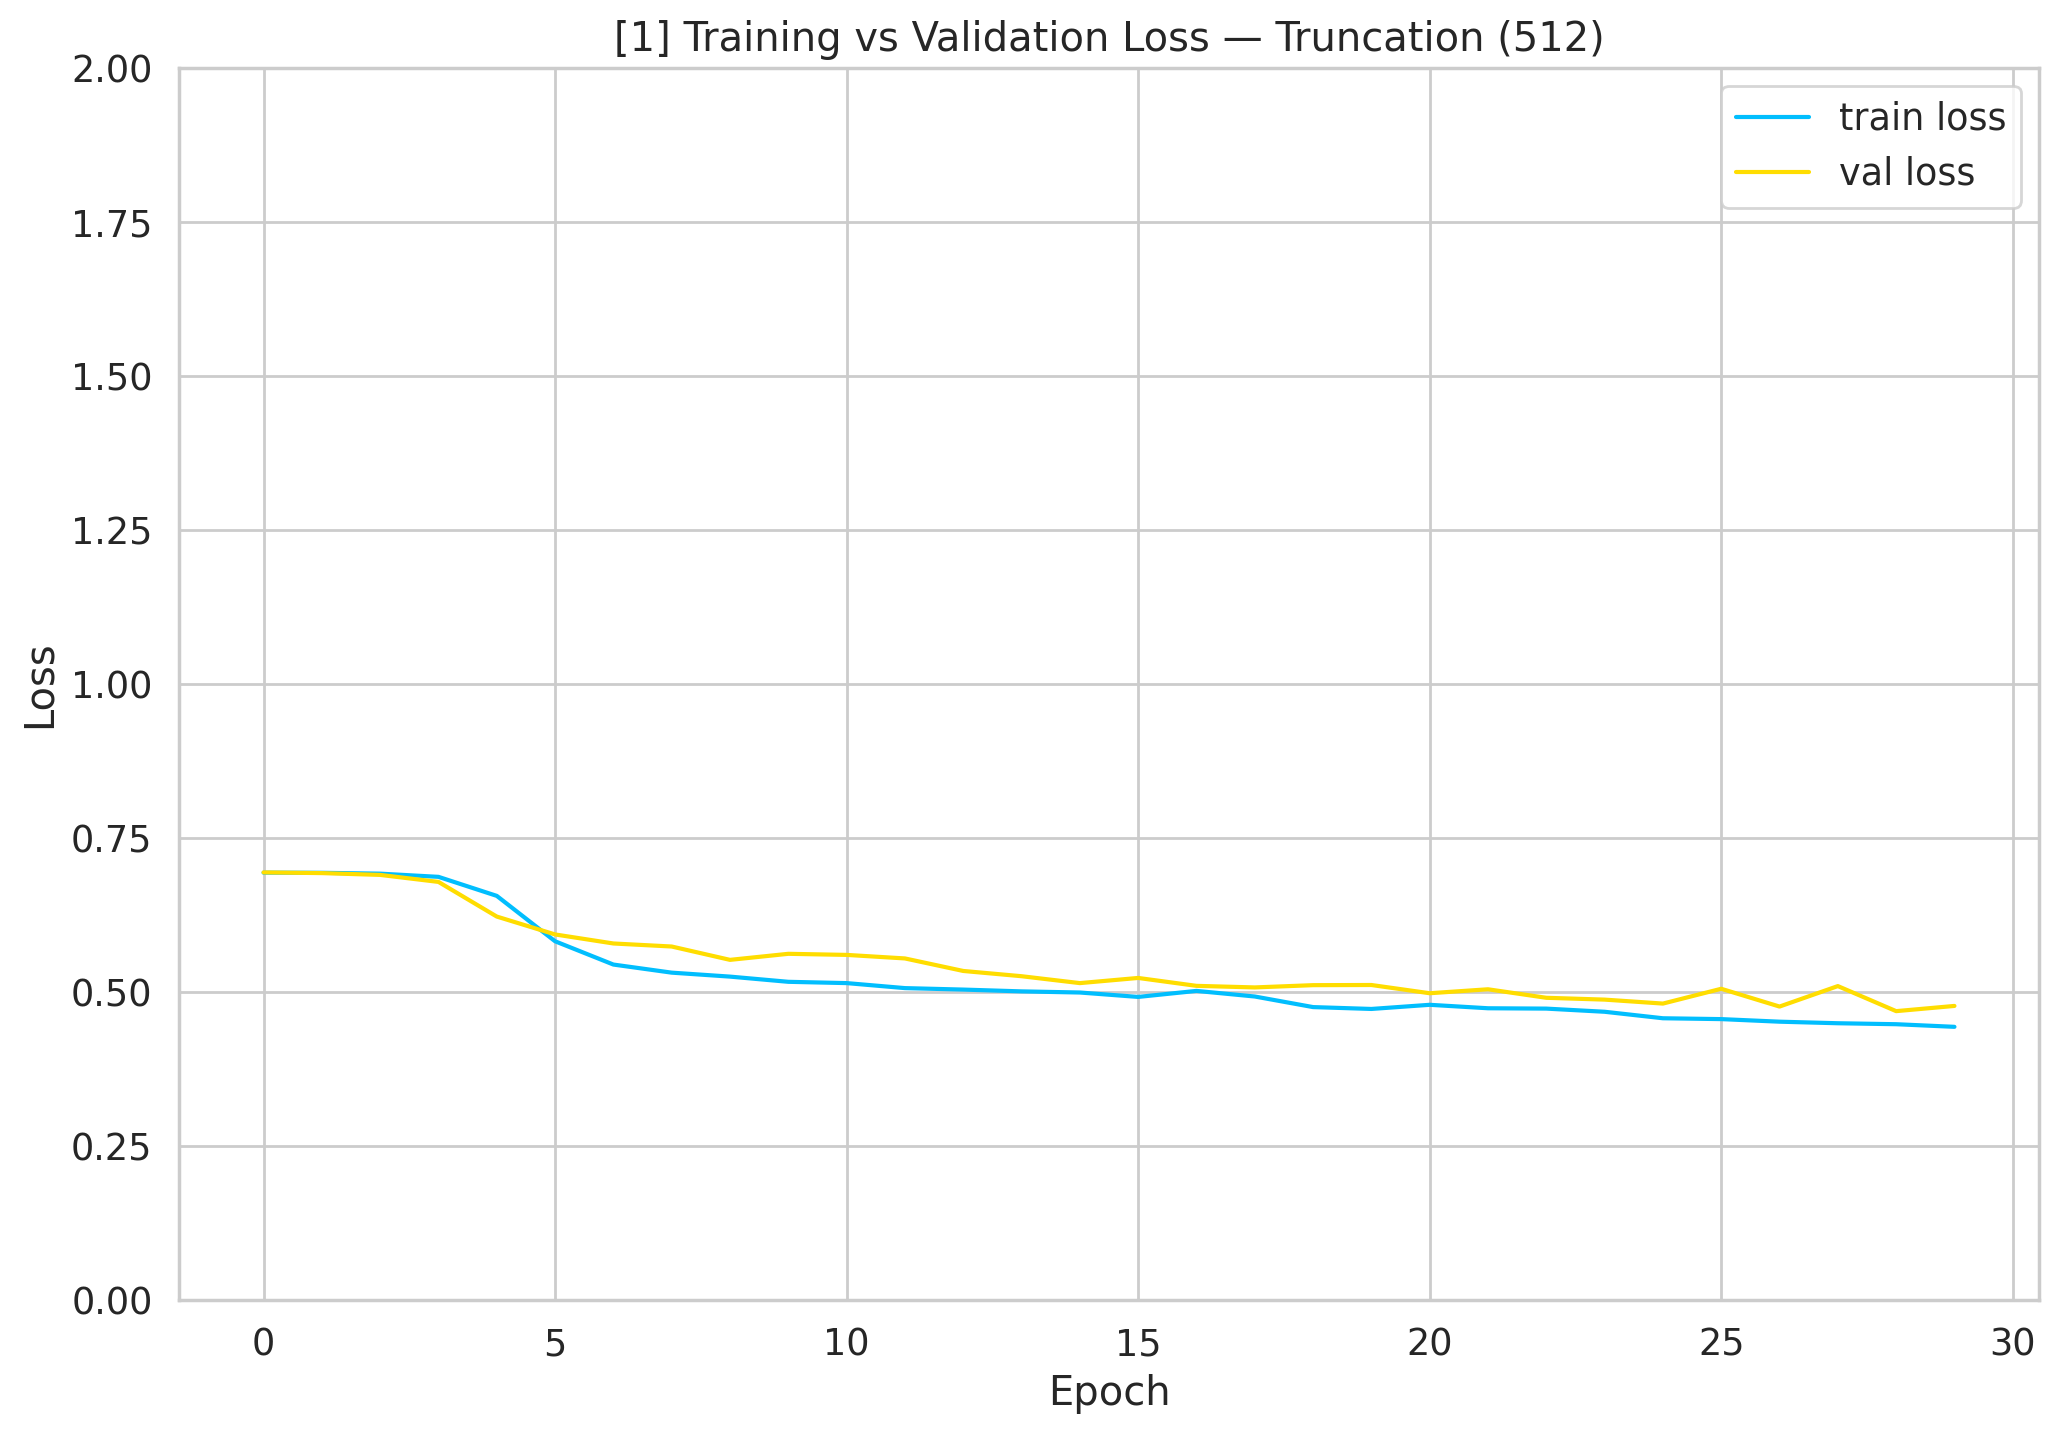


  Métricas Finais — [1] Truncation (512)
  Accuracy:  0.7916
  Precision: 0.7975
  Recall:    0.7915
  F1-Score:  0.7905

  Classification Report — [1] Truncation (512)
                     precision    recall  f1-score   support

Desfavorável ao Réu       0.76      0.86      0.81       545
   Favorável ao Réu       0.84      0.72      0.78       544

           accuracy                           0.79      1089
          macro avg       0.80      0.79      0.79      1089
       weighted avg       0.80      0.79      0.79      1089



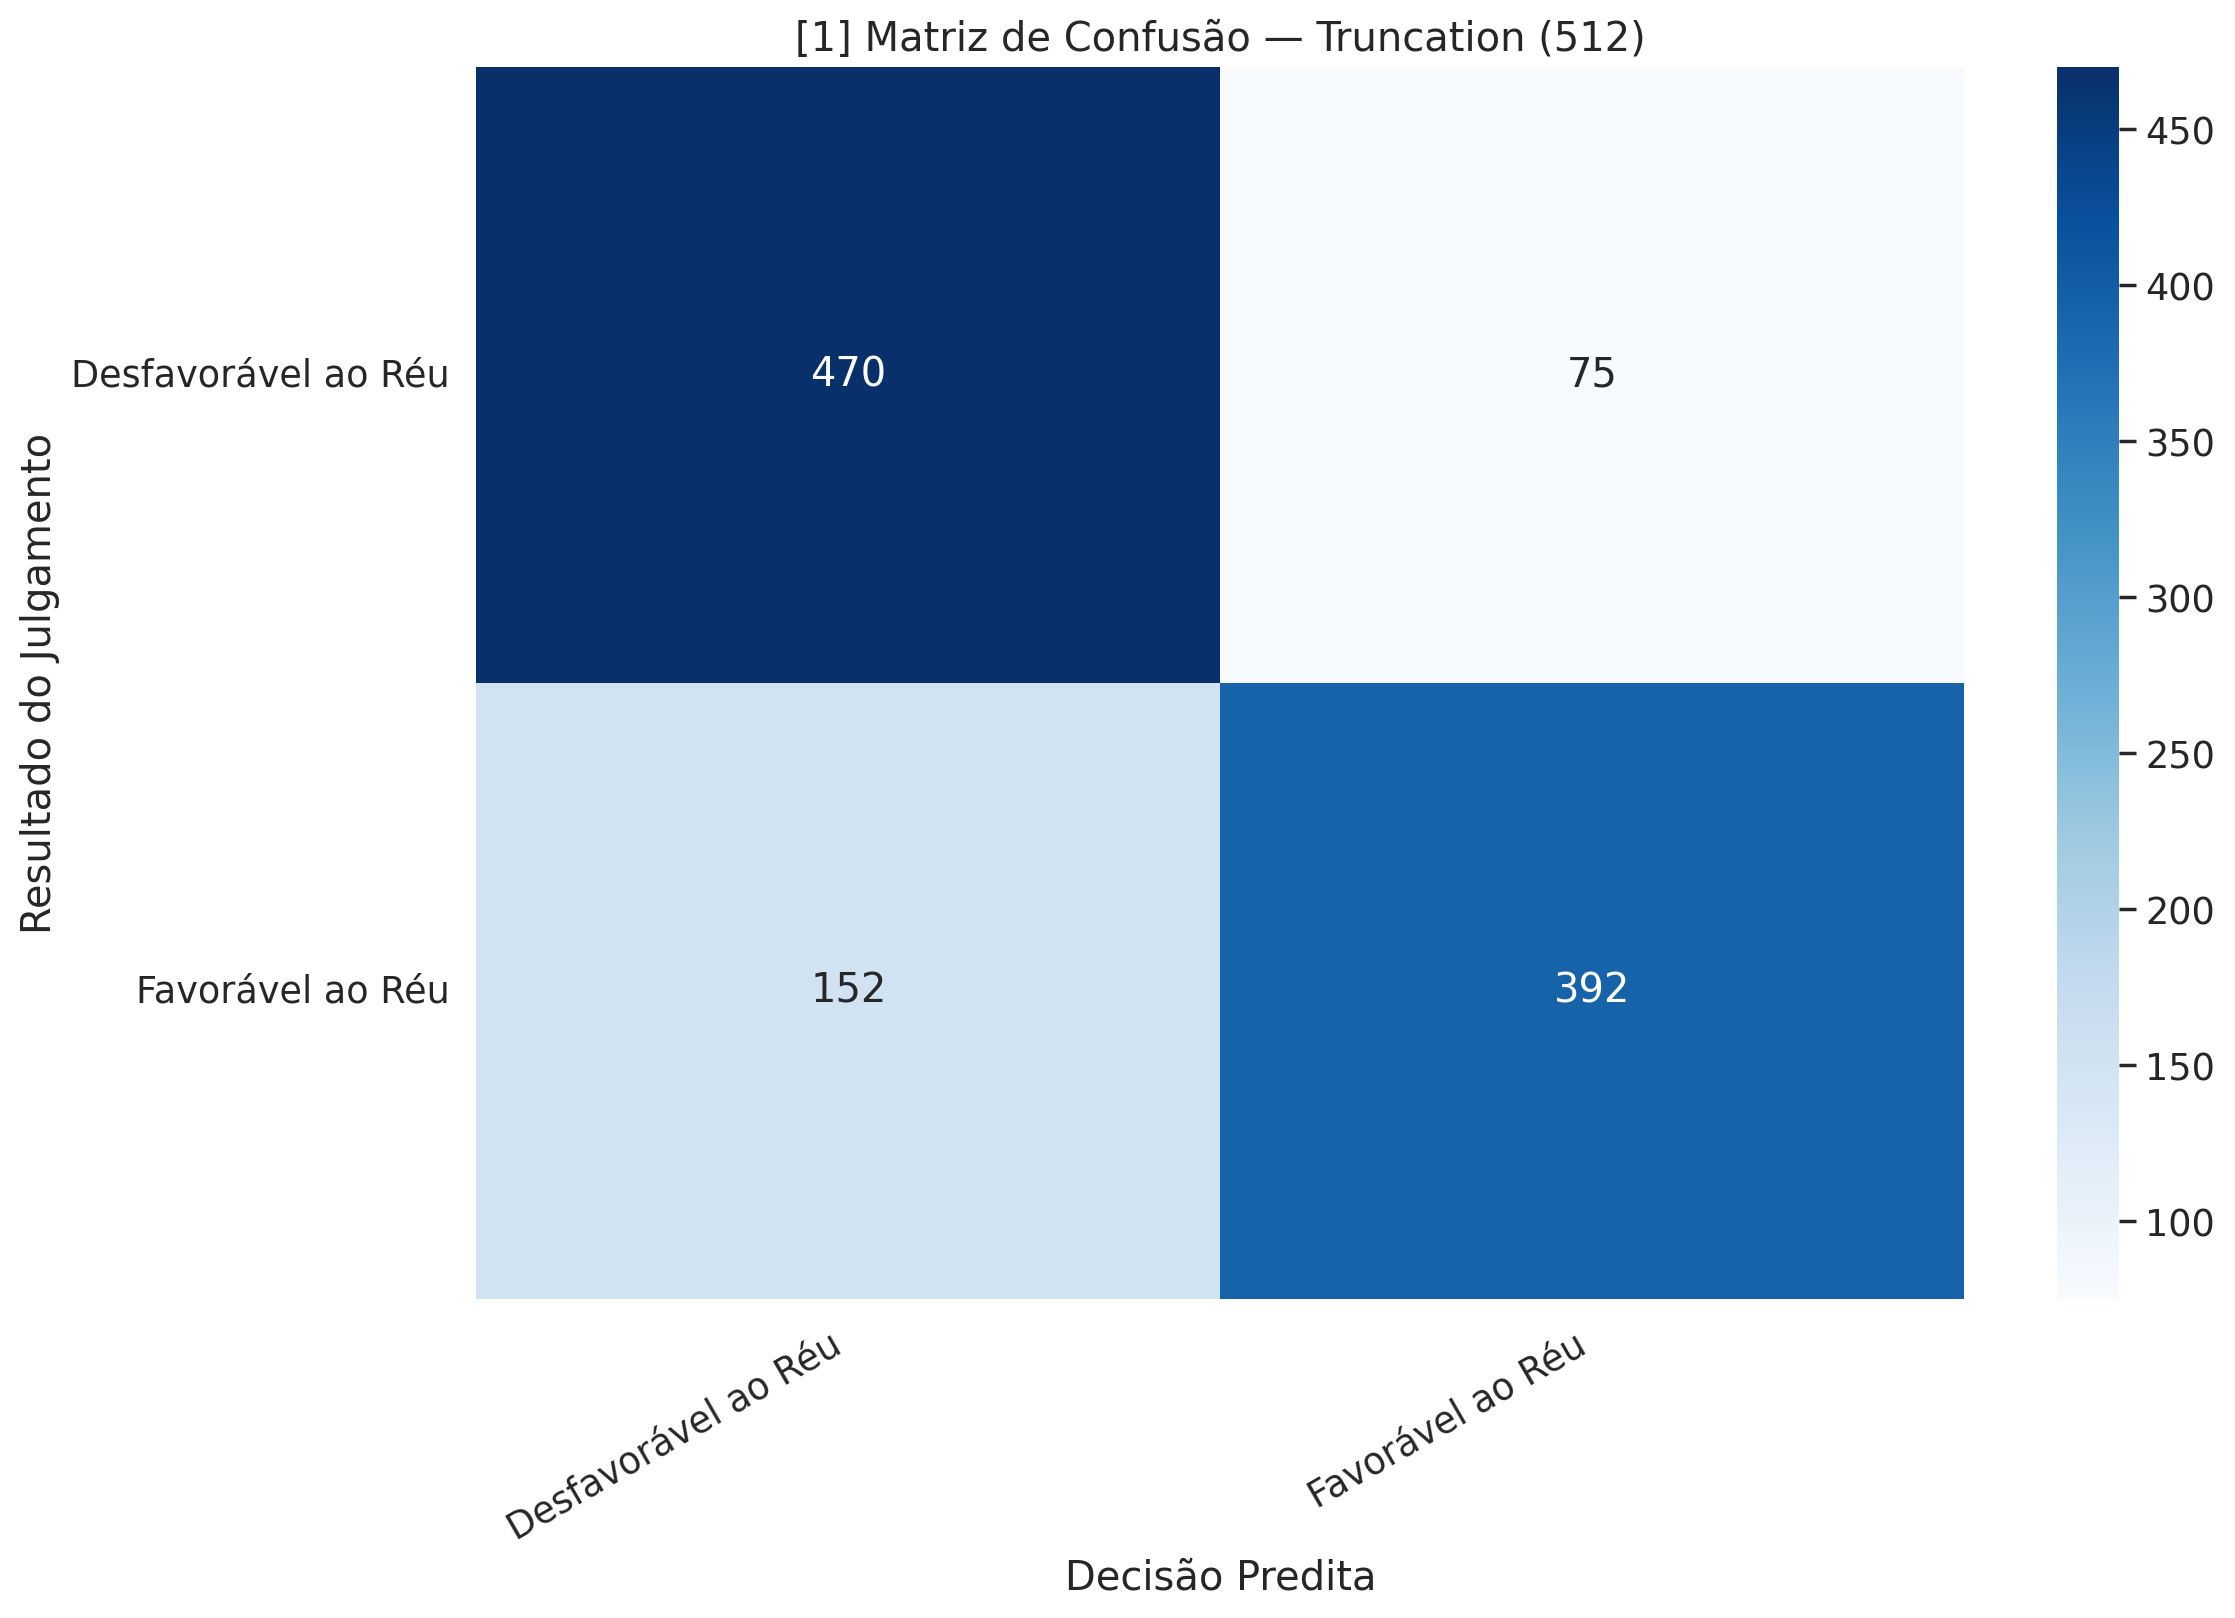

  FPR: 0.1376


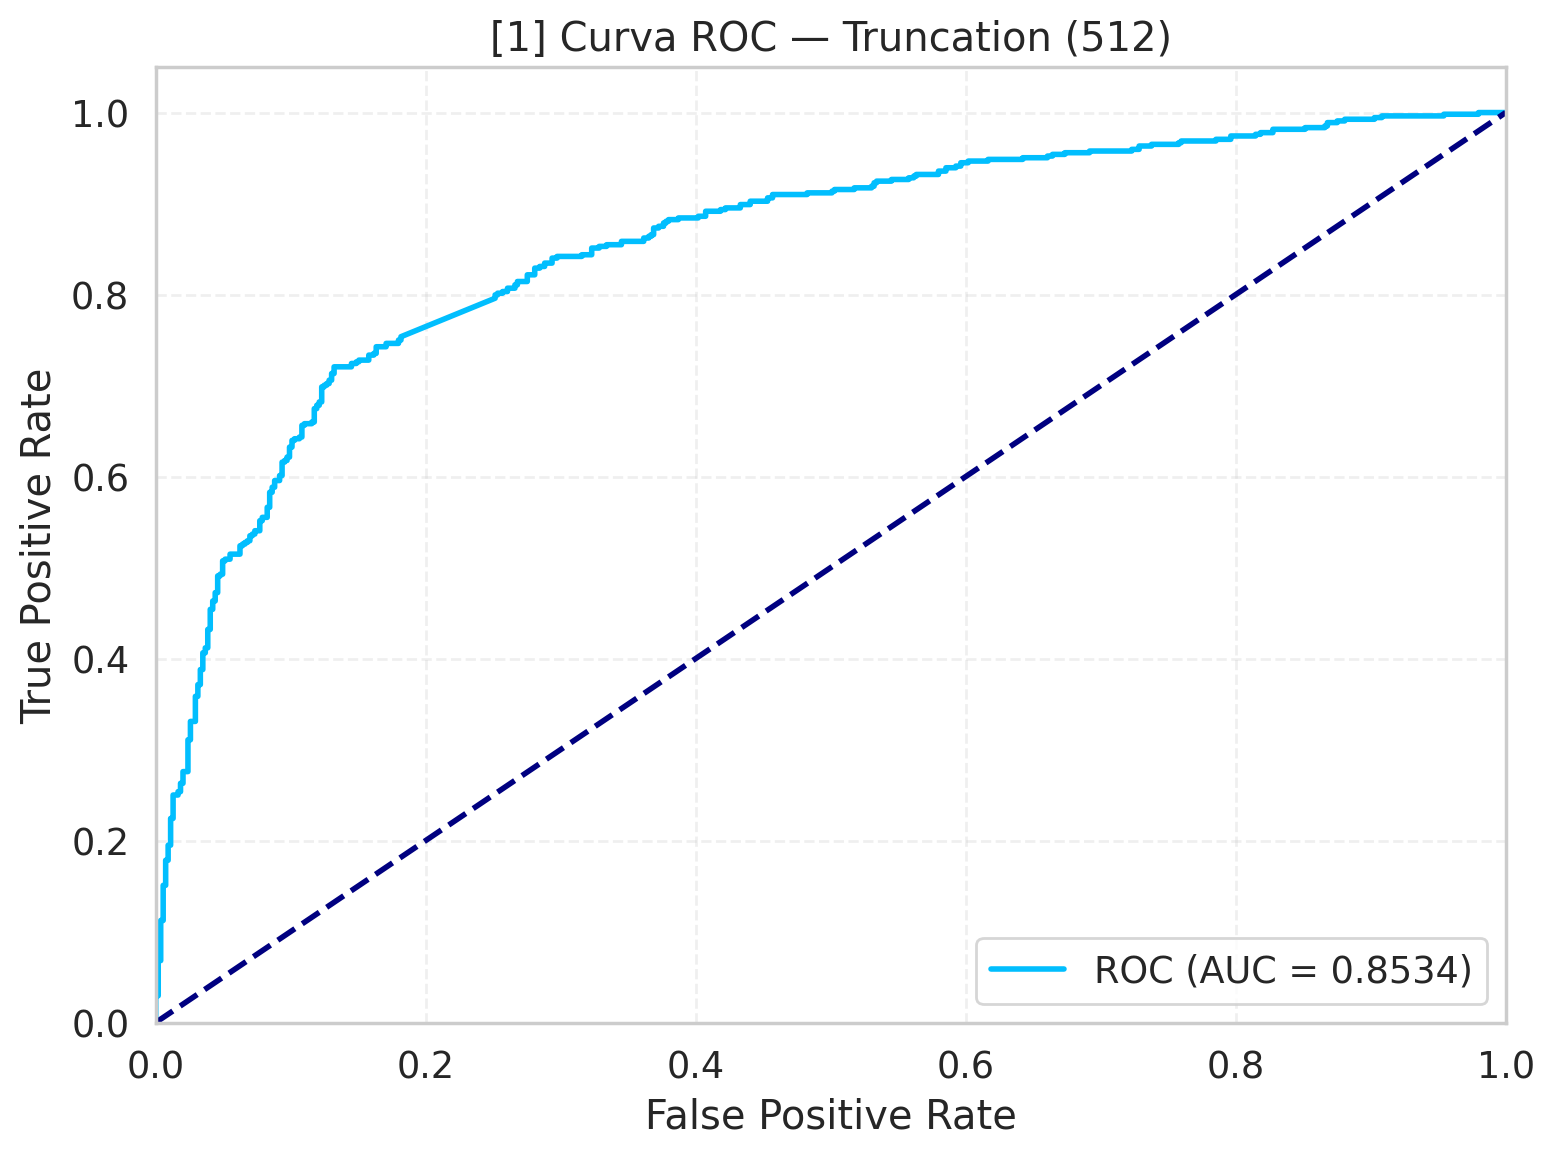

  AUC: 0.8534

[2/7] [2] Mean Pooling - Stride 0
  Modelo: raquelsilveira/legalbertpt_fp | chunk_size=512 | stride=512 | min_chunk_tokens=64 | max_chunks=None | pooling=mean
  [Dataset] Documentos: 4356
  [Dataset] Chunks/doc antes do filtro (min=64):  1.36  (total=5915)
  [Dataset] Chunks/doc ap?s  filtro (min=64):  1.31  (removidos=230, 3.9%)
  [Dataset] max_chunks=None ? sem limita??o adicional
  [Dataset] Documentos: 1089
  [Dataset] Chunks/doc antes do filtro (min=64):  1.32  (total=1436)
  [Dataset] Chunks/doc ap?s  filtro (min=64):  1.28  (removidos=40, 2.8%)
  [Dataset] max_chunks=None ? sem limita??o adicional


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: raquelsilveira/legalbertpt_fp
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Freezing embeddings + first 12 encoder layers...
Layers freezing complete.

  Epoch 1/200
  ------------------------------------------------------------
  Train | loss 0.6930 acc 0.5005 prec 0.2502 rec 0.5000 f1 0.3335
  Test  | loss 0.6925 acc 0.5005 prec 0.2502 rec 0.5000 f1 0.3335

  Epoch 2/200
  ------------------------------------------------------------
  Train | loss 0.6918 acc 0.5161 prec 0.6161 rec 0.5156 f1 0.3822
  Test  | loss 0.6893 acc 0.5326 prec 0.7031 rec 0.5322 f1 0.4077

  Epoch 3/200
  ------------------------------------------------------------
  Train | loss 0.6845 acc 0.5898 prec 0.6366 rec 0.5895 f1 0.5509
  Test  | loss 0.6641 acc 0.6961 prec 0.6981 rec 0.6961 f1 0.6953

  Epoch 4/200
  ------------------------------------------------------------
  Train | loss 0.6168 acc 0.7041 prec 0.7042 rec 0.7041 f1 0.7040
  Test  | loss 0.5674 acc 0.7309 prec 0.7364 rec 0.7309 f1 0.7293

  Epoch 5/200
  ------------------------------------------------------------
  Train

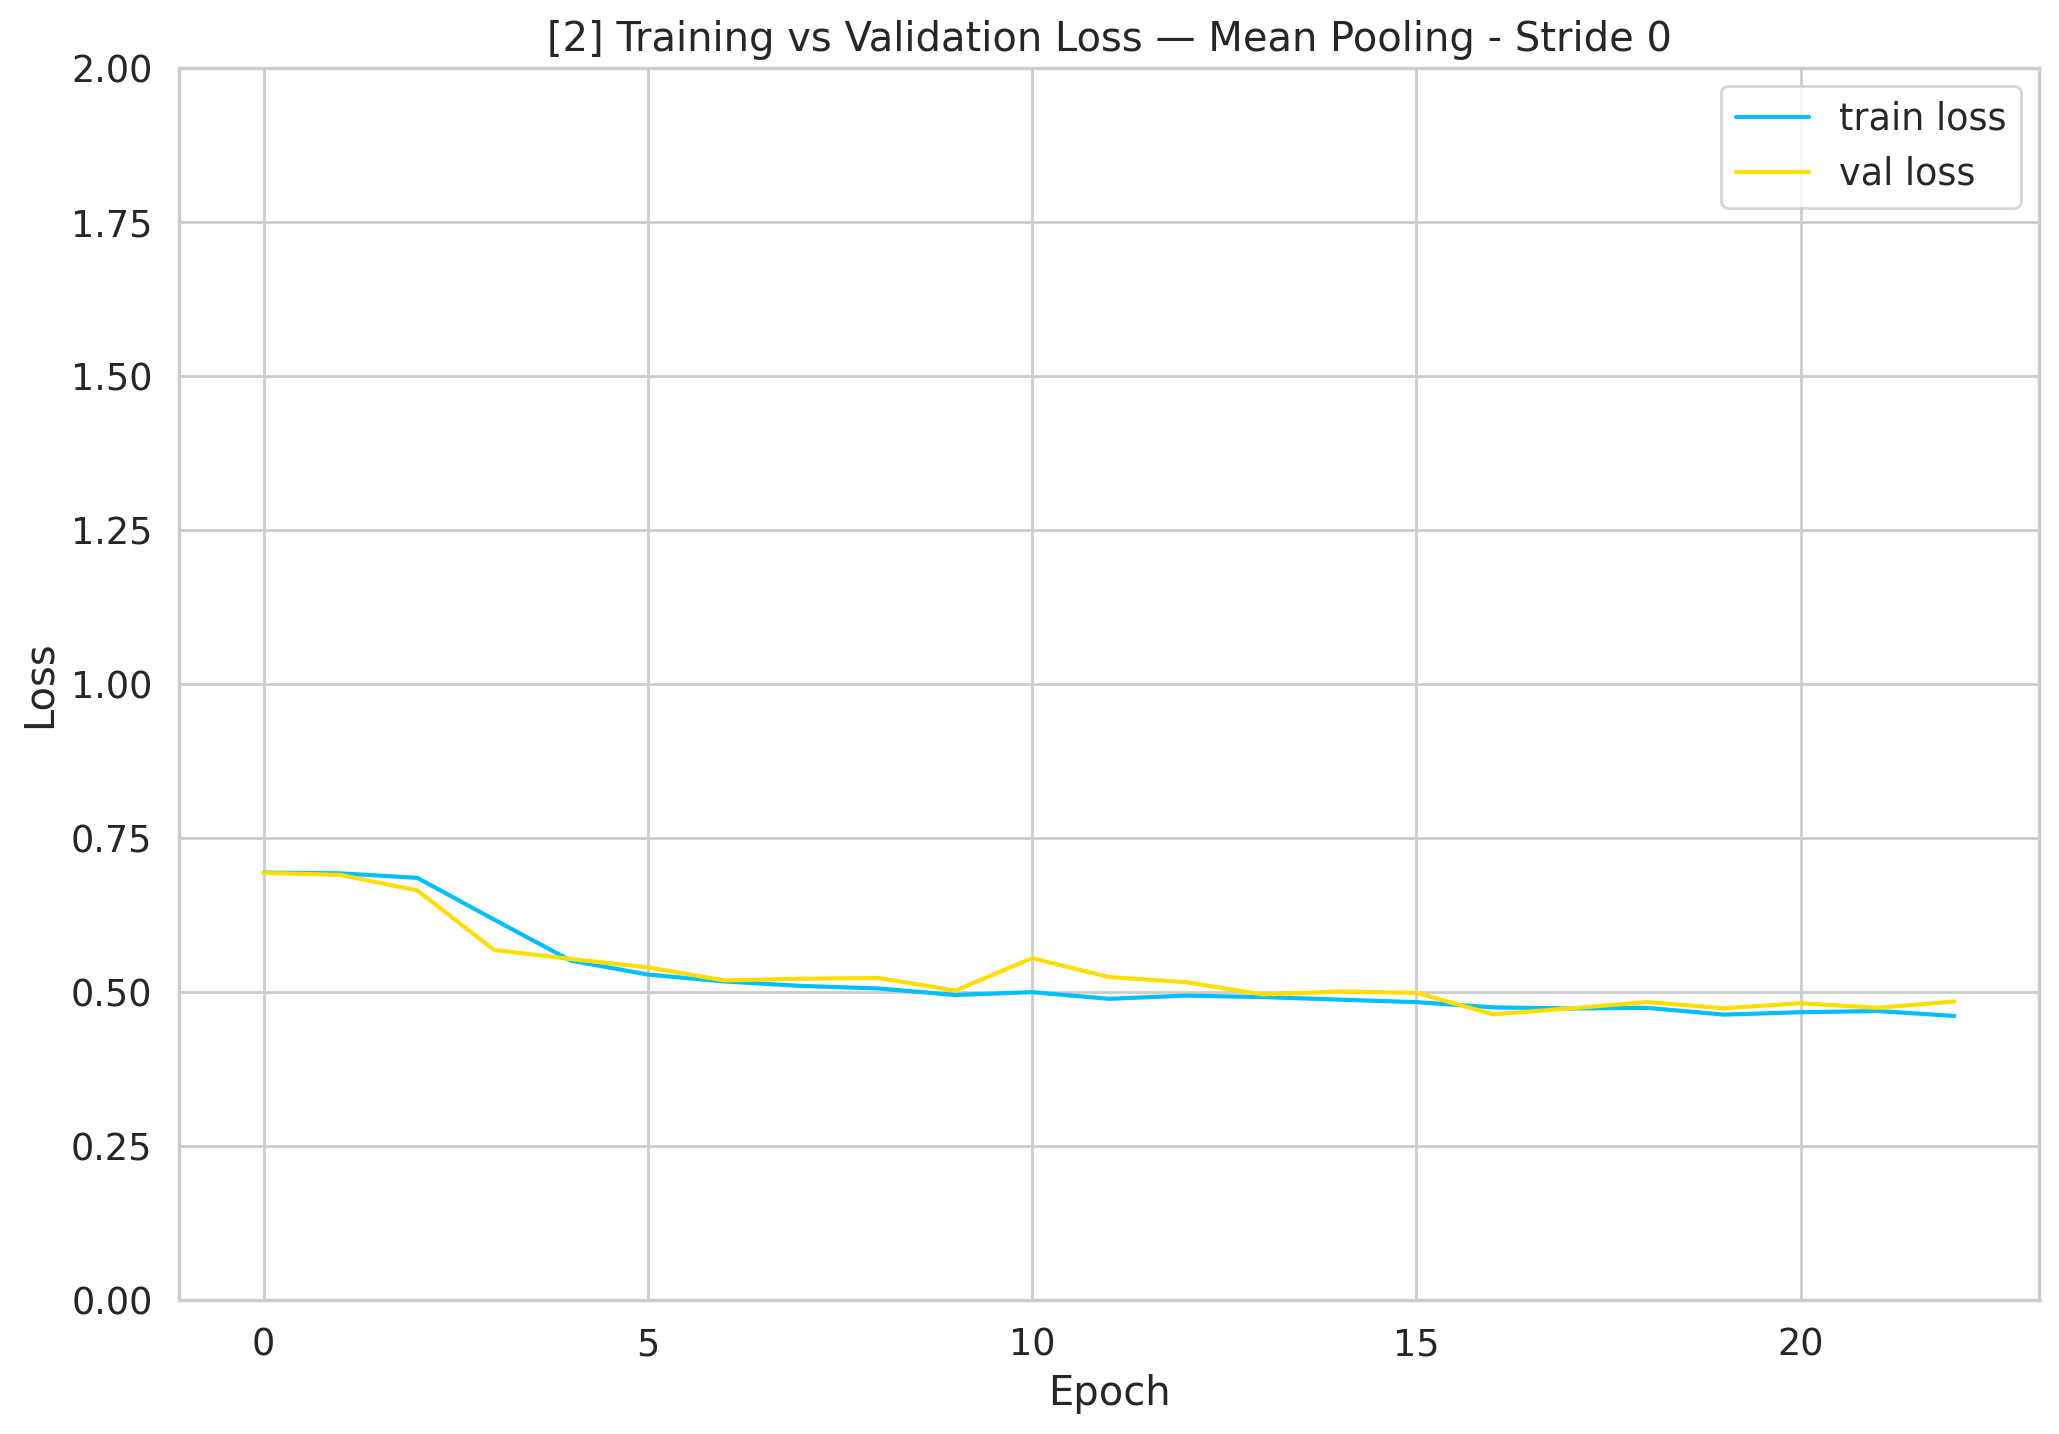


  Métricas Finais — [2] Mean Pooling - Stride 0
  Accuracy:  0.7961
  Precision: 0.7961
  Recall:    0.7961
  F1-Score:  0.7961

  Classification Report — [2] Mean Pooling - Stride 0
                     precision    recall  f1-score   support

Desfavorável ao Réu       0.80      0.80      0.80       545
   Favorável ao Réu       0.80      0.79      0.80       544

           accuracy                           0.80      1089
          macro avg       0.80      0.80      0.80      1089
       weighted avg       0.80      0.80      0.80      1089



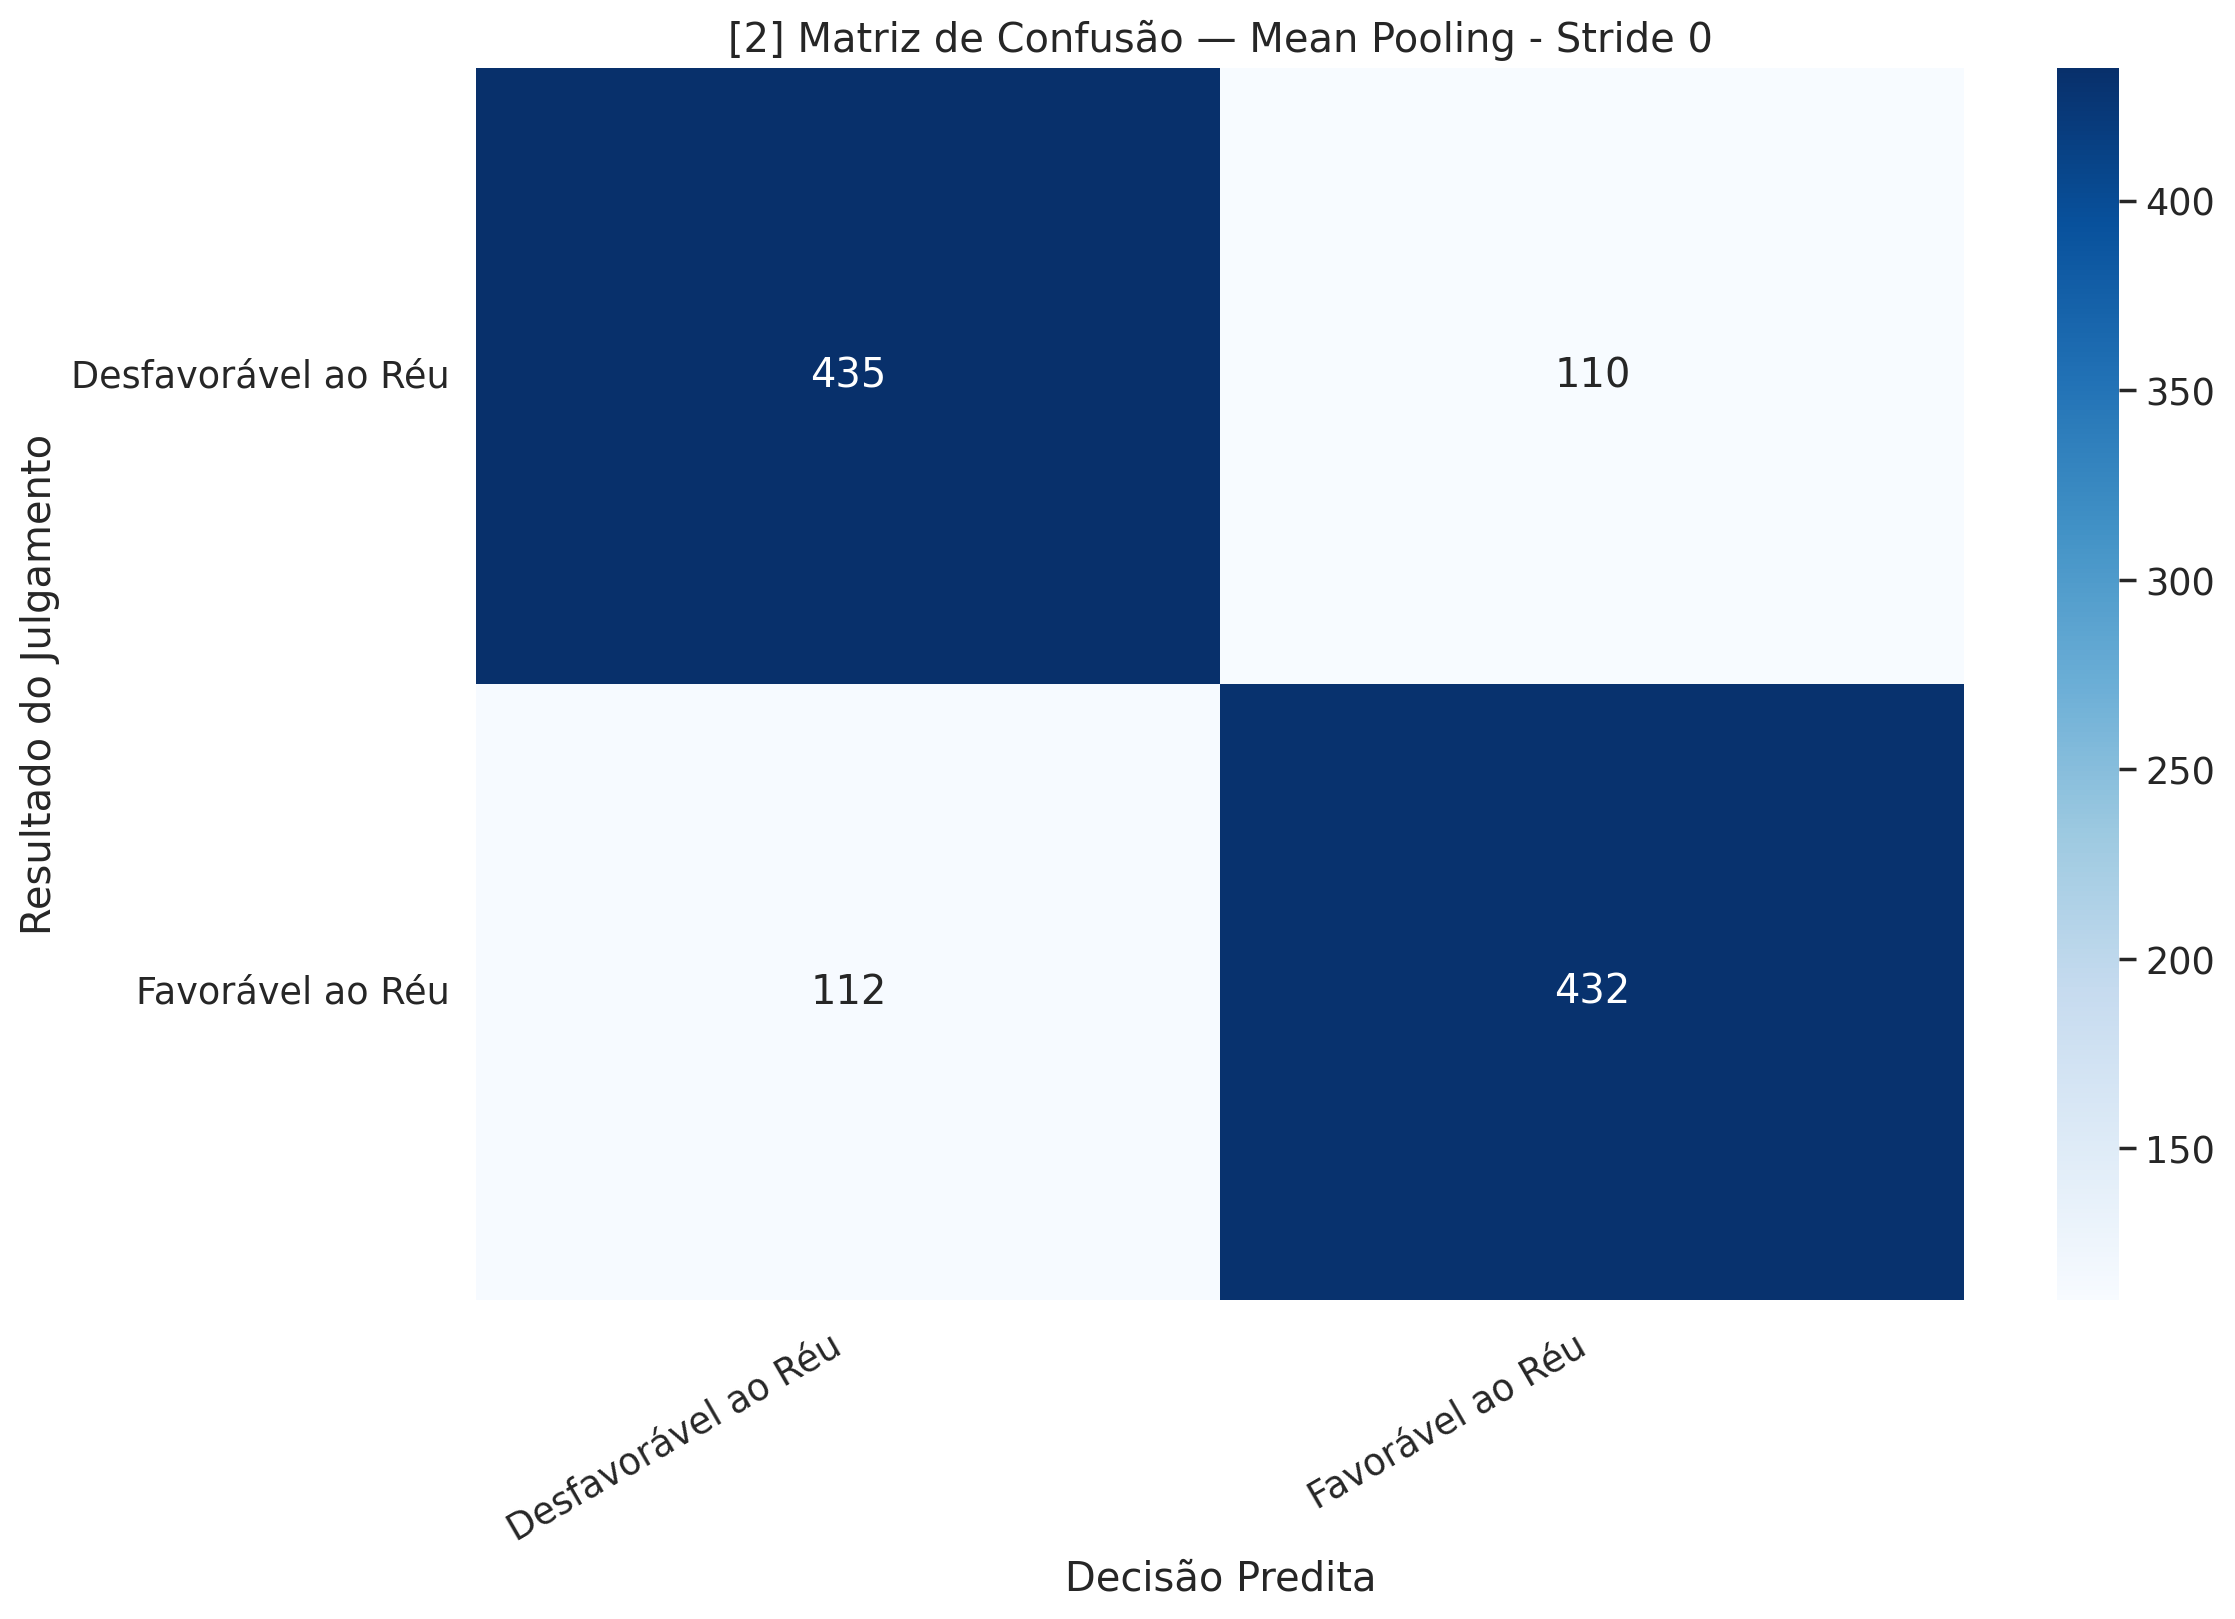

  FPR: 0.2018


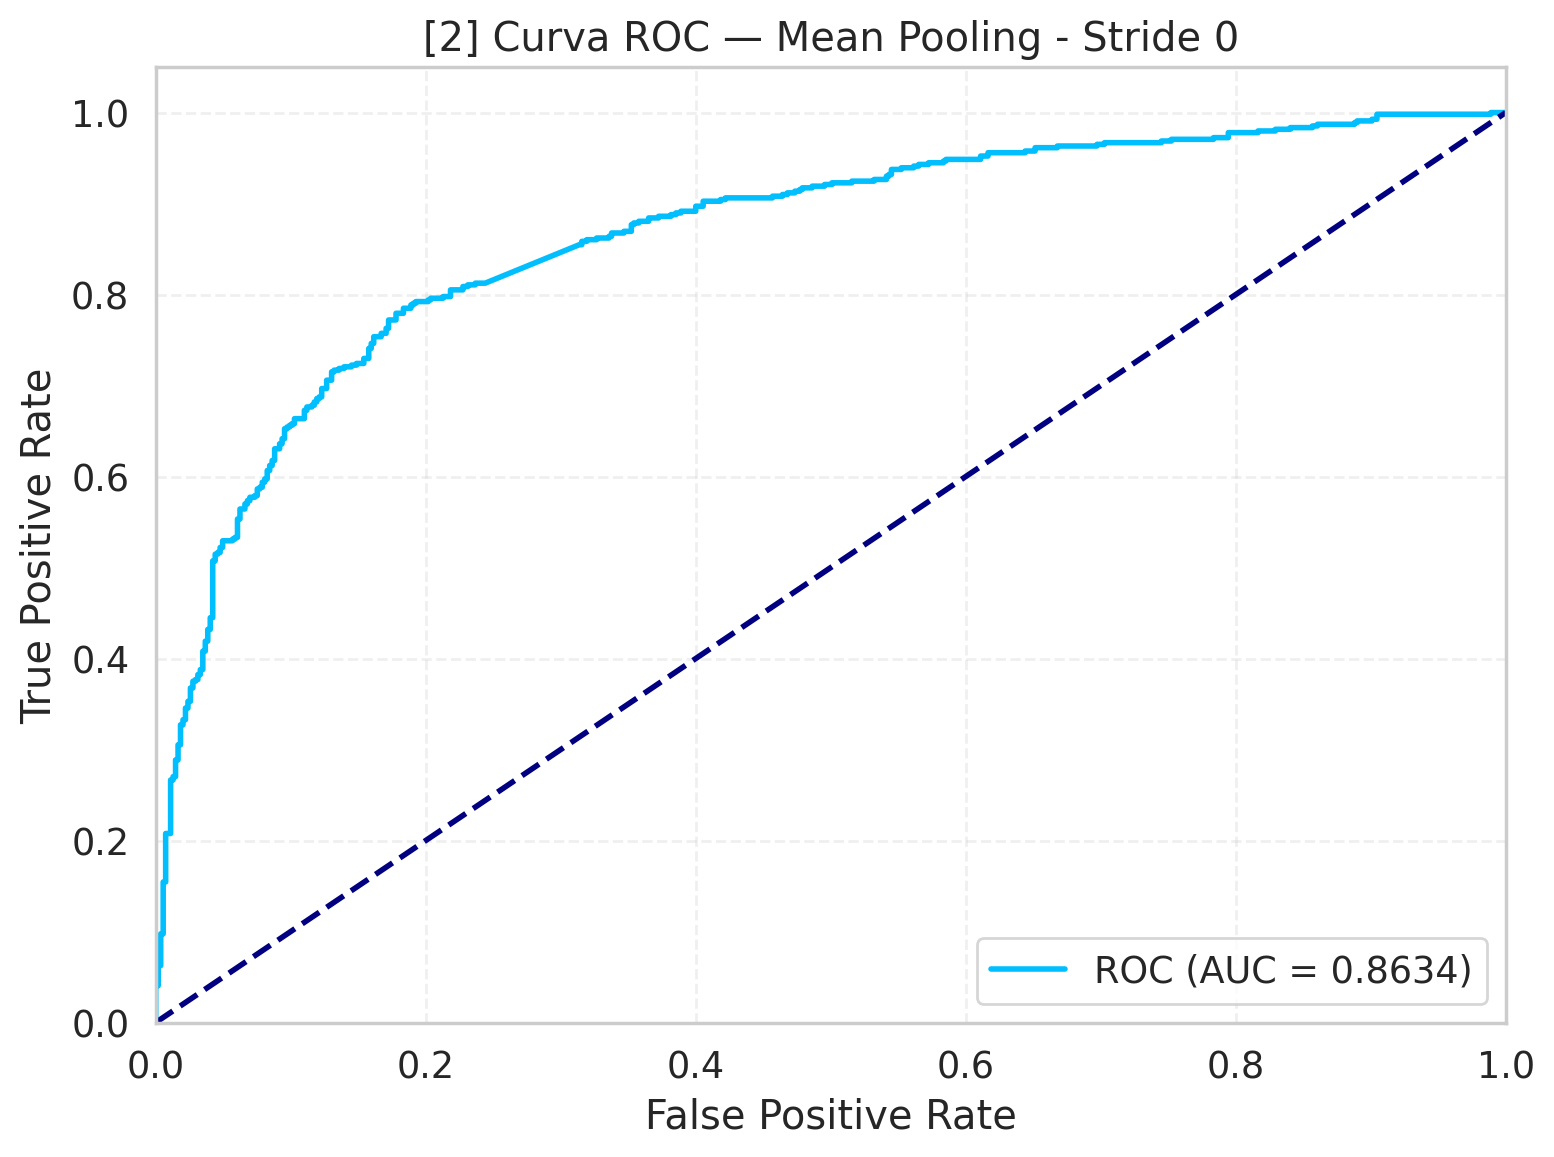

  AUC: 0.8634

[3/7] [3] Mean Pooling - Stride 128
  Modelo: raquelsilveira/legalbertpt_fp | chunk_size=512 | stride=128 | min_chunk_tokens=64 | max_chunks=None | pooling=mean
  [Dataset] Documentos: 4356
  [Dataset] Chunks/doc antes do filtro (min=64):  1.96  (total=8556)
  [Dataset] Chunks/doc ap?s  filtro (min=64):  1.96  (removidos=0, 0.0%)
  [Dataset] max_chunks=None ? sem limita??o adicional
  [Dataset] Documentos: 1089
  [Dataset] Chunks/doc antes do filtro (min=64):  1.85  (total=2013)
  [Dataset] Chunks/doc ap?s  filtro (min=64):  1.85  (removidos=0, 0.0%)
  [Dataset] max_chunks=None ? sem limita??o adicional


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: raquelsilveira/legalbertpt_fp
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Freezing embeddings + first 12 encoder layers...
Layers freezing complete.

  Epoch 1/200
  ------------------------------------------------------------
  Train | loss 0.6931 acc 0.5005 prec 0.2502 rec 0.5000 f1 0.3335
  Test  | loss 0.6925 acc 0.5005 prec 0.2502 rec 0.5000 f1 0.3335

  Epoch 2/200
  ------------------------------------------------------------
  Train | loss 0.6919 acc 0.5085 prec 0.5841 rec 0.5081 f1 0.3646
  Test  | loss 0.6894 acc 0.5418 prec 0.6697 rec 0.5414 f1 0.4347

  Epoch 3/200
  ------------------------------------------------------------
  Train | loss 0.6839 acc 0.5989 prec 0.6398 rec 0.5987 f1 0.5670
  Test  | loss 0.6628 acc 0.6869 prec 0.6898 rec 0.6869 f1 0.6857

  Epoch 4/200
  ------------------------------------------------------------
  Train | loss 0.6208 acc 0.6947 prec 0.6947 rec 0.6947 f1 0.6947
  Test  | loss 0.5834 acc 0.7190 prec 0.7225 rec 0.7190 f1 0.7179

  Epoch 5/200
  ------------------------------------------------------------
  Train

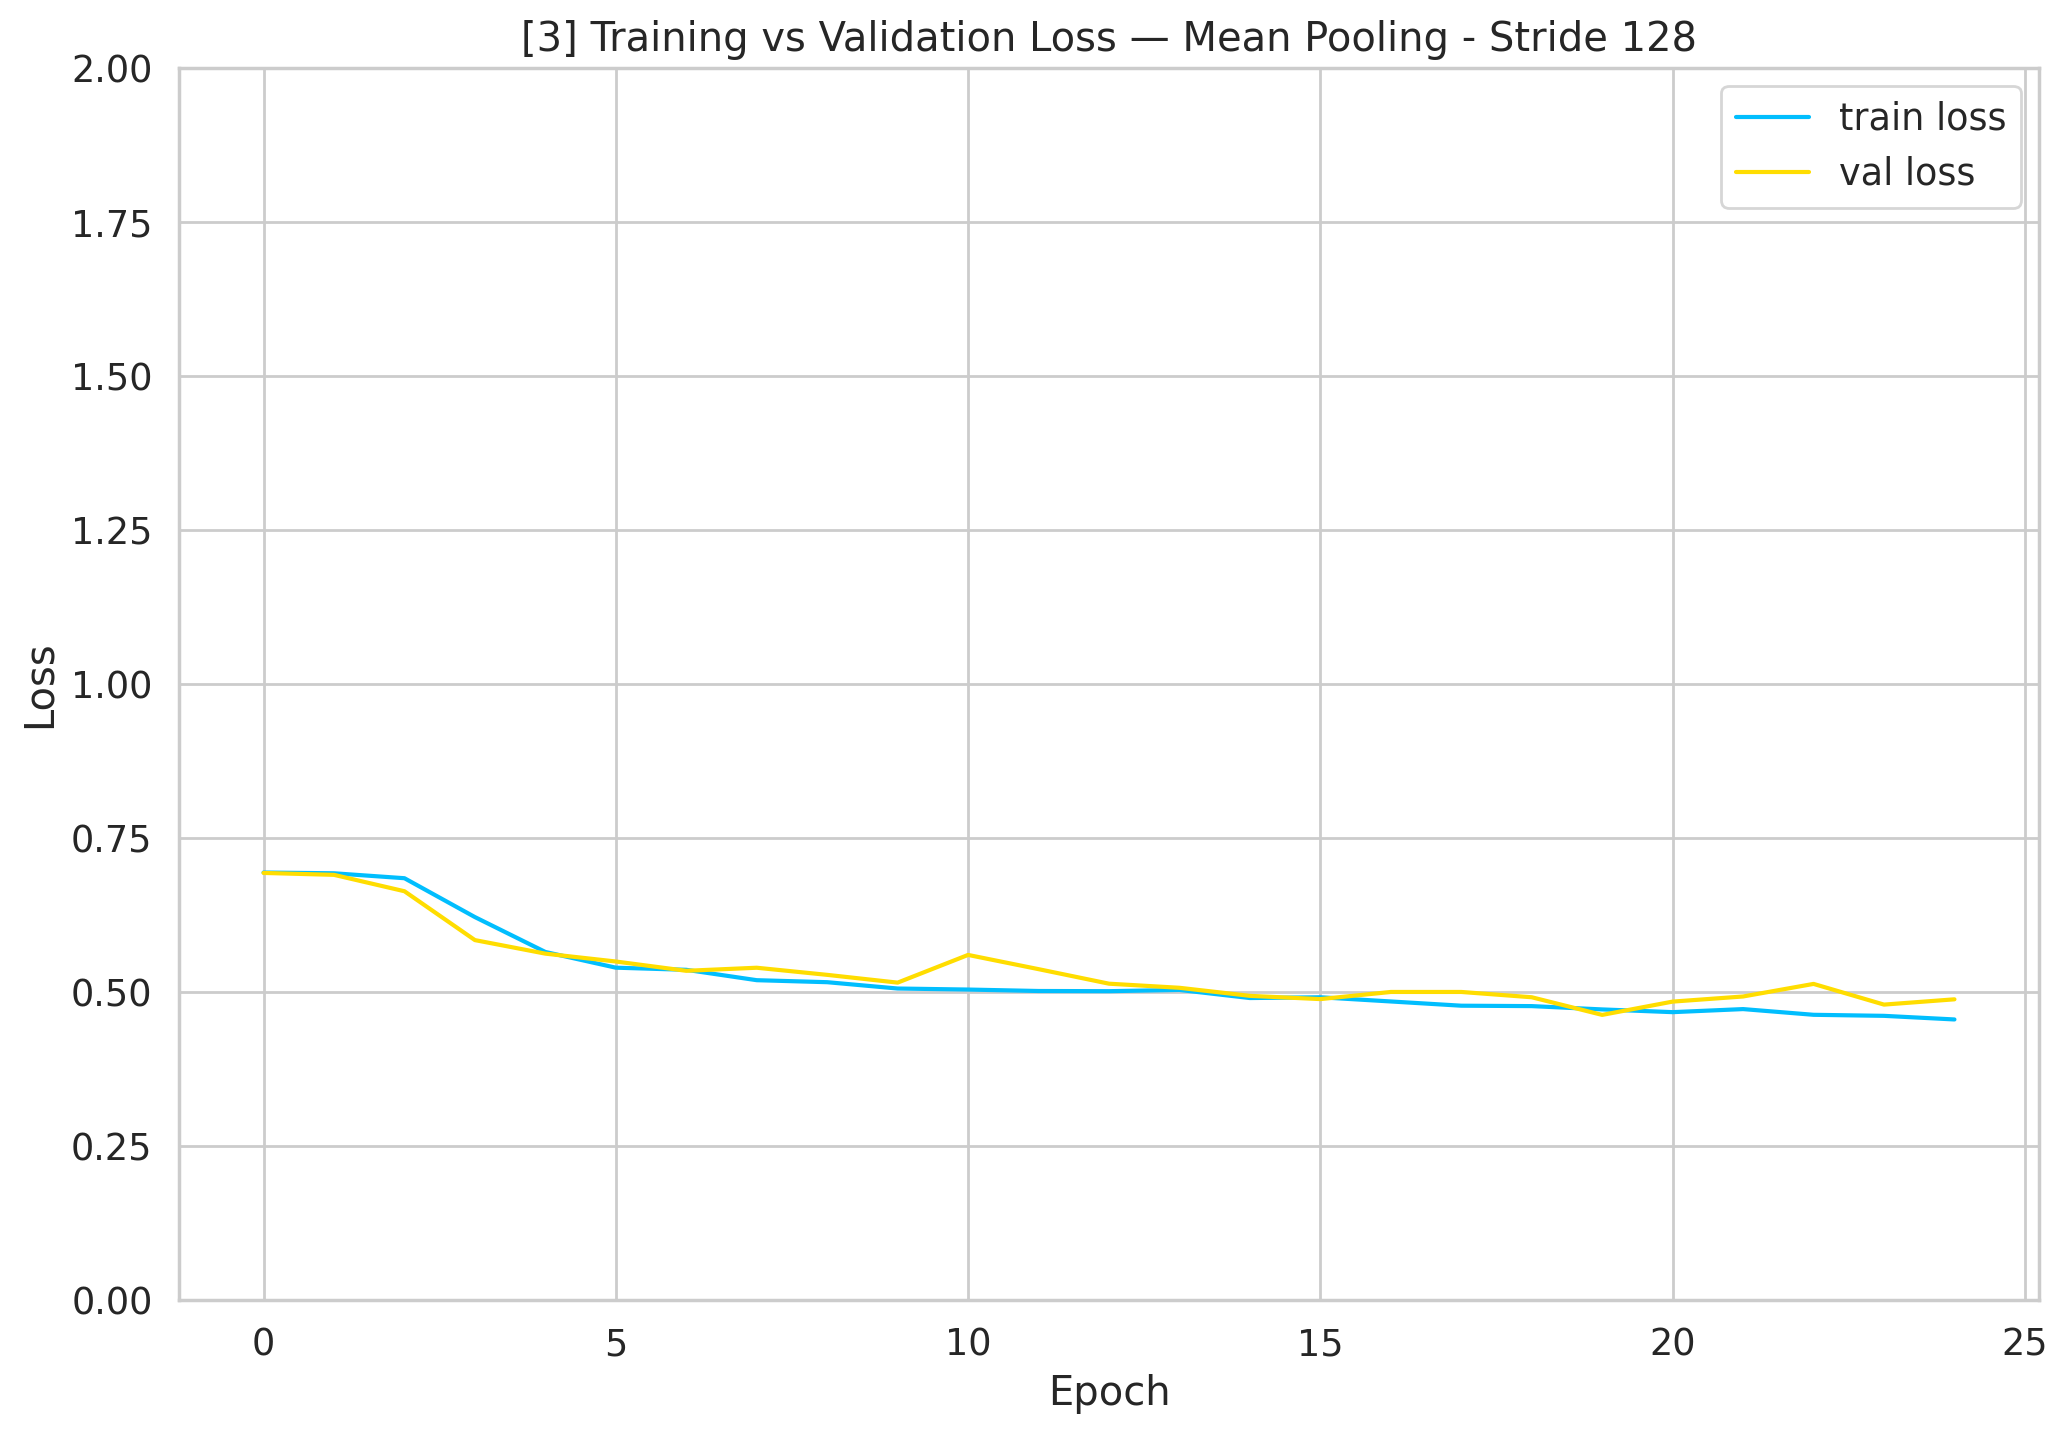


  Métricas Finais — [3] Mean Pooling - Stride 128
  Accuracy:  0.7980
  Precision: 0.7980
  Recall:    0.7980
  F1-Score:  0.7980

  Classification Report — [3] Mean Pooling - Stride 128
                     precision    recall  f1-score   support

Desfavorável ao Réu       0.79      0.81      0.80       545
   Favorável ao Réu       0.80      0.79      0.80       544

           accuracy                           0.80      1089
          macro avg       0.80      0.80      0.80      1089
       weighted avg       0.80      0.80      0.80      1089



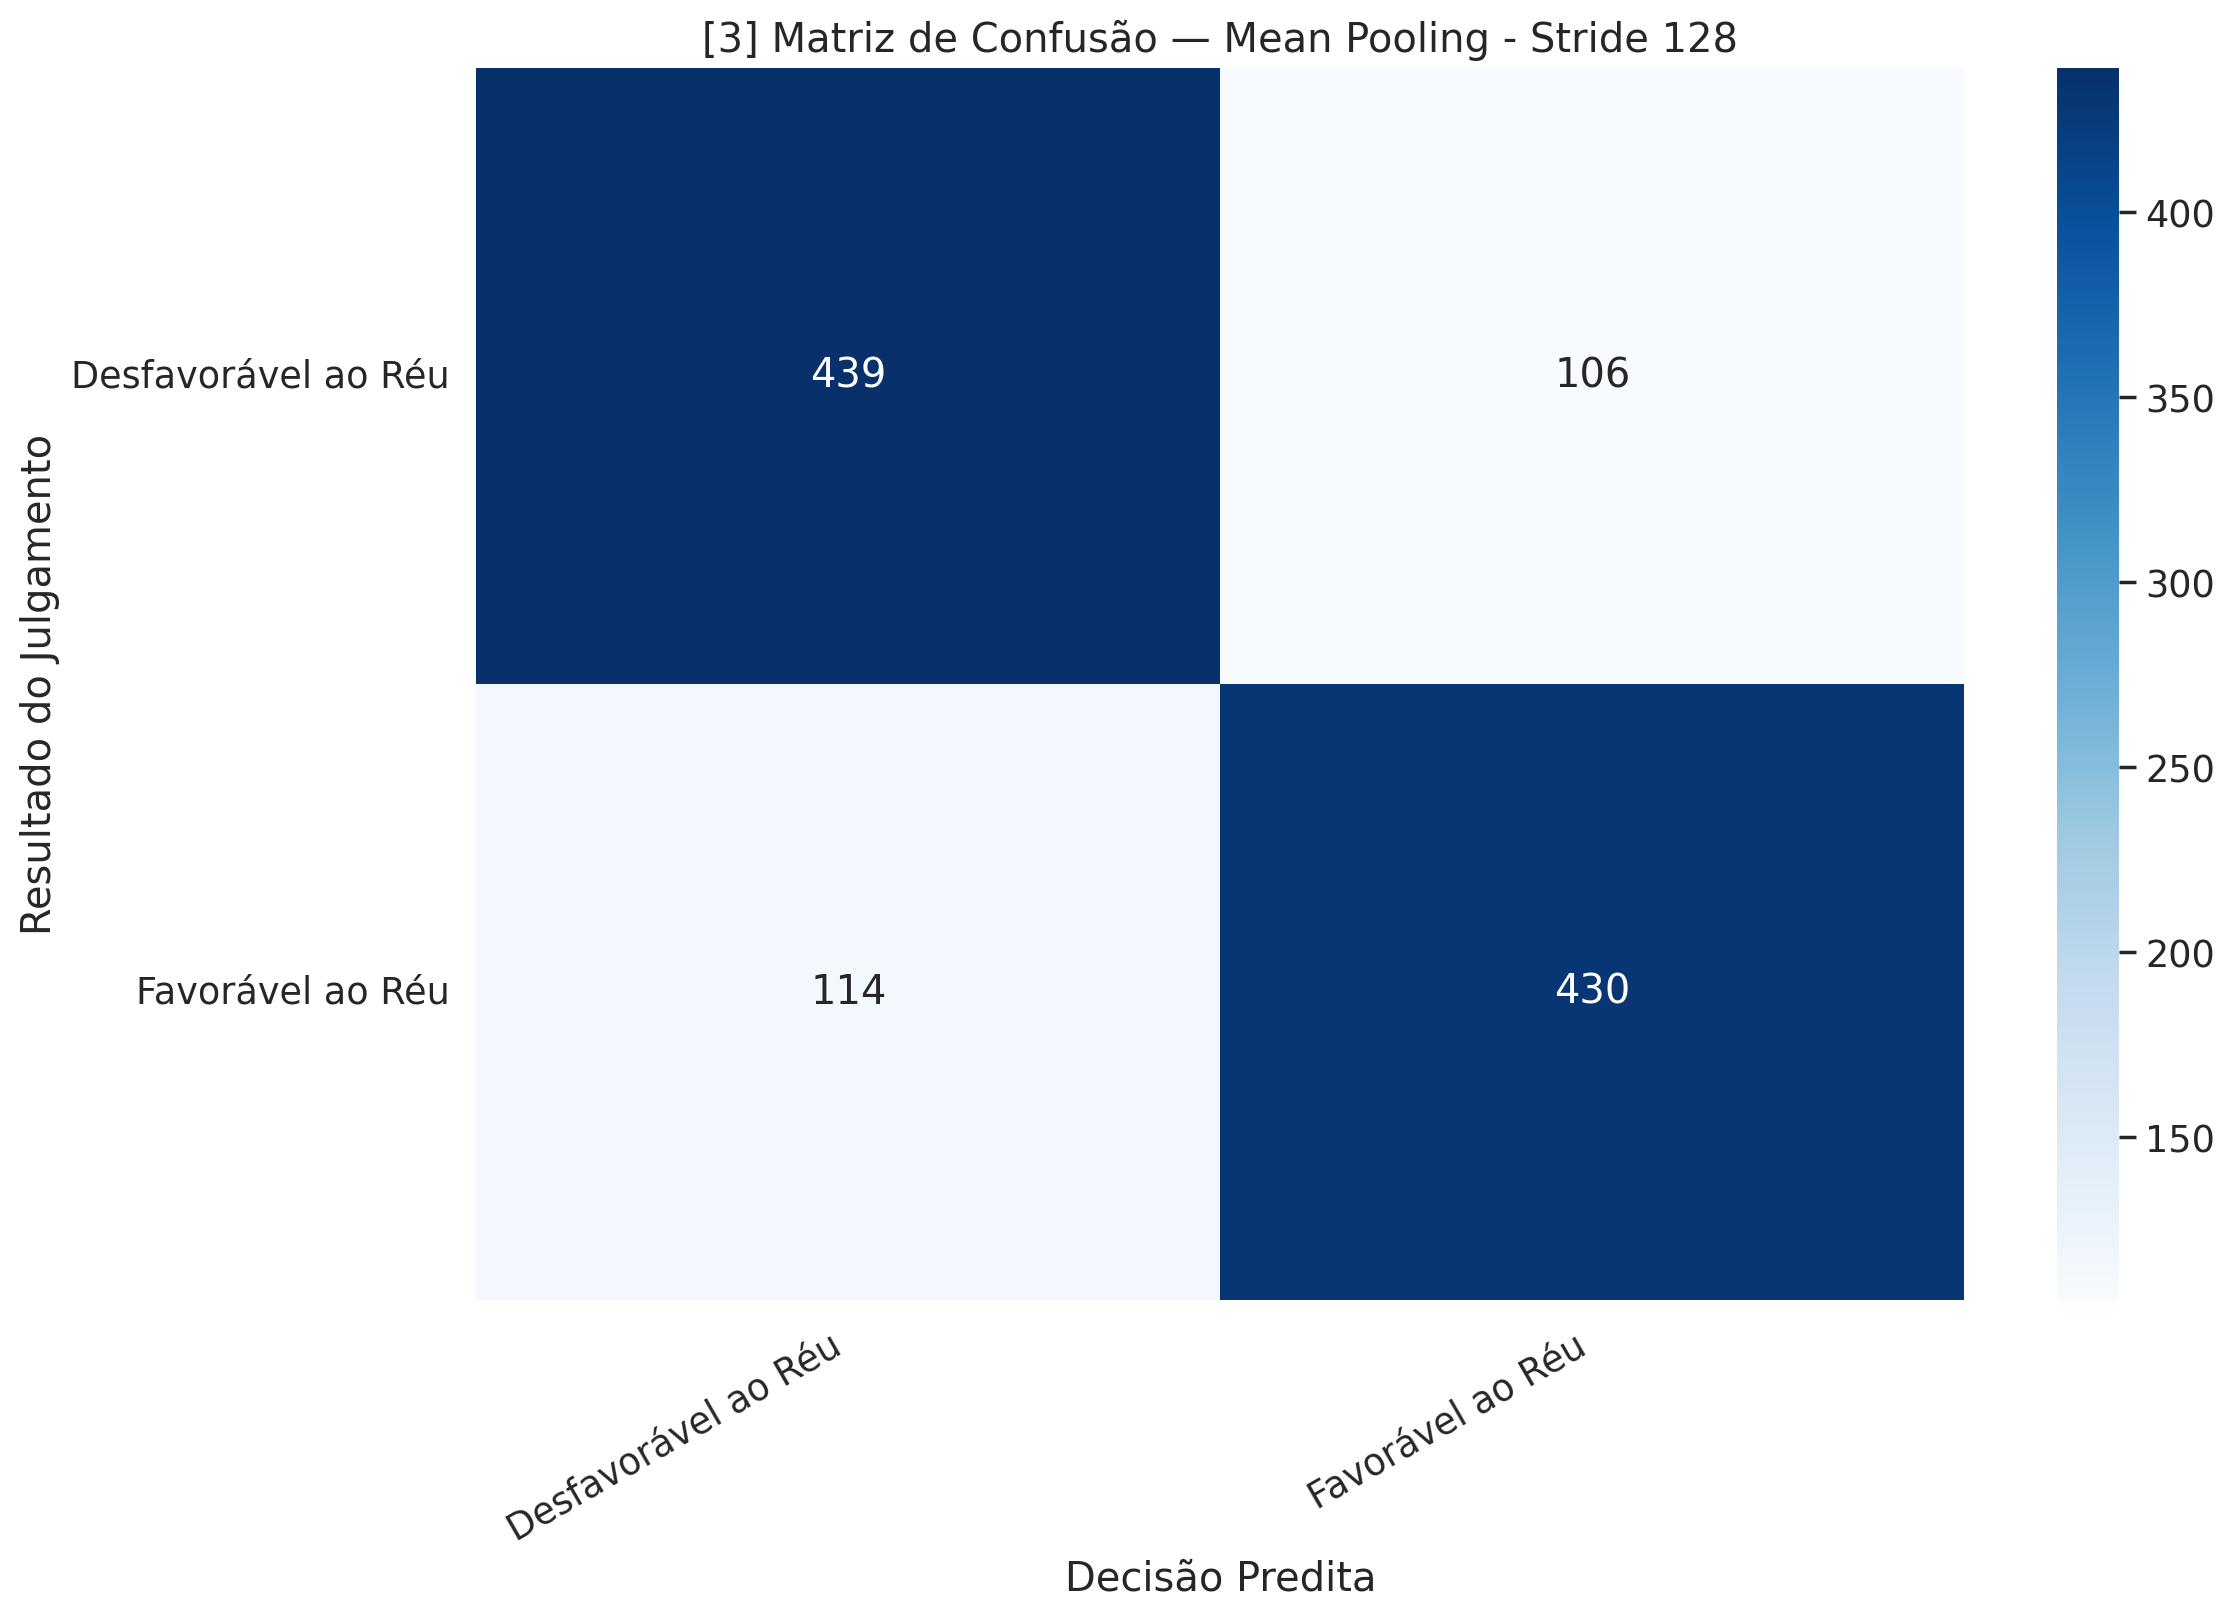

  FPR: 0.1945


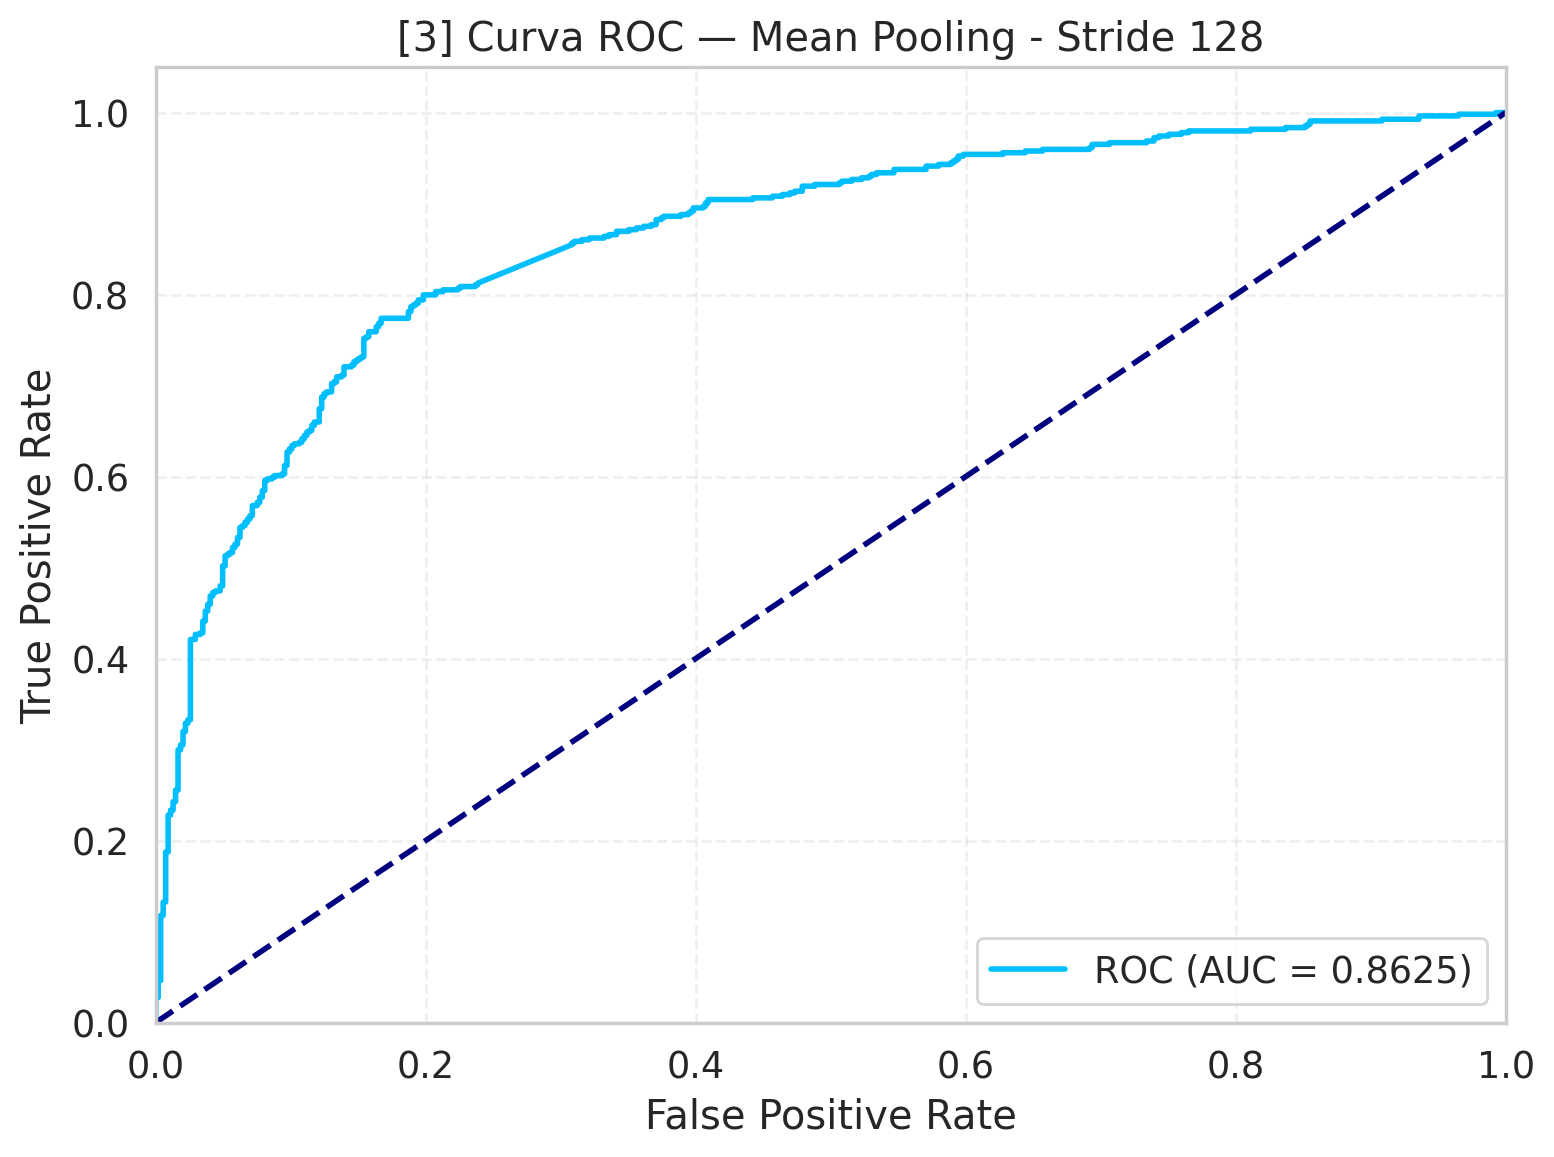

  AUC: 0.8625

[4/7] [4] Mean Pooling - Stride 256
  Modelo: raquelsilveira/legalbertpt_fp | chunk_size=512 | stride=256 | min_chunk_tokens=64 | max_chunks=None | pooling=mean
  [Dataset] Documentos: 4356
  [Dataset] Chunks/doc antes do filtro (min=64):  1.56  (total=6787)
  [Dataset] Chunks/doc ap?s  filtro (min=64):  1.56  (removidos=0, 0.0%)
  [Dataset] max_chunks=None ? sem limita??o adicional
  [Dataset] Documentos: 1089
  [Dataset] Chunks/doc antes do filtro (min=64):  1.48  (total=1617)
  [Dataset] Chunks/doc ap?s  filtro (min=64):  1.48  (removidos=0, 0.0%)
  [Dataset] max_chunks=None ? sem limita??o adicional


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: raquelsilveira/legalbertpt_fp
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Freezing embeddings + first 12 encoder layers...
Layers freezing complete.

  Epoch 1/200
  ------------------------------------------------------------
  Train | loss 0.6931 acc 0.5005 prec 0.2502 rec 0.5000 f1 0.3335
  Test  | loss 0.6925 acc 0.5005 prec 0.2502 rec 0.5000 f1 0.3335

  Epoch 2/200
  ------------------------------------------------------------
  Train | loss 0.6919 acc 0.5101 prec 0.5999 rec 0.5097 f1 0.3668
  Test  | loss 0.6894 acc 0.5335 prec 0.7231 rec 0.5331 f1 0.4070

  Epoch 3/200
  ------------------------------------------------------------
  Train | loss 0.6835 acc 0.5978 prec 0.6387 rec 0.5975 f1 0.5655
  Test  | loss 0.6614 acc 0.6887 prec 0.6903 rec 0.6887 f1 0.6881

  Epoch 4/200
  ------------------------------------------------------------
  Train | loss 0.6183 acc 0.7034 prec 0.7034 rec 0.7034 f1 0.7034
  Test  | loss 0.5771 acc 0.7199 prec 0.7246 rec 0.7199 f1 0.7184

  Epoch 5/200
  ------------------------------------------------------------
  Train

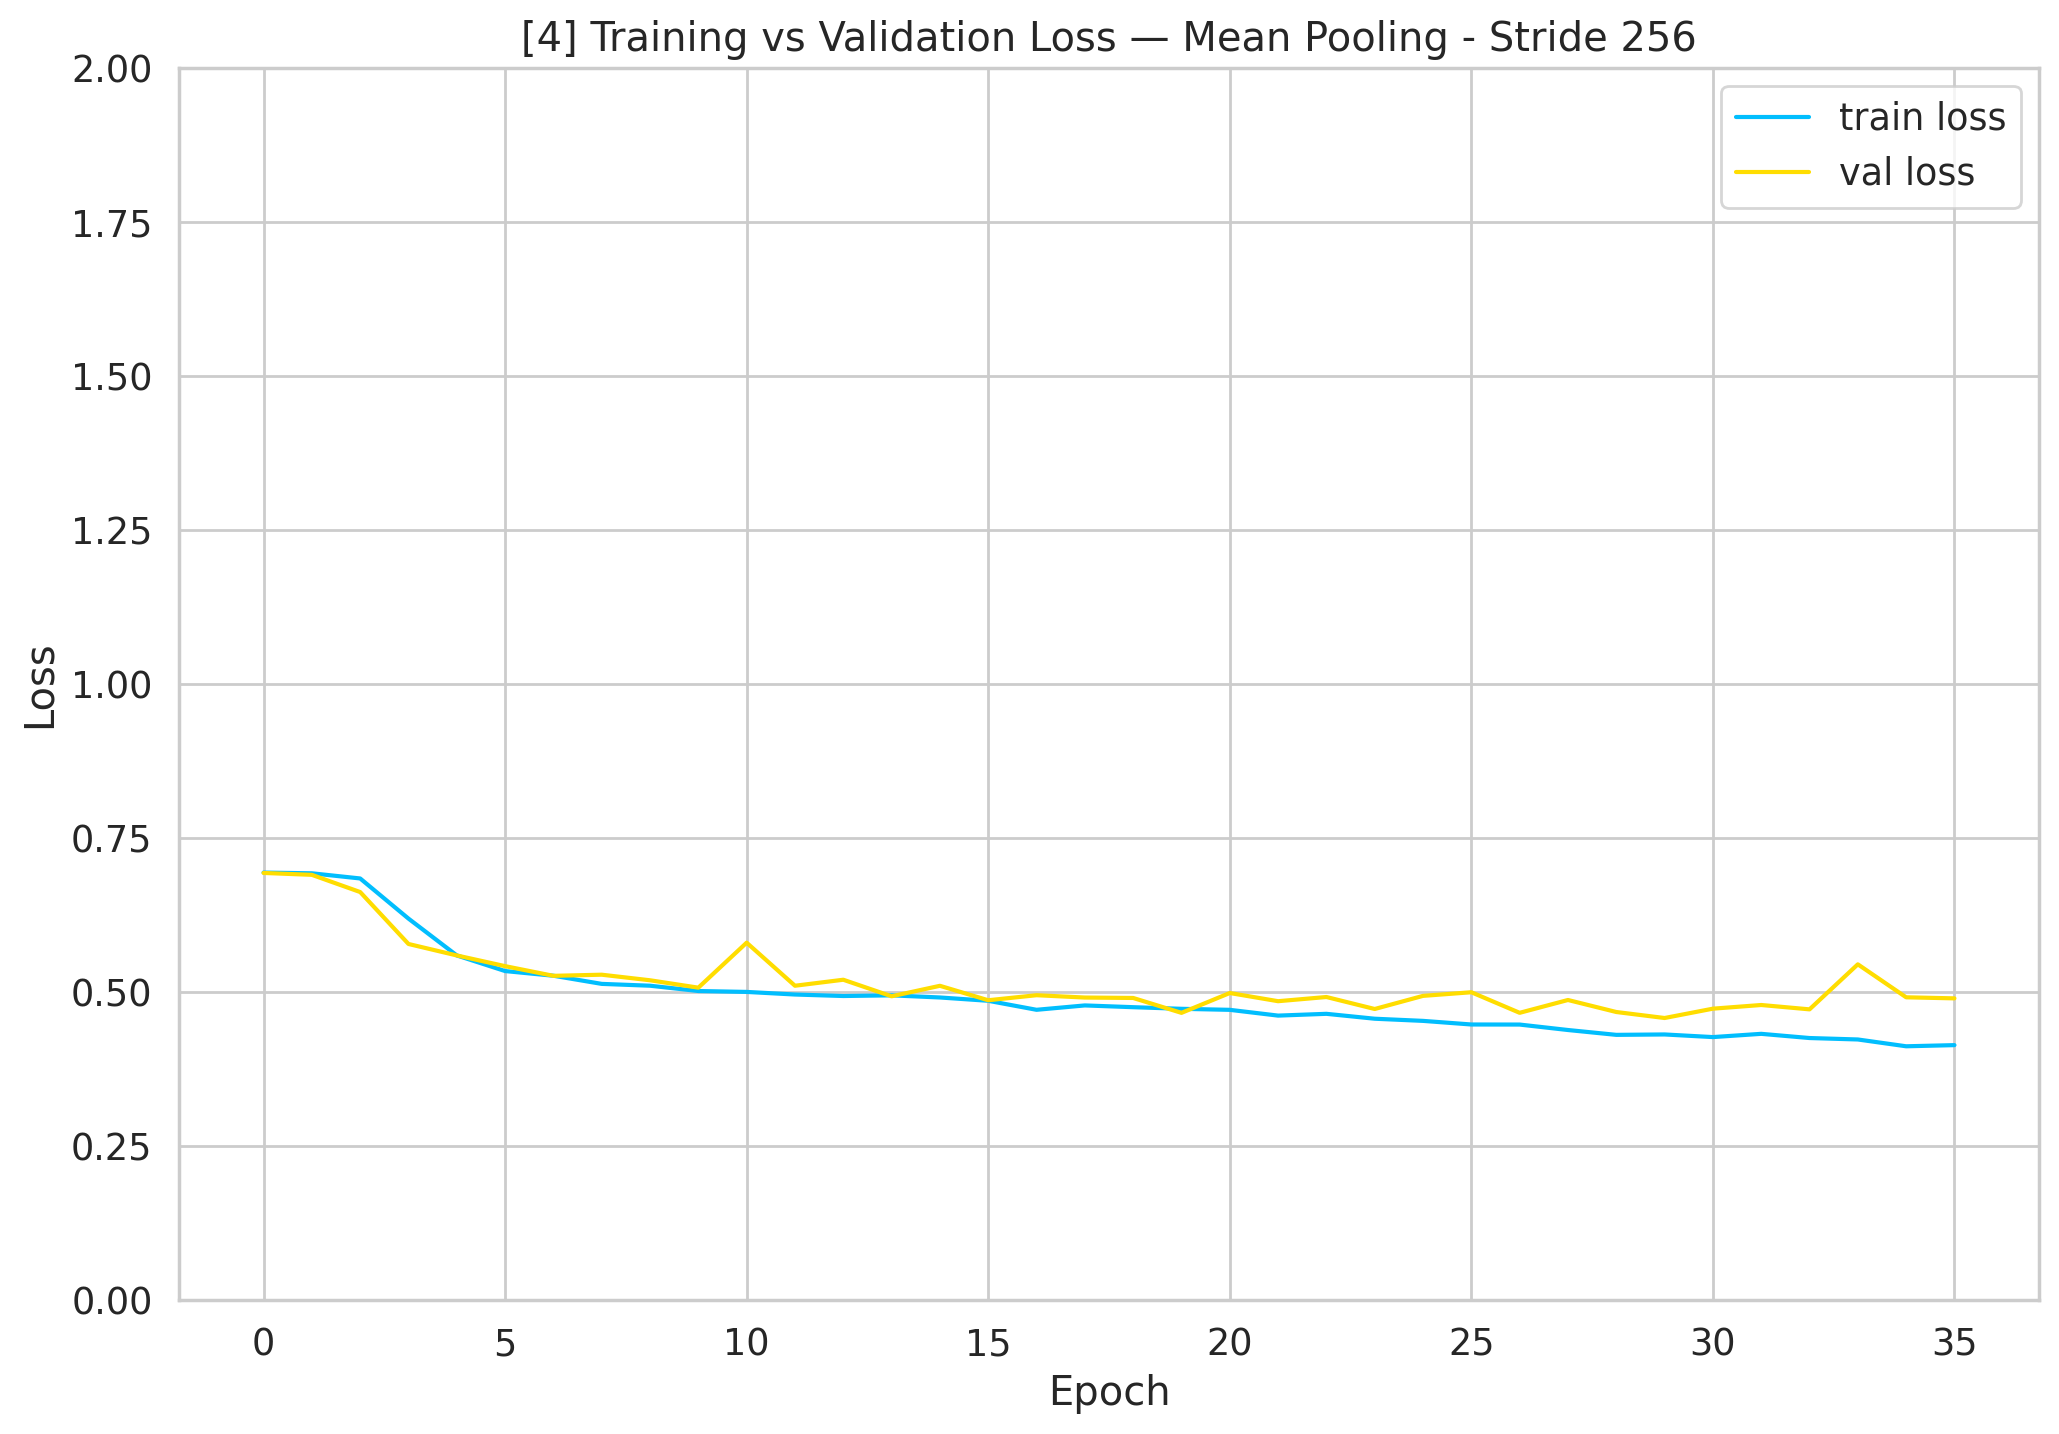


  Métricas Finais — [4] Mean Pooling - Stride 256
  Accuracy:  0.8062
  Precision: 0.8075
  Recall:    0.8062
  F1-Score:  0.8060

  Classification Report — [4] Mean Pooling - Stride 256
                     precision    recall  f1-score   support

Desfavorável ao Réu       0.79      0.84      0.81       545
   Favorável ao Réu       0.83      0.77      0.80       544

           accuracy                           0.81      1089
          macro avg       0.81      0.81      0.81      1089
       weighted avg       0.81      0.81      0.81      1089



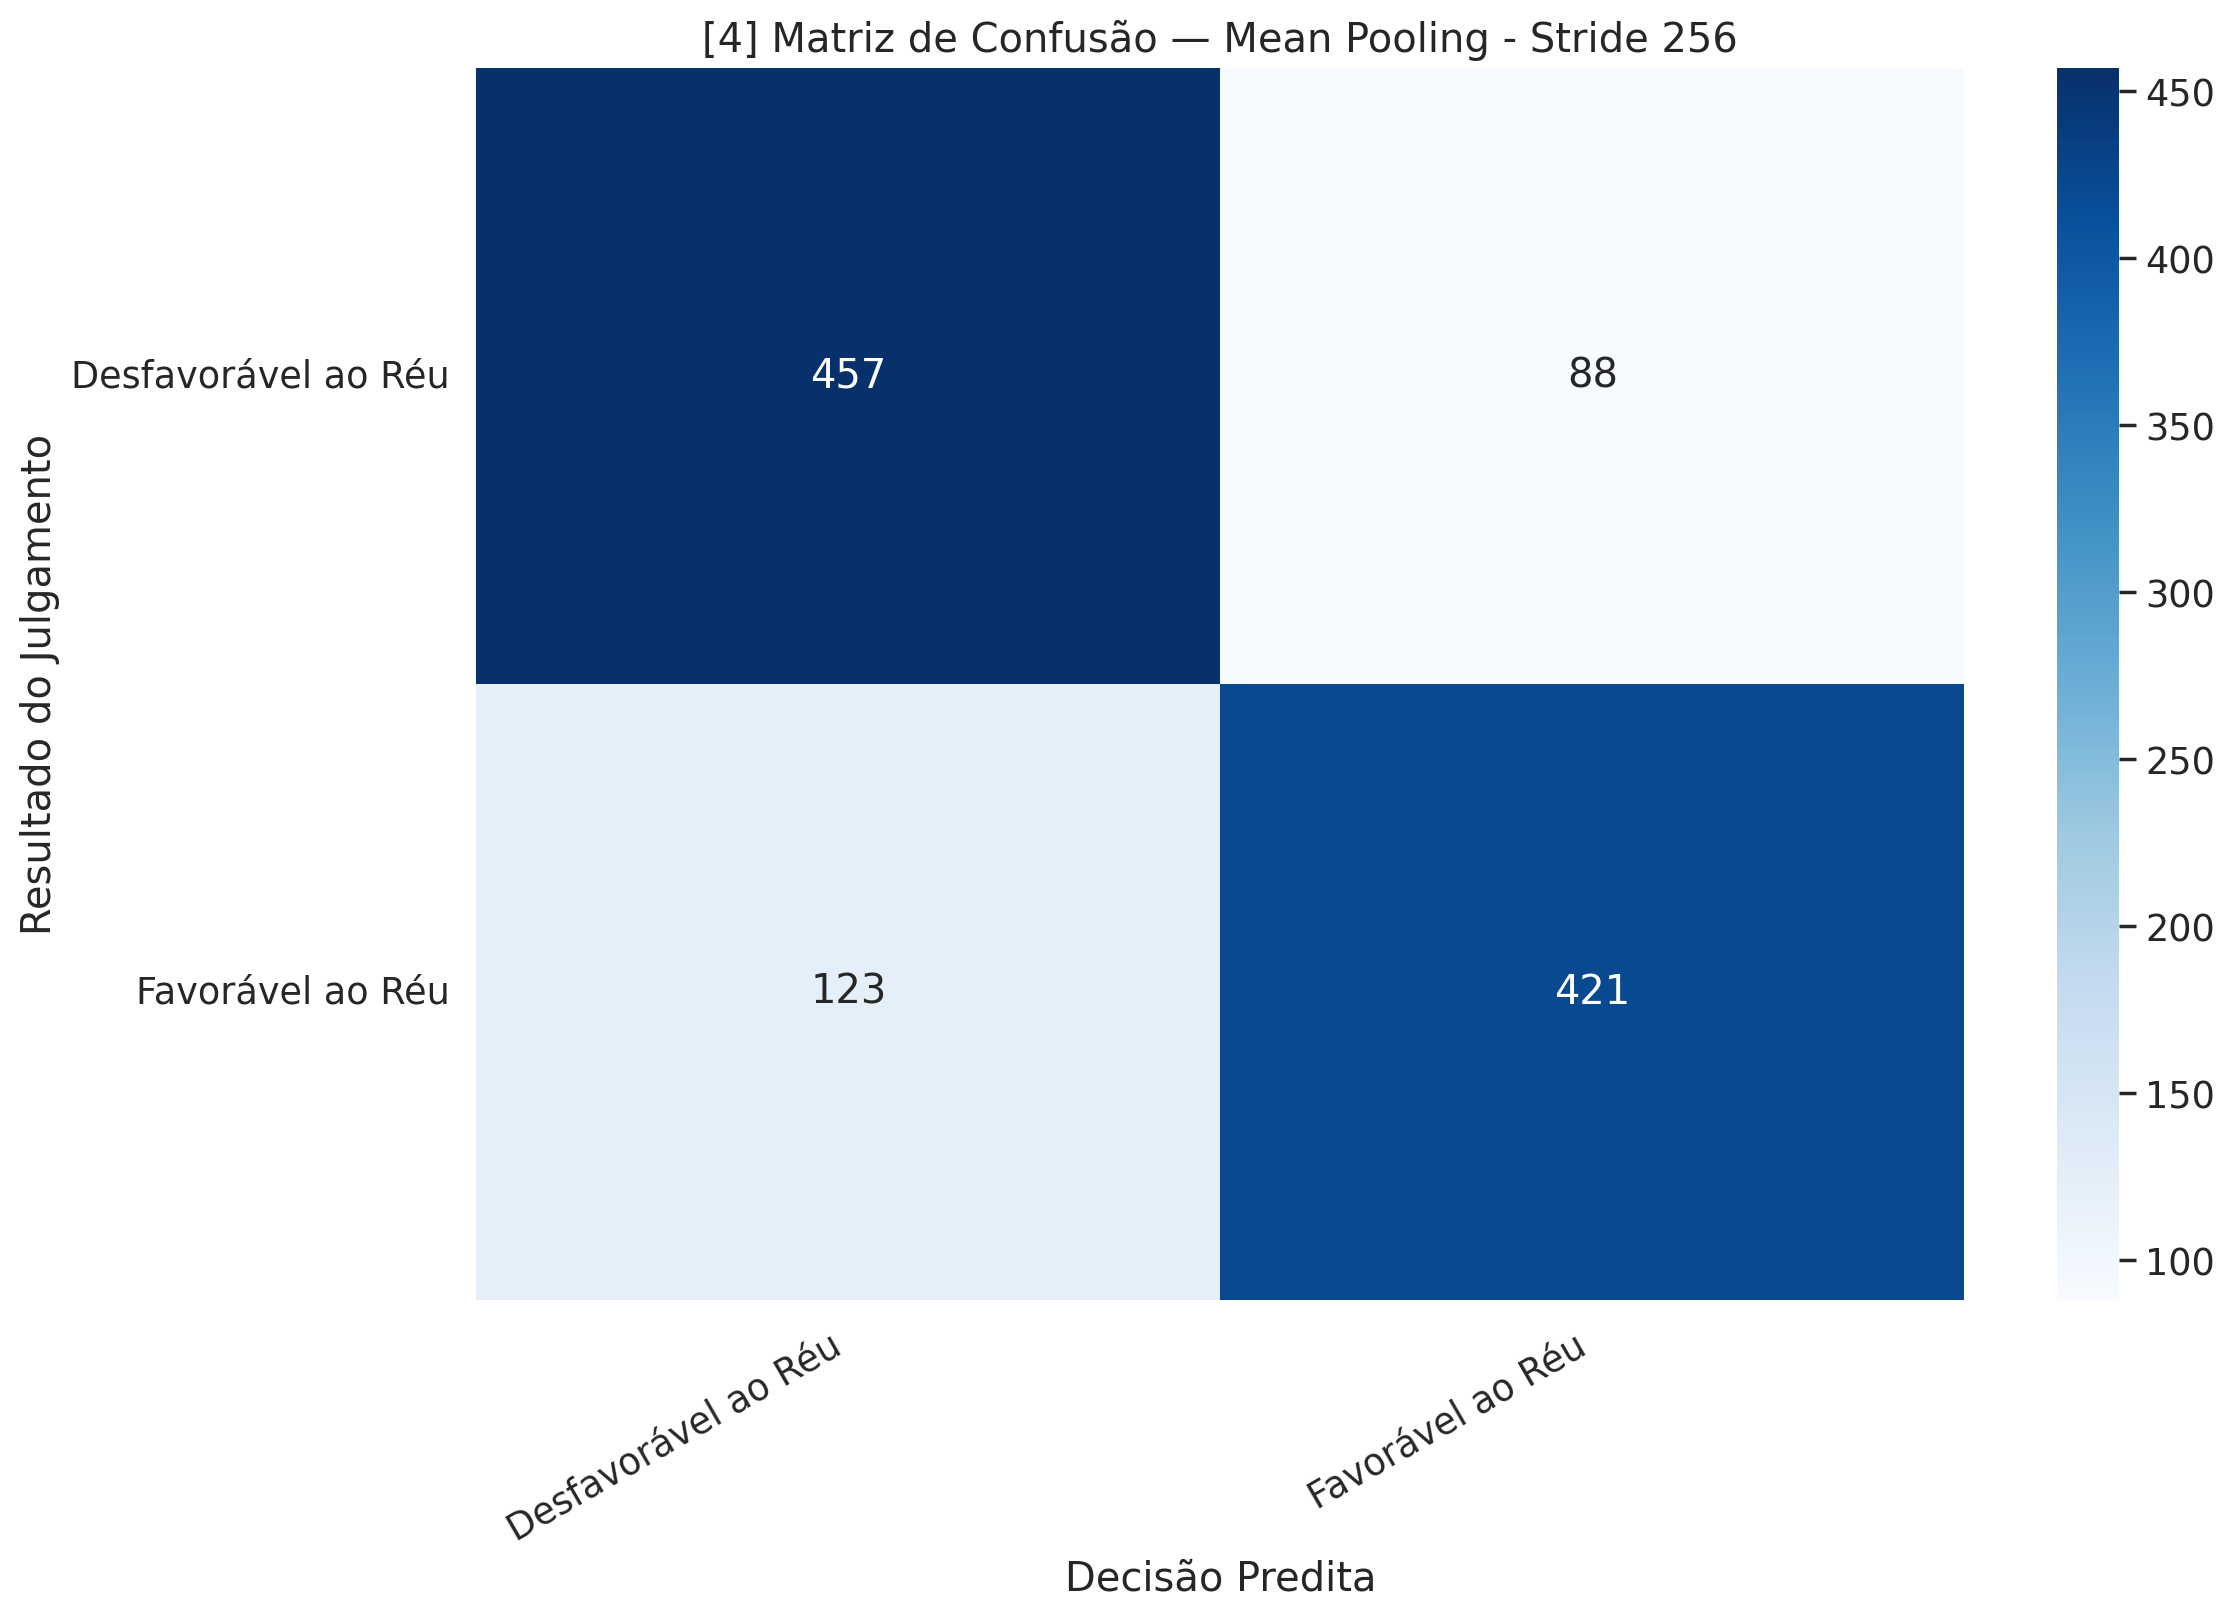

  FPR: 0.1615


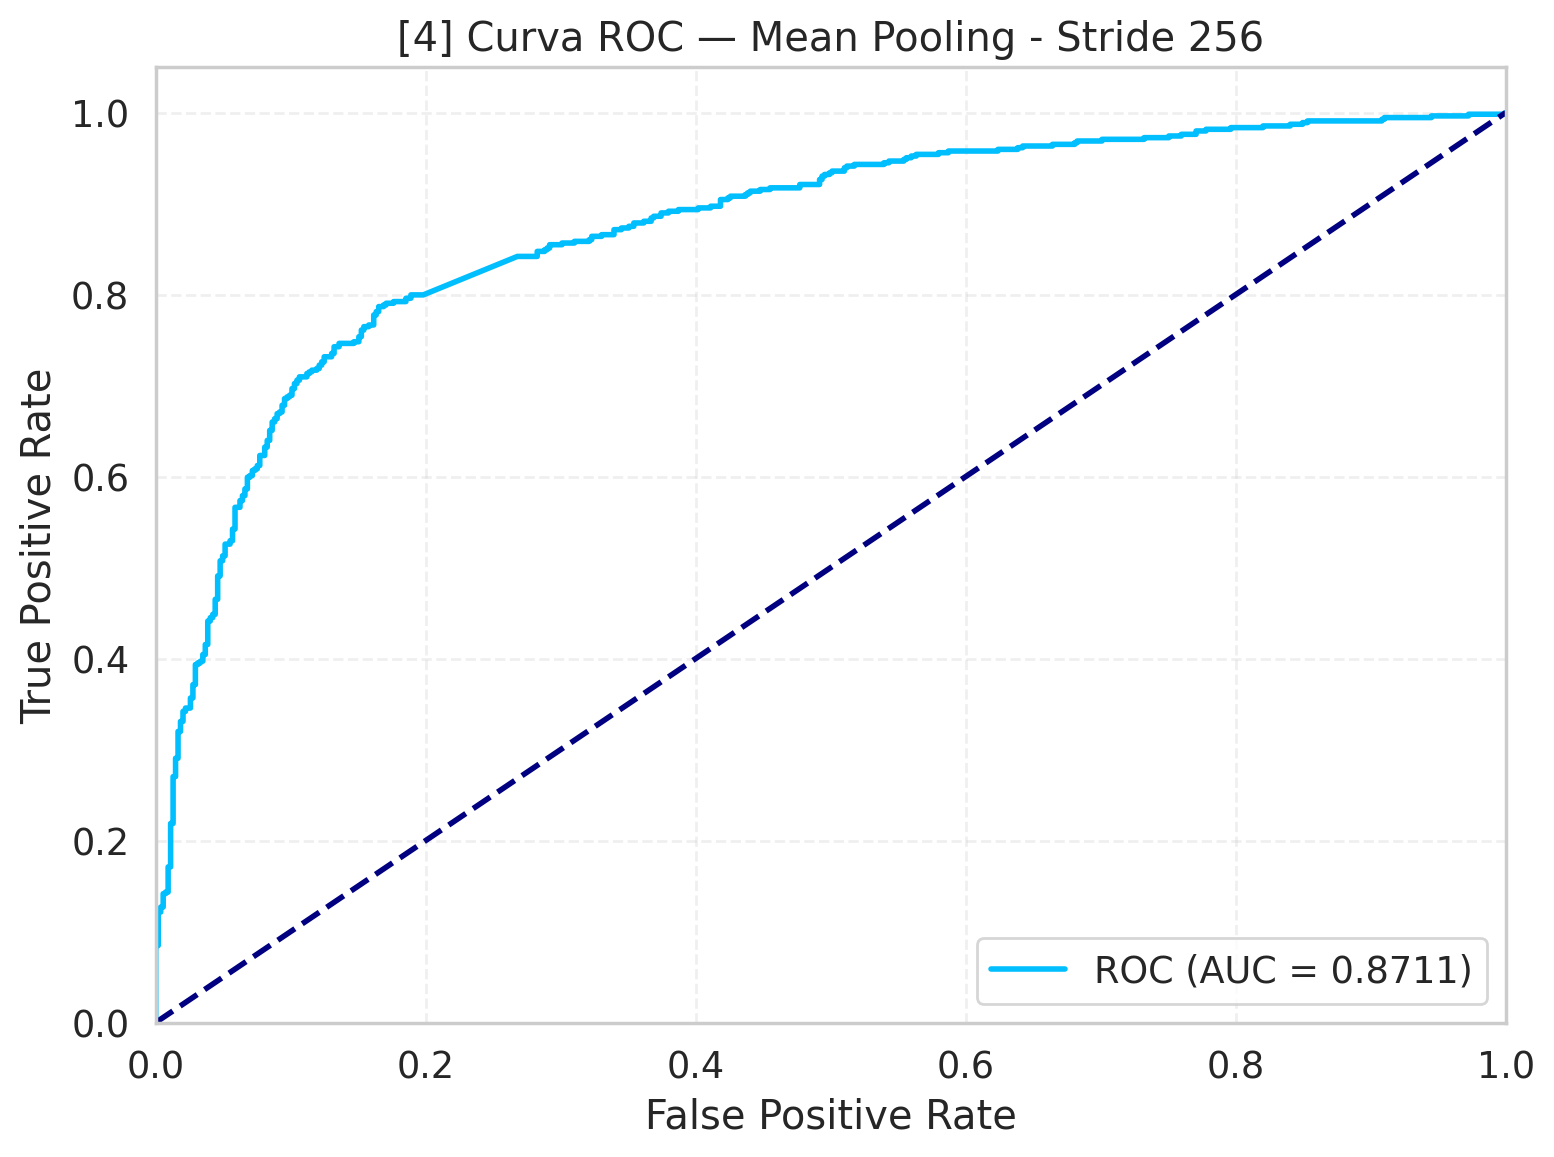

  AUC: 0.8711

[5/7] [5] Max Pooling - Stride 0
  Modelo: raquelsilveira/legalbertpt_fp | chunk_size=512 | stride=512 | min_chunk_tokens=64 | max_chunks=None | pooling=max
  [Dataset] Documentos: 4356
  [Dataset] Chunks/doc antes do filtro (min=64):  1.36  (total=5915)
  [Dataset] Chunks/doc ap?s  filtro (min=64):  1.31  (removidos=230, 3.9%)
  [Dataset] max_chunks=None ? sem limita??o adicional
  [Dataset] Documentos: 1089
  [Dataset] Chunks/doc antes do filtro (min=64):  1.32  (total=1436)
  [Dataset] Chunks/doc ap?s  filtro (min=64):  1.28  (removidos=40, 2.8%)
  [Dataset] max_chunks=None ? sem limita??o adicional


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: raquelsilveira/legalbertpt_fp
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Freezing embeddings + first 12 encoder layers...
Layers freezing complete.

  Epoch 1/200
  ------------------------------------------------------------
  Train | loss 0.6930 acc 0.5005 prec 0.2502 rec 0.5000 f1 0.3335
  Test  | loss 0.6924 acc 0.5005 prec 0.2502 rec 0.5000 f1 0.3335

  Epoch 2/200
  ------------------------------------------------------------
  Train | loss 0.6916 acc 0.5170 prec 0.5887 rec 0.5166 f1 0.3934
  Test  | loss 0.6889 acc 0.5399 prec 0.6622 rec 0.5395 f1 0.4324

  Epoch 3/200
  ------------------------------------------------------------
  Train | loss 0.6832 acc 0.5969 prec 0.6333 rec 0.5966 f1 0.5670
  Test  | loss 0.6604 acc 0.6951 prec 0.6971 rec 0.6952 f1 0.6944

  Epoch 4/200
  ------------------------------------------------------------
  Train | loss 0.6133 acc 0.7075 prec 0.7076 rec 0.7075 f1 0.7075
  Test  | loss 0.5702 acc 0.7319 prec 0.7365 rec 0.7318 f1 0.7305

  Epoch 5/200
  ------------------------------------------------------------
  Train

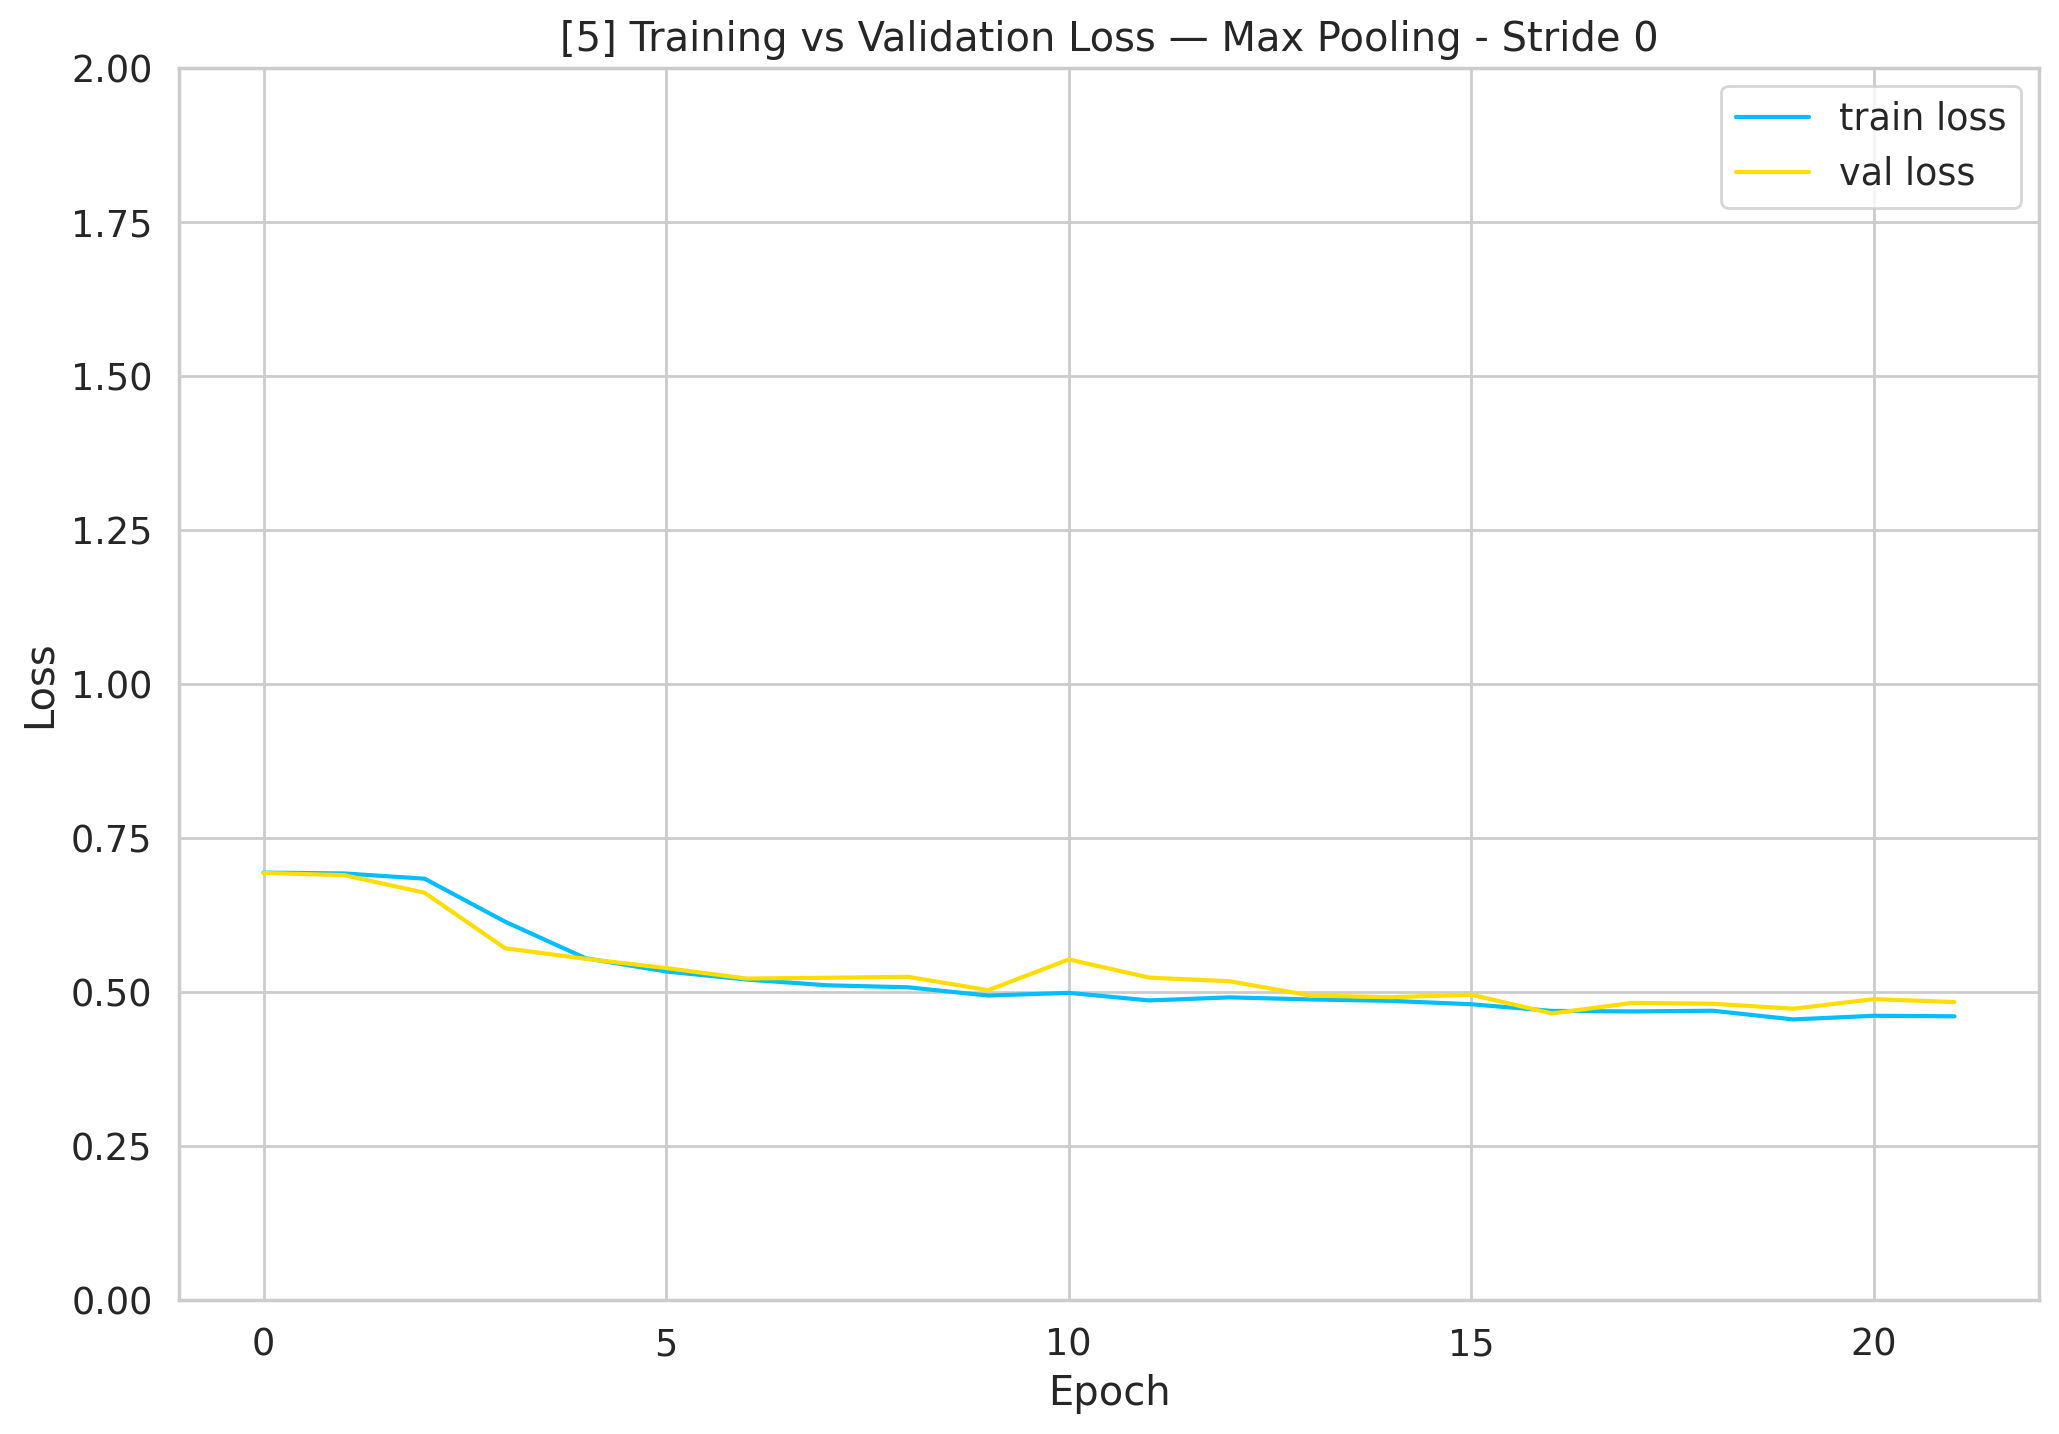


  Métricas Finais — [5] Max Pooling - Stride 0
  Accuracy:  0.7971
  Precision: 0.7999
  Recall:    0.7970
  F1-Score:  0.7966

  Classification Report — [5] Max Pooling - Stride 0
                     precision    recall  f1-score   support

Desfavorável ao Réu       0.77      0.85      0.81       545
   Favorável ao Réu       0.83      0.75      0.79       544

           accuracy                           0.80      1089
          macro avg       0.80      0.80      0.80      1089
       weighted avg       0.80      0.80      0.80      1089



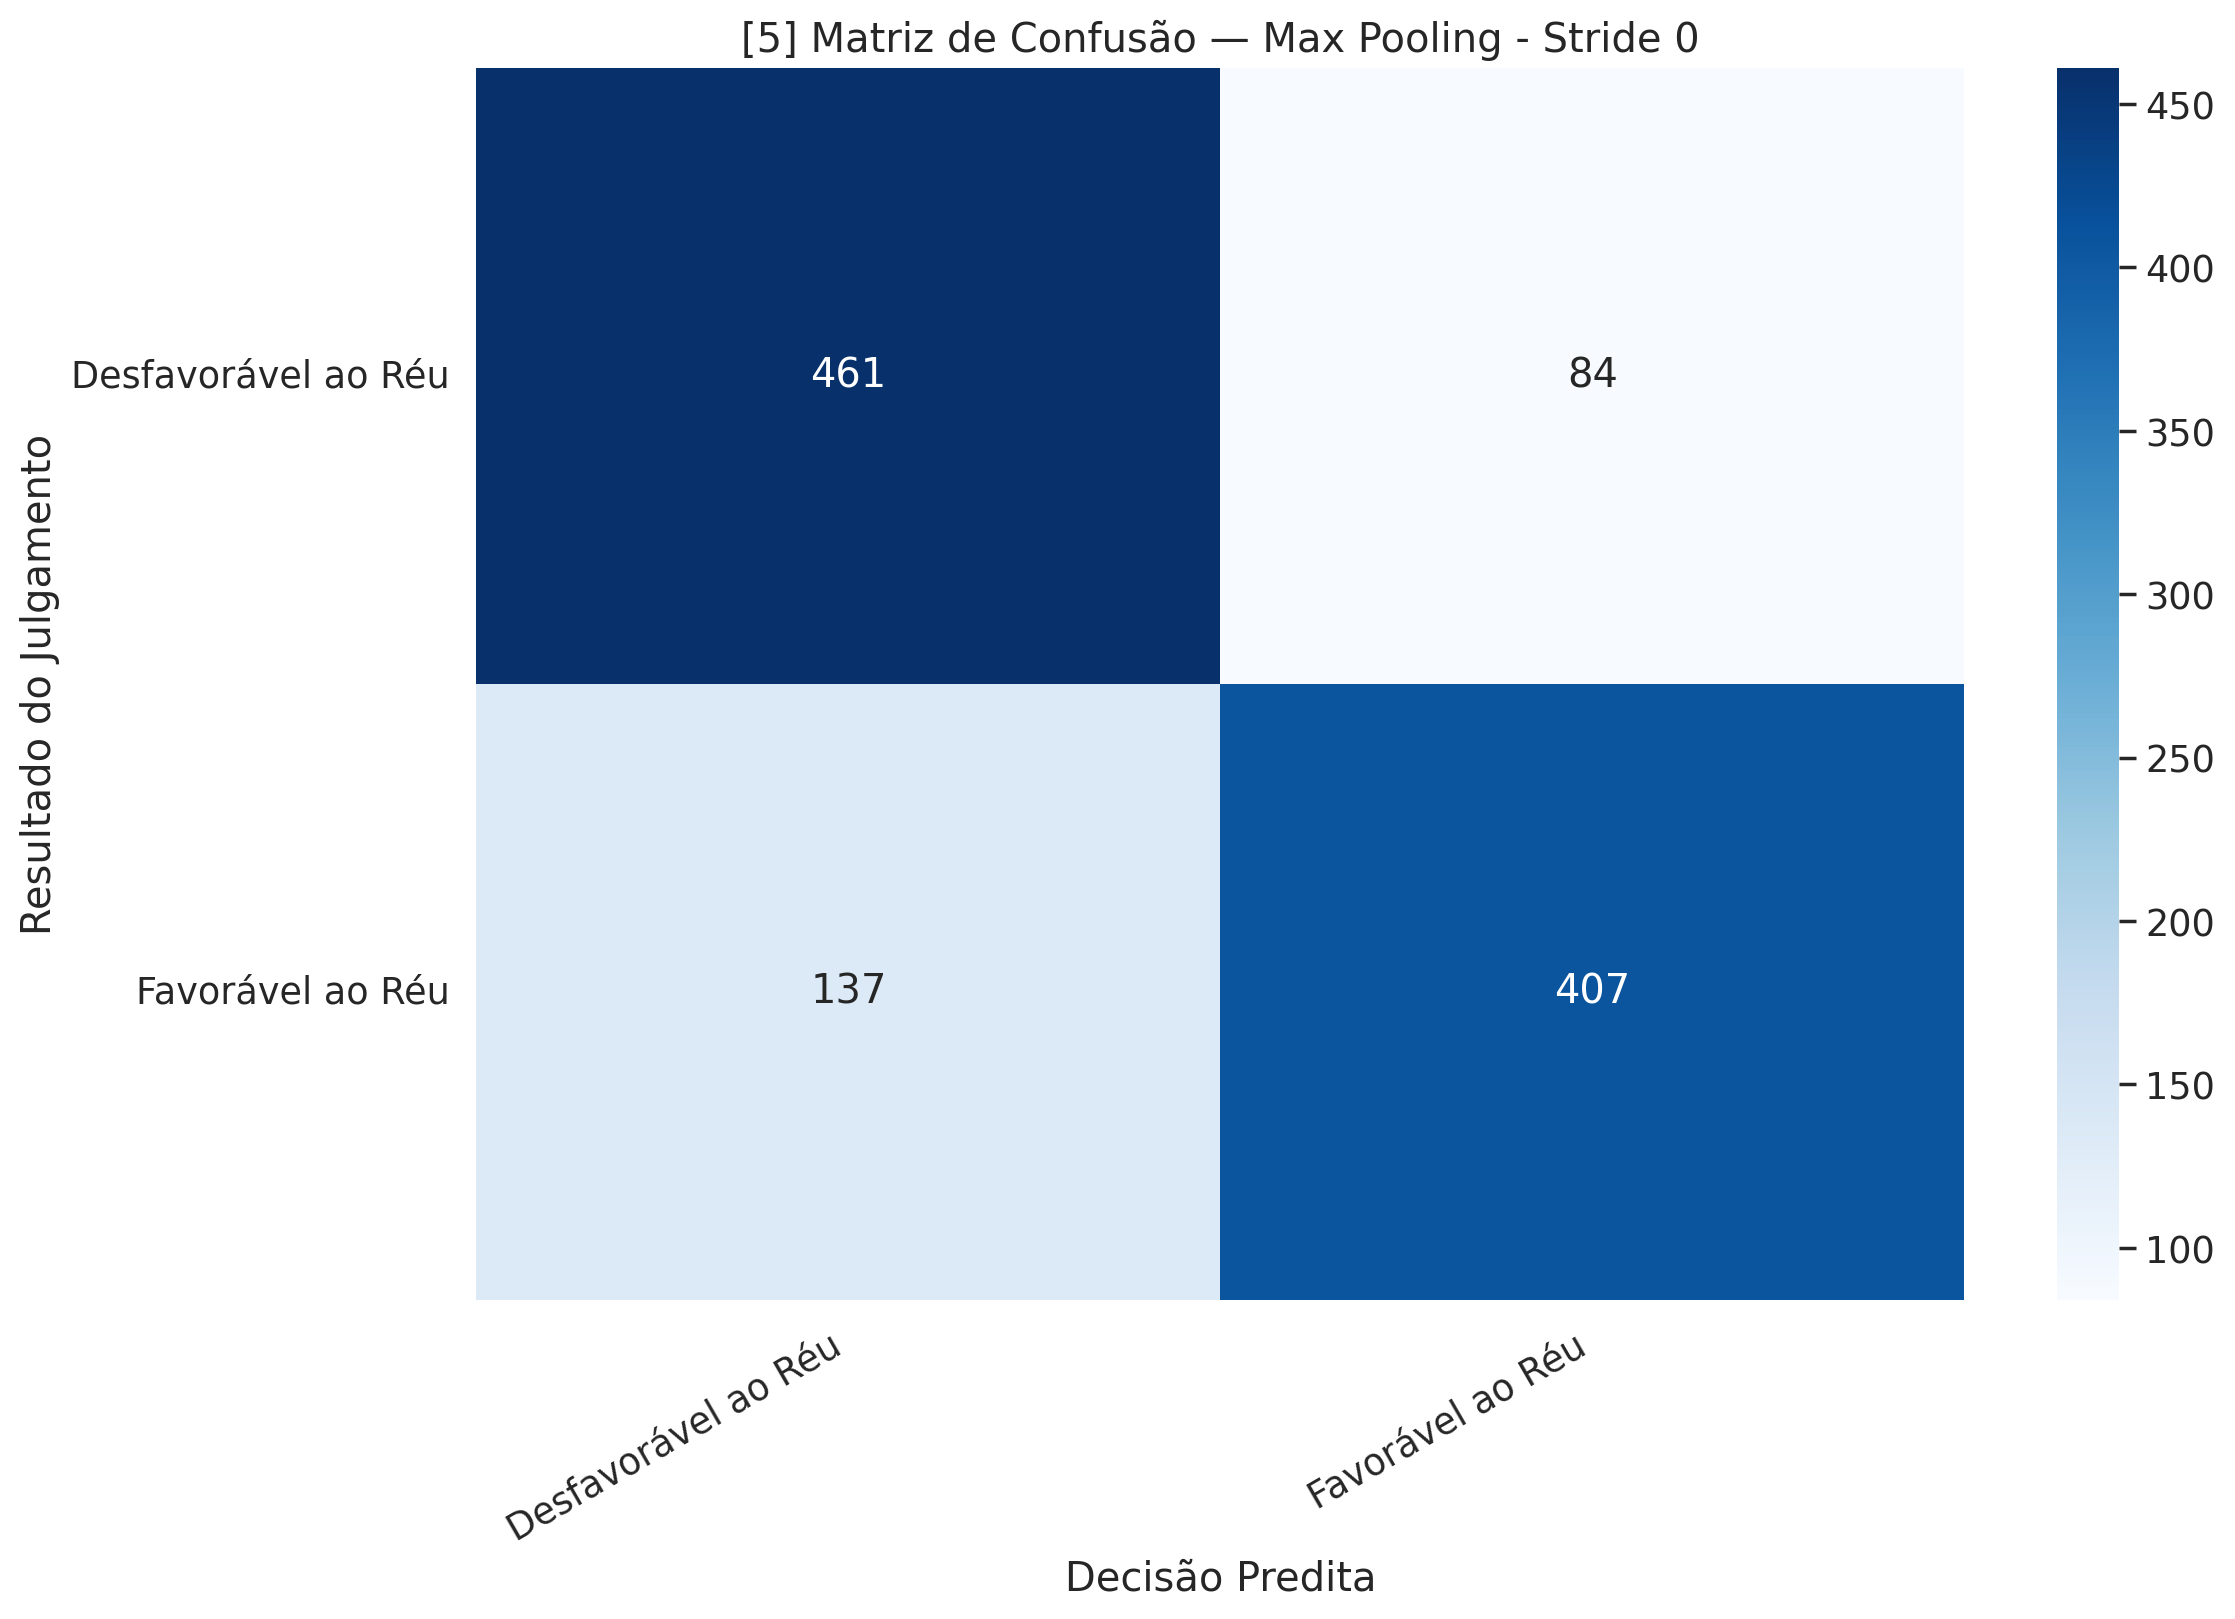

  FPR: 0.1541


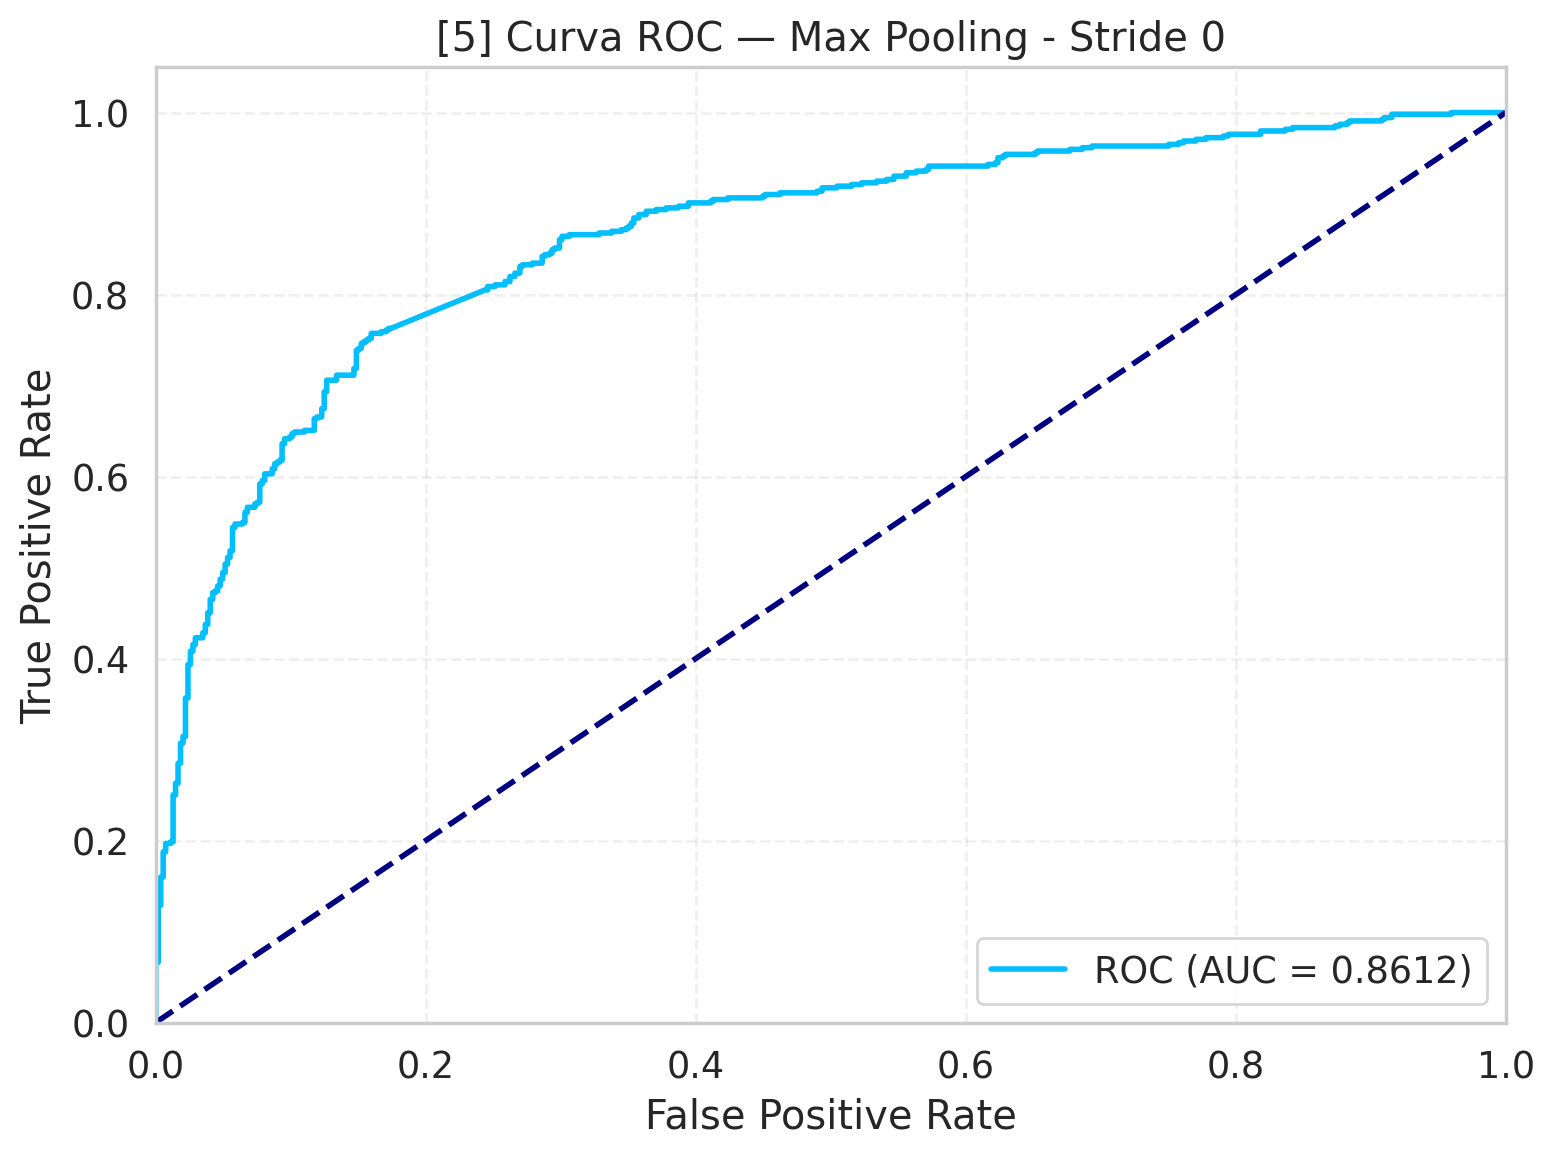

  AUC: 0.8612

[6/7] [6] Max Pooling - Stride 128
  Modelo: raquelsilveira/legalbertpt_fp | chunk_size=512 | stride=128 | min_chunk_tokens=64 | max_chunks=None | pooling=max
  [Dataset] Documentos: 4356
  [Dataset] Chunks/doc antes do filtro (min=64):  1.96  (total=8556)
  [Dataset] Chunks/doc ap?s  filtro (min=64):  1.96  (removidos=0, 0.0%)
  [Dataset] max_chunks=None ? sem limita??o adicional
  [Dataset] Documentos: 1089
  [Dataset] Chunks/doc antes do filtro (min=64):  1.85  (total=2013)
  [Dataset] Chunks/doc ap?s  filtro (min=64):  1.85  (removidos=0, 0.0%)
  [Dataset] max_chunks=None ? sem limita??o adicional


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: raquelsilveira/legalbertpt_fp
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Freezing embeddings + first 12 encoder layers...
Layers freezing complete.

  Epoch 1/200
  ------------------------------------------------------------
  Train | loss 0.6931 acc 0.5007 prec 0.7503 rec 0.5002 f1 0.3340
  Test  | loss 0.6924 acc 0.5005 prec 0.2502 rec 0.5000 f1 0.3335

  Epoch 2/200
  ------------------------------------------------------------
  Train | loss 0.6916 acc 0.5154 prec 0.5716 rec 0.5150 f1 0.3956
  Test  | loss 0.6888 acc 0.5491 prec 0.6137 rec 0.5488 f1 0.4738

  Epoch 3/200
  ------------------------------------------------------------
  Train | loss 0.6822 acc 0.6072 prec 0.6358 rec 0.6070 f1 0.5851
  Test  | loss 0.6591 acc 0.6924 prec 0.6942 rec 0.6924 f1 0.6917

  Epoch 4/200
  ------------------------------------------------------------
  Train | loss 0.6196 acc 0.6977 prec 0.6977 rec 0.6977 f1 0.6977
  Test  | loss 0.5871 acc 0.7172 prec 0.7213 rec 0.7171 f1 0.7158

  Epoch 5/200
  ------------------------------------------------------------
  Train

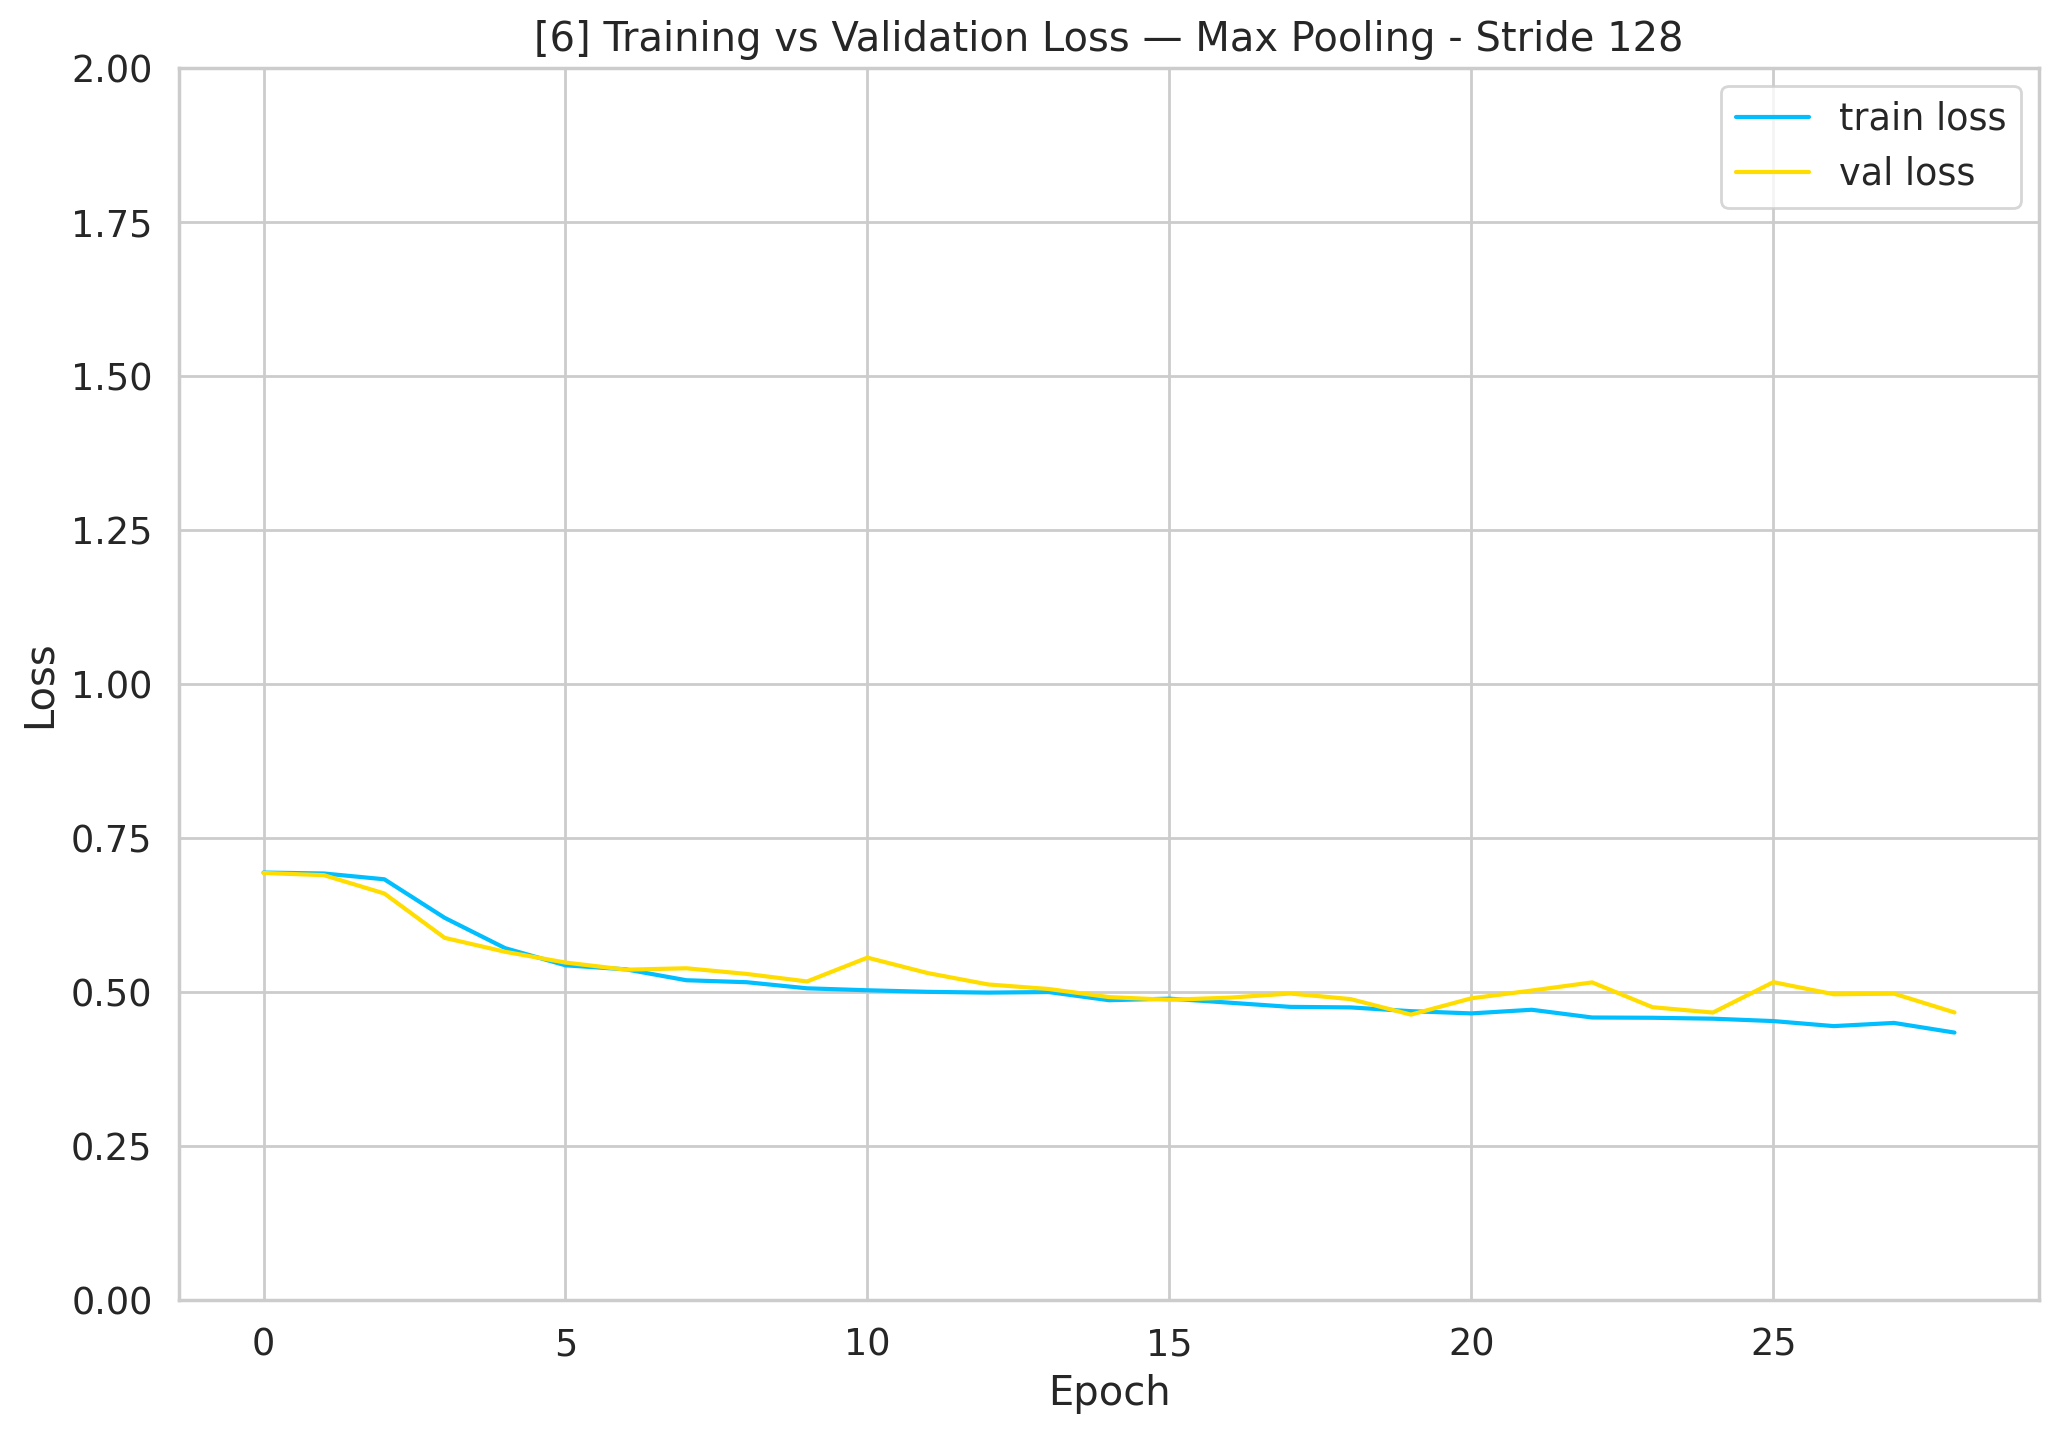


  Métricas Finais — [6] Max Pooling - Stride 128
  Accuracy:  0.7971
  Precision: 0.7989
  Recall:    0.7970
  F1-Score:  0.7967

  Classification Report — [6] Max Pooling - Stride 128
                     precision    recall  f1-score   support

Desfavorável ao Réu       0.78      0.84      0.80       545
   Favorável ao Réu       0.82      0.76      0.79       544

           accuracy                           0.80      1089
          macro avg       0.80      0.80      0.80      1089
       weighted avg       0.80      0.80      0.80      1089



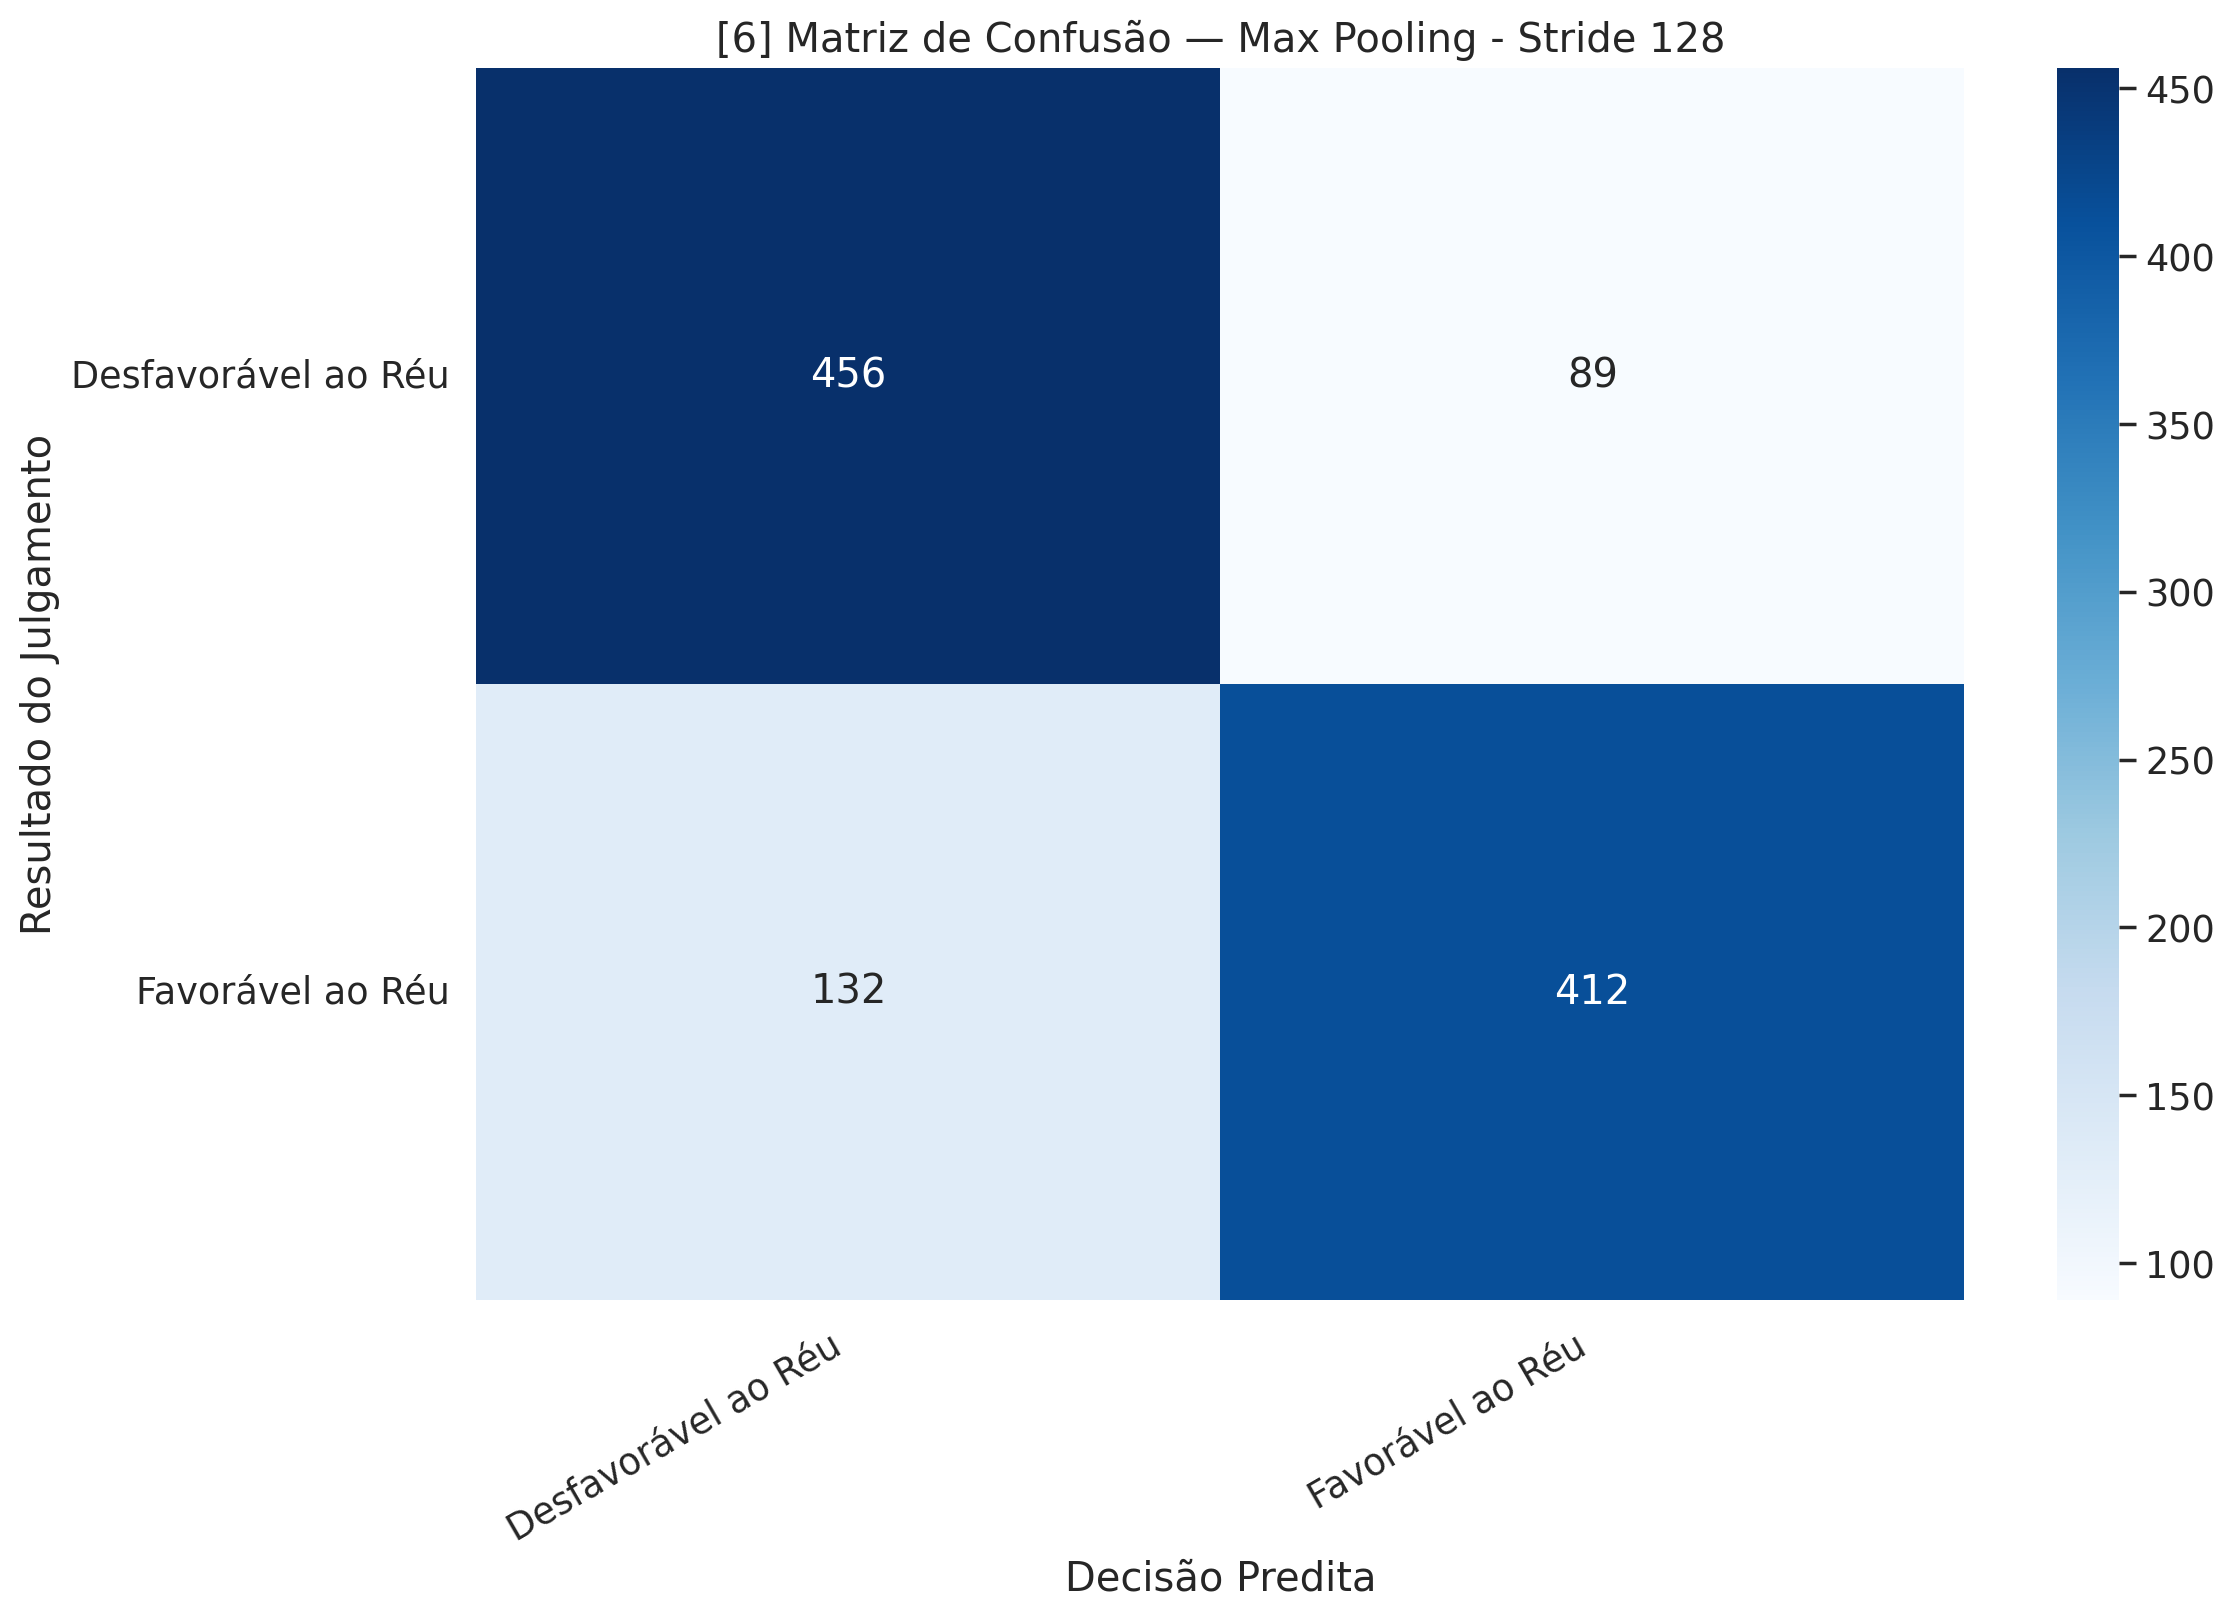

  FPR: 0.1633


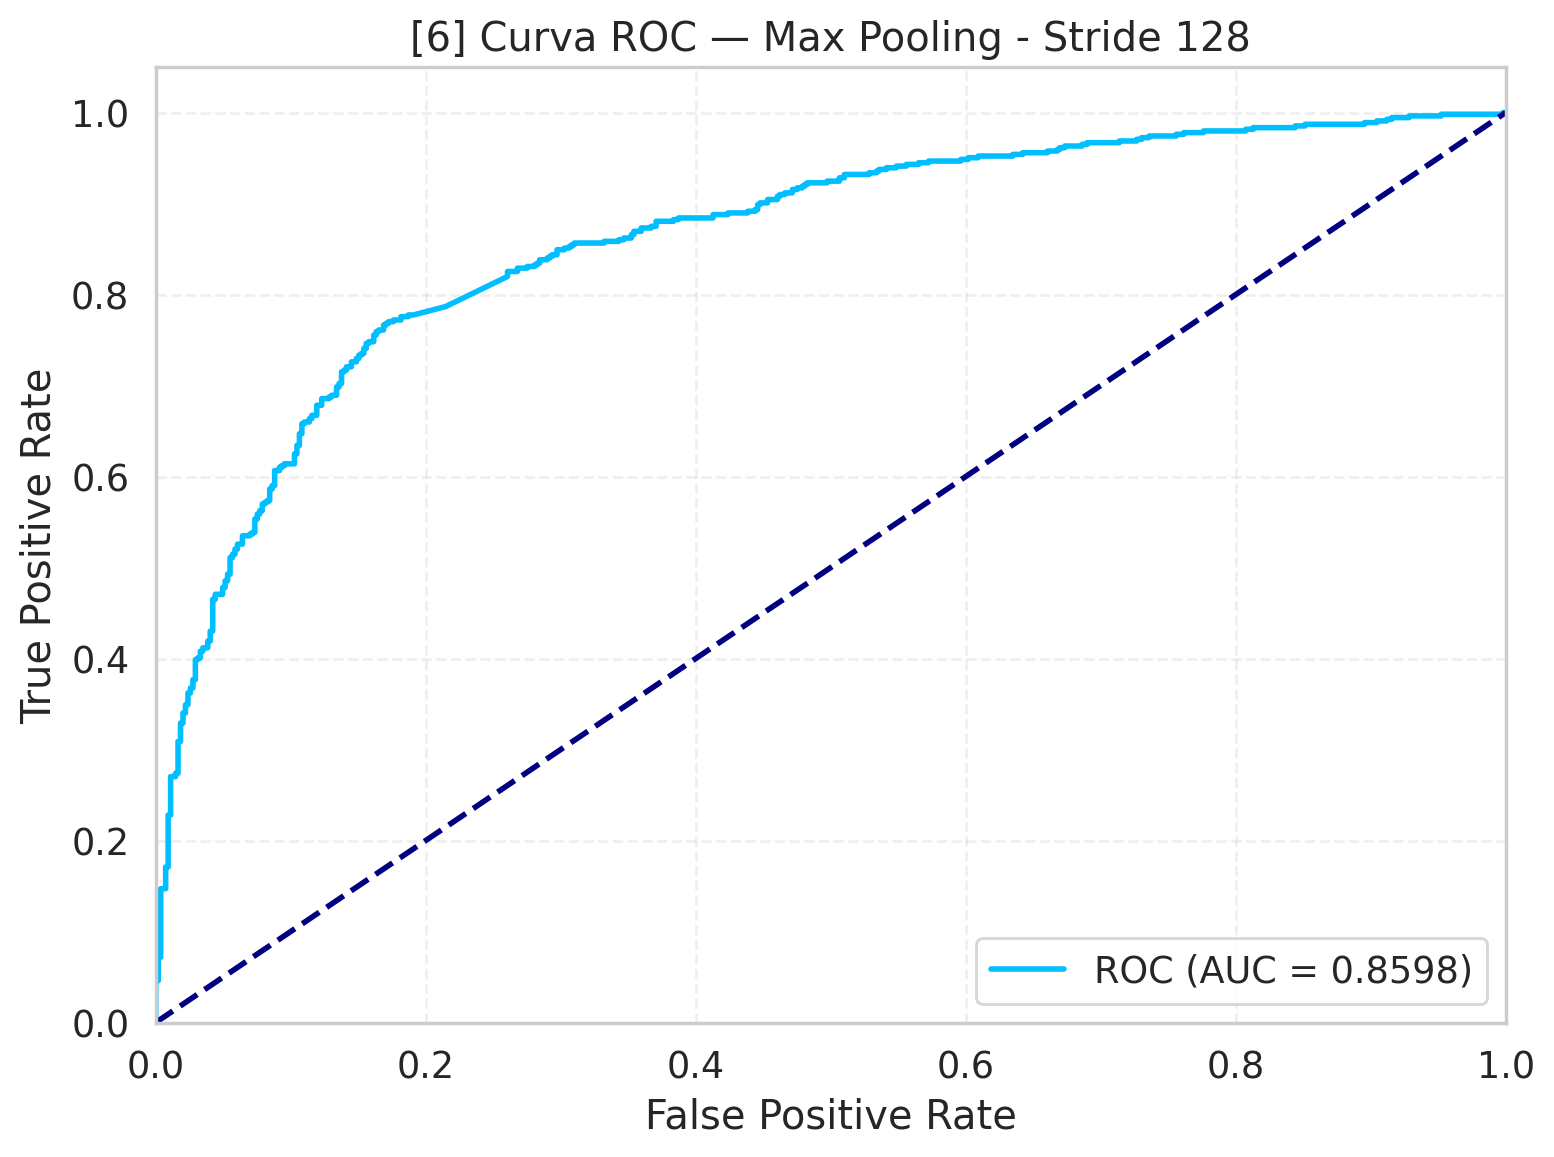

  AUC: 0.8598

[7/7] [7] Max Pooling - Stride 256
  Modelo: raquelsilveira/legalbertpt_fp | chunk_size=512 | stride=256 | min_chunk_tokens=64 | max_chunks=None | pooling=max
  [Dataset] Documentos: 4356
  [Dataset] Chunks/doc antes do filtro (min=64):  1.56  (total=6787)
  [Dataset] Chunks/doc ap?s  filtro (min=64):  1.56  (removidos=0, 0.0%)
  [Dataset] max_chunks=None ? sem limita??o adicional
  [Dataset] Documentos: 1089
  [Dataset] Chunks/doc antes do filtro (min=64):  1.48  (total=1617)
  [Dataset] Chunks/doc ap?s  filtro (min=64):  1.48  (removidos=0, 0.0%)
  [Dataset] max_chunks=None ? sem limita??o adicional


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: raquelsilveira/legalbertpt_fp
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Freezing embeddings + first 12 encoder layers...
Layers freezing complete.

  Epoch 1/200
  ------------------------------------------------------------
  Train | loss 0.6930 acc 0.5005 prec 0.2502 rec 0.5000 f1 0.3335
  Test  | loss 0.6924 acc 0.5005 prec 0.2502 rec 0.5000 f1 0.3335

  Epoch 2/200
  ------------------------------------------------------------
  Train | loss 0.6916 acc 0.5174 prec 0.5928 rec 0.5170 f1 0.3934
  Test  | loss 0.6890 acc 0.5482 prec 0.6460 rec 0.5478 f1 0.4567

  Epoch 3/200
  ------------------------------------------------------------
  Train | loss 0.6820 acc 0.6111 prec 0.6425 rec 0.6109 f1 0.5882
  Test  | loss 0.6582 acc 0.6942 prec 0.6956 rec 0.6943 f1 0.6937

  Epoch 4/200
  ------------------------------------------------------------
  Train | loss 0.6176 acc 0.7034 prec 0.7034 rec 0.7034 f1 0.7034
  Test  | loss 0.5825 acc 0.7208 prec 0.7257 rec 0.7208 f1 0.7193

  Epoch 5/200
  ------------------------------------------------------------
  Train

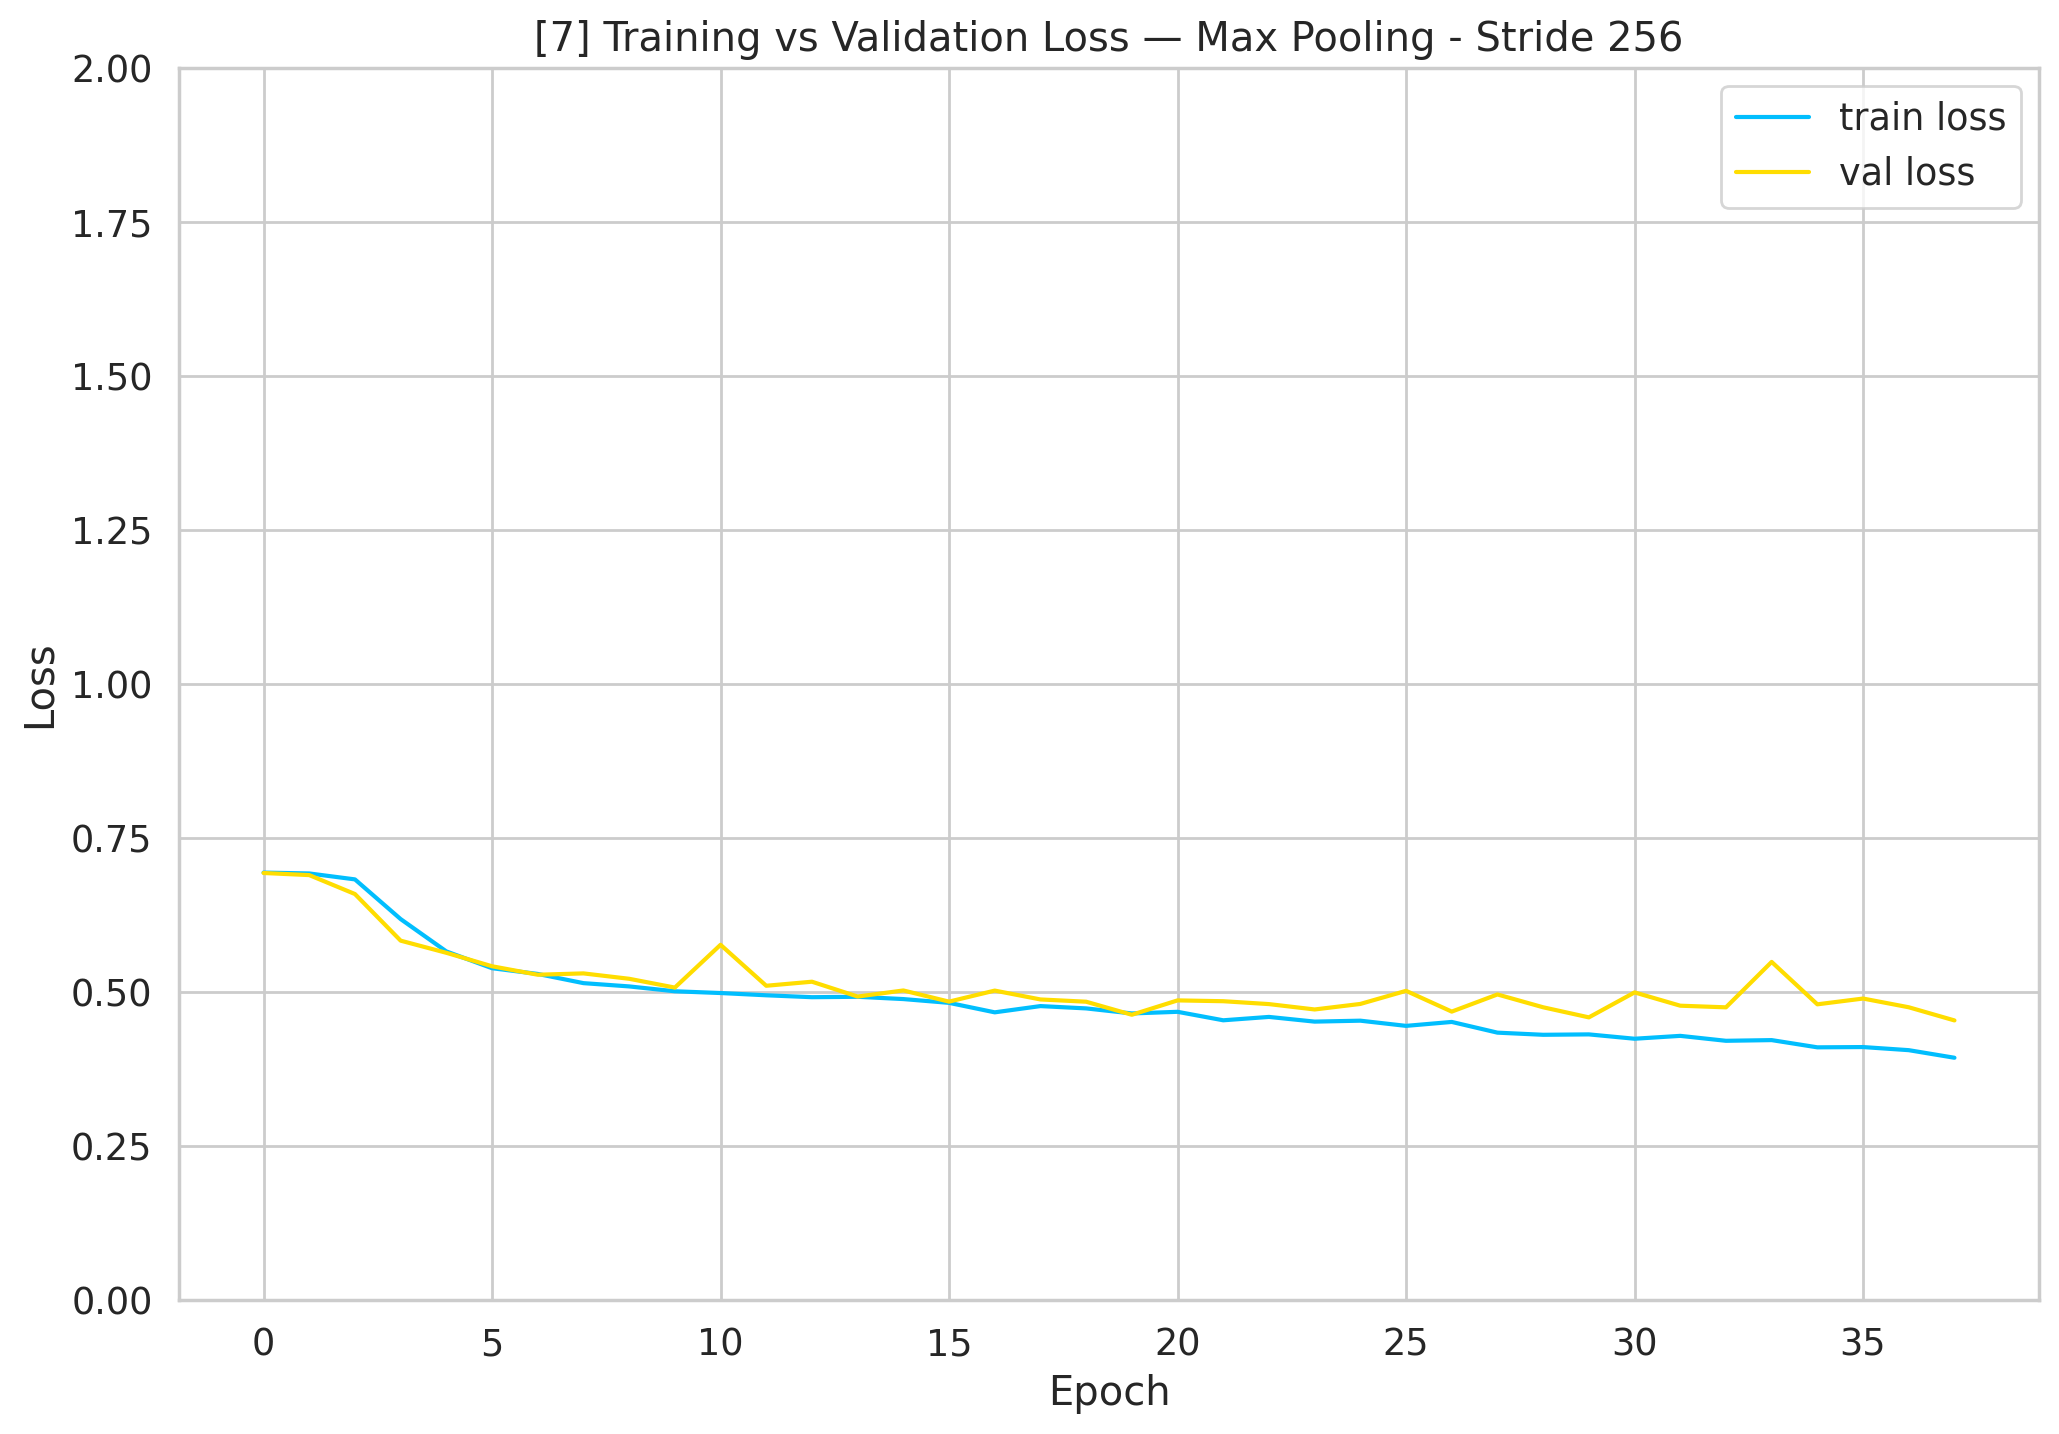


  Métricas Finais — [7] Max Pooling - Stride 256
  Accuracy:  0.8099
  Precision: 0.8131
  Recall:    0.8099
  F1-Score:  0.8094

  Classification Report — [7] Max Pooling - Stride 256
                     precision    recall  f1-score   support

Desfavorável ao Réu       0.78      0.86      0.82       545
   Favorável ao Réu       0.84      0.76      0.80       544

           accuracy                           0.81      1089
          macro avg       0.81      0.81      0.81      1089
       weighted avg       0.81      0.81      0.81      1089



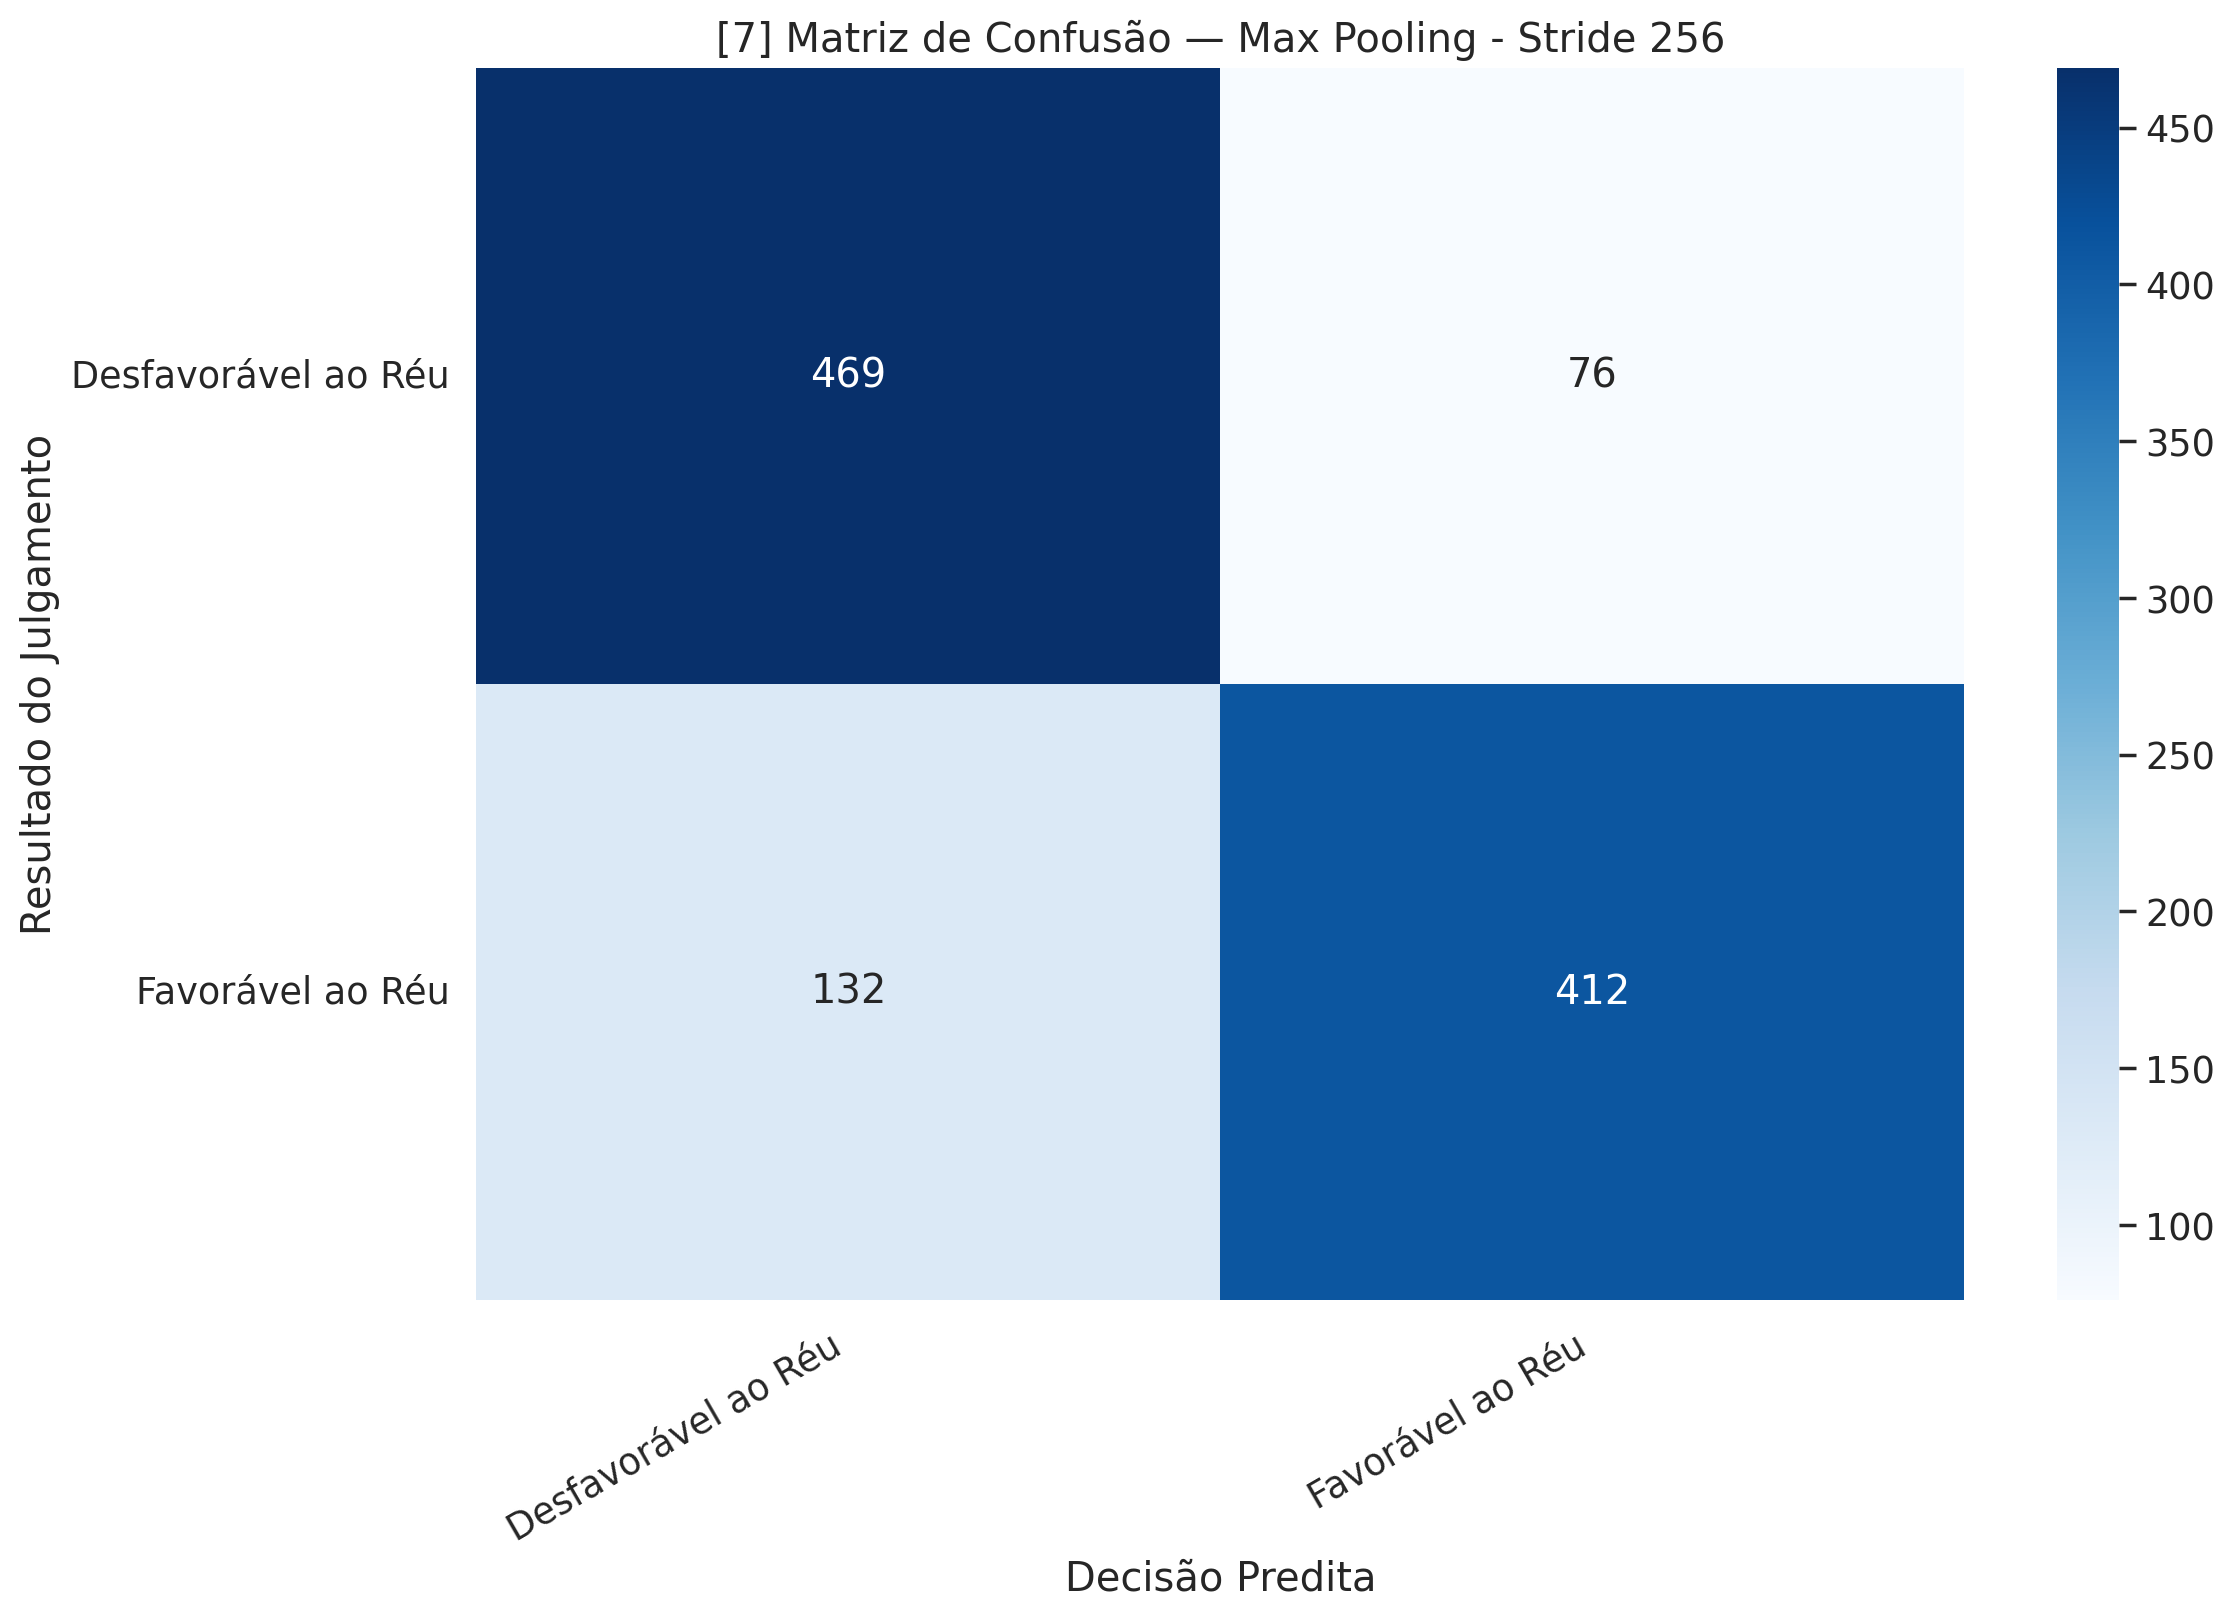

  FPR: 0.1394


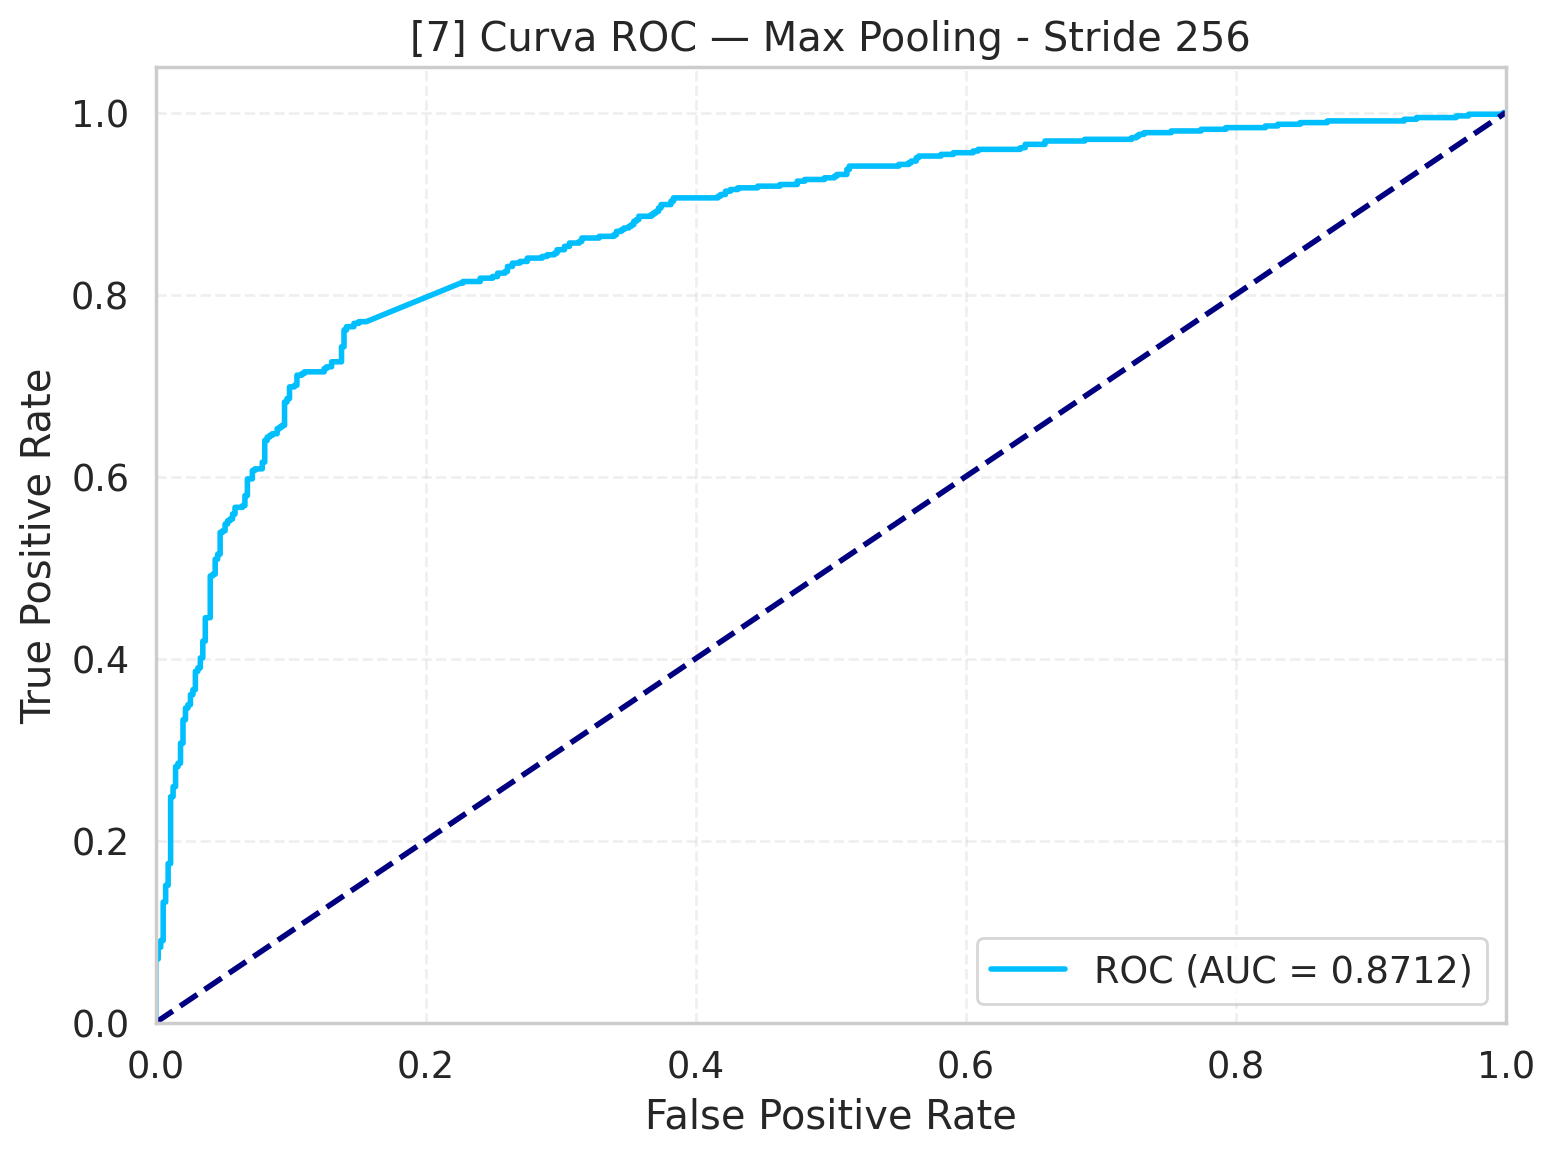

  AUC: 0.8712


Trade-off concluído — 7 abordagens (Truncation | Mean/Max Pooling × Stride 0/128/256).
CPU times: user 52min 26s, sys: 1min 55s, total: 54min 21s
Wall time: 51min 48s


In [12]:
%%time
import os, gc, copy
from collections import defaultdict
from torch.optim import AdamW
from sklearn.metrics import precision_score, recall_score, f1_score
import torch.nn.functional as F
from sklearn.metrics import roc_curve, auc

# ---------------------------------------------------------------------------
# Funções auxiliares
# ---------------------------------------------------------------------------
def train_epoch(model, data_loader, loss_fn, optimizer, device, scheduler, n_examples, scaler, use_amp):
    model.train()
    losses, correct_predictions = [], 0
    all_preds, all_targets = [], []
    optimizer.zero_grad(set_to_none=True)

    for d in data_loader:
        input_ids = d["input_ids"].to(device, non_blocking=True)
        attention_mask = d["attention_mask"].to(device, non_blocking=True)
        targets = d["targets"].to(device, non_blocking=True)
        chunk_counts = d["chunk_counts"].to(device, non_blocking=True)

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, chunk_counts=chunk_counts)
            loss = loss_fn(outputs, targets)

        _, preds = torch.max(outputs, dim=1)
        correct_predictions += torch.sum(preds == targets)
        losses.append(loss.item())
        all_preds.extend(preds.detach().cpu().numpy())
        all_targets.extend(targets.detach().cpu().numpy())

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        optimizer.zero_grad(set_to_none=True)

    acc = (correct_predictions.double() / n_examples).item()
    return (acc, np.mean(losses),
            precision_score(all_targets, all_preds, average='macro', zero_division=0),
            recall_score(all_targets, all_preds, average='macro', zero_division=0),
            f1_score(all_targets, all_preds, average='macro', zero_division=0))


def eval_model(model, data_loader, loss_fn, device, n_examples, use_amp=False):
    model.eval()
    losses, correct_predictions = [], 0
    all_preds, all_targets = [], []

    with torch.no_grad():
        for d in data_loader:
            input_ids = d["input_ids"].to(device, non_blocking=True)
            attention_mask = d["attention_mask"].to(device, non_blocking=True)
            targets = d["targets"].to(device, non_blocking=True)
            chunk_counts = d["chunk_counts"].to(device, non_blocking=True)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                outputs = model(input_ids=input_ids, attention_mask=attention_mask, chunk_counts=chunk_counts)
                loss = loss_fn(outputs, targets)

            _, preds = torch.max(outputs, dim=1)
            correct_predictions += torch.sum(preds == targets)
            losses.append(loss.item())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    acc = (correct_predictions.double() / n_examples).item()
    return (acc, np.mean(losses),
            precision_score(all_targets, all_preds, average='macro', zero_division=0),
            recall_score(all_targets, all_preds, average='macro', zero_division=0),
            f1_score(all_targets, all_preds, average='macro', zero_division=0))


def get_predictions(model, data_loader, device):
    model.eval()
    predictions, prediction_probs, real_values = [], [], []
    with torch.no_grad():
        for d in data_loader:
            input_ids = d["input_ids"].to(device, non_blocking=True)
            attention_mask = d["attention_mask"].to(device, non_blocking=True)
            targets = d["targets"].to(device, non_blocking=True)
            chunk_counts = d["chunk_counts"].to(device, non_blocking=True)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, chunk_counts=chunk_counts)
            _, preds = torch.max(outputs, dim=1)
            predictions.extend(preds)
            prediction_probs.extend(outputs)
            real_values.extend(targets)
    return (torch.stack(predictions).cpu(),
            torch.stack(prediction_probs).cpu(),
            torch.stack(real_values).cpu())


# ---------------------------------------------------------------------------
# Loop de treinamento — Trade-off: Truncation vs Sliding Window
# ---------------------------------------------------------------------------
model_dir = f'{BASE_PATH_GENERAL}models'
os.makedirs(model_dir, exist_ok=True)

def build_model_save_path(approach_label: str) -> str:
    safe_label = (approach_label
                  .replace(" ", "_")
                  .replace("(", "")
                  .replace(")", "")
                  .replace(",", "")
                  .replace("=", ""))
    return f'{model_dir}/best_model_{MODEL_CHECKPOINT.replace("/","_")}_{safe_label}.bin'

# Armazena resultados para comparação final
all_roc_data = []   # (label, fpr, tpr, roc_auc)
all_metrics = []    # dict por abordagem

tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT, use_fast=True)

for approach_idx, approach_cfg in enumerate(APPROACHES):
    APPROACH_LABEL = approach_cfg['label']
    APPROACH_STRIDE = approach_cfg['stride']
    APPROACH_MAX_CHUNKS = approach_cfg['max_chunks']
    APPROACH_BATCH_SIZE = approach_cfg['batch_size']
    APPROACH_POOLING = approach_cfg['pooling']
    APPROACH_MIN_CHUNK_TOKENS = approach_cfg.get('min_chunk_tokens', MIN_CHUNK_TOKENS)
    model_save_path = build_model_save_path(APPROACH_LABEL)

    print("\n" + "=" * 80)
    print(f"[{approach_idx+1}/{len(APPROACHES)}] [{approach_idx+1}] {APPROACH_LABEL}")
    print(
        f"  Modelo: {MODEL_CHECKPOINT} | chunk_size={CHUNK_SIZE} | stride={APPROACH_STRIDE} "
        f"| min_chunk_tokens={APPROACH_MIN_CHUNK_TOKENS} | max_chunks={APPROACH_MAX_CHUNKS} | pooling={APPROACH_POOLING}"
    )
    print(f"  Modo: {'treino + inferencia' if TRAIN_MODEL else 'apenas inferencia'}")
    print("=" * 80)

    # --- Reproducibilidade ---
    np.random.seed(RANDOM_SEED)
    torch.manual_seed(RANDOM_SEED)

    # --- DataLoader de teste (sempre necessario) ---
    test_data_loader = create_data_loader(
        df_test,
        tokenizer,
        CHUNK_SIZE,
        APPROACH_STRIDE,
        APPROACH_BATCH_SIZE,
        APPROACH_MAX_CHUNKS,
        APPROACH_MIN_CHUNK_TOKENS,
        shuffle=False,
    )

    # --- Modelo / Loss ---
    model = HCAcordaoClassifier(len(class_names), NUM_LAYERS, MODEL_CHECKPOINT, pooling_strategy=APPROACH_POOLING)
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss().to(device)
    use_amp = (device.type == 'cuda')

    history = defaultdict(list)

    if TRAIN_MODEL:
        # --- DataLoader de treino ---
        train_data_loader = create_data_loader(
            df_train,
            tokenizer,
            CHUNK_SIZE,
            APPROACH_STRIDE,
            APPROACH_BATCH_SIZE,
            APPROACH_MAX_CHUNKS,
            APPROACH_MIN_CHUNK_TOKENS,
            shuffle=True,
        )

        # --- Optimizer / Scheduler ---
        optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        total_steps = len(train_data_loader) * EPOCHS
        warmup_steps = int(total_steps * WARMUP_RATIO)
        scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)
        scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

        # --- Treinamento ---
        best_recall, best_model_weights = 0, None
        epochs_no_improve = 0

        for epoch in range(EPOCHS):
            print(f"\n  Epoch {epoch+1}/{EPOCHS}")
            print("  " + "-" * 60)

            train_acc, train_loss, train_prec, train_rec, train_f1 = train_epoch(
                model, train_data_loader, loss_fn, optimizer, device, scheduler, len(df_train), scaler, use_amp)
            print(f"  Train | loss {train_loss:.4f} acc {train_acc:.4f} prec {train_prec:.4f} rec {train_rec:.4f} f1 {train_f1:.4f}")

            test_acc, test_loss, test_prec, test_rec, test_f1 = eval_model(
                model, test_data_loader, loss_fn, device, len(df_test), use_amp)
            print(f"  Test  | loss {test_loss:.4f} acc {test_acc:.4f} prec {test_prec:.4f} rec {test_rec:.4f} f1 {test_f1:.4f}")

            history['train_loss'].append(train_loss)
            history['test_loss'].append(test_loss)

            if test_rec > best_recall:
                best_model_weights = copy.deepcopy(model.state_dict())
                best_recall = test_rec
                epochs_no_improve = 0
            else:
                epochs_no_improve += 1
                if epochs_no_improve >= EARLY_STOPPING:
                    print(f"  Early Stopping na época {epoch+1}.")
                    break

        # --- Carregar melhores pesos e salvar ---
        if best_model_weights is not None:
            model.load_state_dict(best_model_weights)
            torch.save(best_model_weights, model_save_path)
            print(f"  Melhor modelo salvo em: {model_save_path}")

        # --- Gráfico de Loss ---
        plt.figure()
        plt.plot(history['train_loss'], label='train loss')
        plt.plot(history['test_loss'], label='val loss')
        plt.title(f'[{approach_idx+1}] Training vs Validation Loss — {APPROACH_LABEL}')
        plt.ylabel('Loss'); plt.xlabel('Epoch'); plt.legend(); plt.ylim([0, 2])
        plt.show()
    else:
        # --- Apenas inferencia: carrega modelo salvo ---
        if not os.path.exists(model_save_path):
            raise FileNotFoundError(
                f"Modelo salvo nao encontrado para a abordagem '{APPROACH_LABEL}': {model_save_path}. "
                "Defina TRAIN_MODEL=True para treinar e salvar os pesos antes da inferencia."
            )
        model.load_state_dict(torch.load(model_save_path, map_location=device))
        print(f"  Modelo carregado de: {model_save_path}")

    # =======================================================================
    # Resultados individuais — Métricas Finais
    # =======================================================================
    test_acc, test_loss, test_prec, test_rec, test_f1 = eval_model(
        model, test_data_loader, loss_fn, device, len(df_test), use_amp)

    print(f"\n  {'='*60}")
    print(f"  Métricas Finais — [{approach_idx+1}] {APPROACH_LABEL}")
    print(f"  {'='*60}")
    print(f"  Accuracy:  {test_acc:.4f}")
    print(f"  Precision: {test_prec:.4f}")
    print(f"  Recall:    {test_rec:.4f}")
    print(f"  F1-Score:  {test_f1:.4f}")

    # =======================================================================
    # Resultados individuais — Classification Report
    # =======================================================================
    y_pred, y_pred_probs, y_test = get_predictions(model, test_data_loader, device)
    print(f"\n  Classification Report — [{approach_idx+1}] {APPROACH_LABEL}")
    print(classification_report(y_test, y_pred, target_names=class_names))

    # =======================================================================
    # Resultados individuais — Matriz de Confusão
    # =======================================================================
    cm = confusion_matrix(y_test, y_pred)
    df_cm = pd.DataFrame(cm, index=class_names, columns=class_names)

    # FPR no ponto de decisão atual (matriz de confusão)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        fpr_metric = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    else:
        fpr_metric = np.nan

    plt.figure()
    hmap = sns.heatmap(df_cm, annot=True, fmt="d", cmap="Blues")
    hmap.yaxis.set_ticklabels(hmap.yaxis.get_ticklabels(), rotation=0, ha='right')
    hmap.xaxis.set_ticklabels(hmap.xaxis.get_ticklabels(), rotation=30, ha='right')
    plt.ylabel('Resultado do Julgamento')
    plt.xlabel('Decisão Predita')
    plt.title(f'[{approach_idx+1}] Matriz de Confusão — {APPROACH_LABEL}')
    plt.show()
    print(f"  FPR: {fpr_metric:.4f}" if not np.isnan(fpr_metric) else "  FPR: n/a")

    # =======================================================================
    # Resultados individuais — Curva ROC
    # =======================================================================
    probs = F.softmax(y_pred_probs, dim=1).numpy()
    y_scores = probs[:, 1]
    fpr, tpr, _ = roc_curve(y_test.numpy(), y_scores)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, lw=2, label=f'ROC (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], 'navy', lw=2, linestyle='--')
    plt.xlim([0, 1]); plt.ylim([0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'[{approach_idx+1}] Curva ROC — {APPROACH_LABEL}')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.show()
    print(f"  AUC: {roc_auc:.4f}")

    # =======================================================================
    # Resultados individuais — Armazena para comparação final
    # =======================================================================
    all_roc_data.append((approach_idx + 1, APPROACH_LABEL, fpr, tpr, roc_auc))
    all_metrics.append({
        'ID': approach_idx + 1,
        'Model': MODEL_CHECKPOINT,
        'Approach': APPROACH_LABEL,
        'Accuracy': round(test_acc, 4),
        'Precision': round(test_prec, 4),
        'Recall': round(test_rec, 4),
        'FPR': round(float(fpr_metric), 4) if not np.isnan(fpr_metric) else np.nan,
        'F1-Score': round(test_f1, 4),
        'AUC': round(roc_auc, 4),
    })

    # --- Liberar memória ---
    if TRAIN_MODEL:
        del train_data_loader, optimizer, scheduler, scaler
    del model, test_data_loader
    gc.collect()
    if device.type == 'cuda':
        torch.cuda.empty_cache()

print("\n\n" + "=" * 80)
print("Trade-off concluido.")
print(f"Modo executado: {'treino + inferencia' if TRAIN_MODEL else 'apenas inferencia'}")
print("=" * 80)

## Comparação Final — Curva ROC

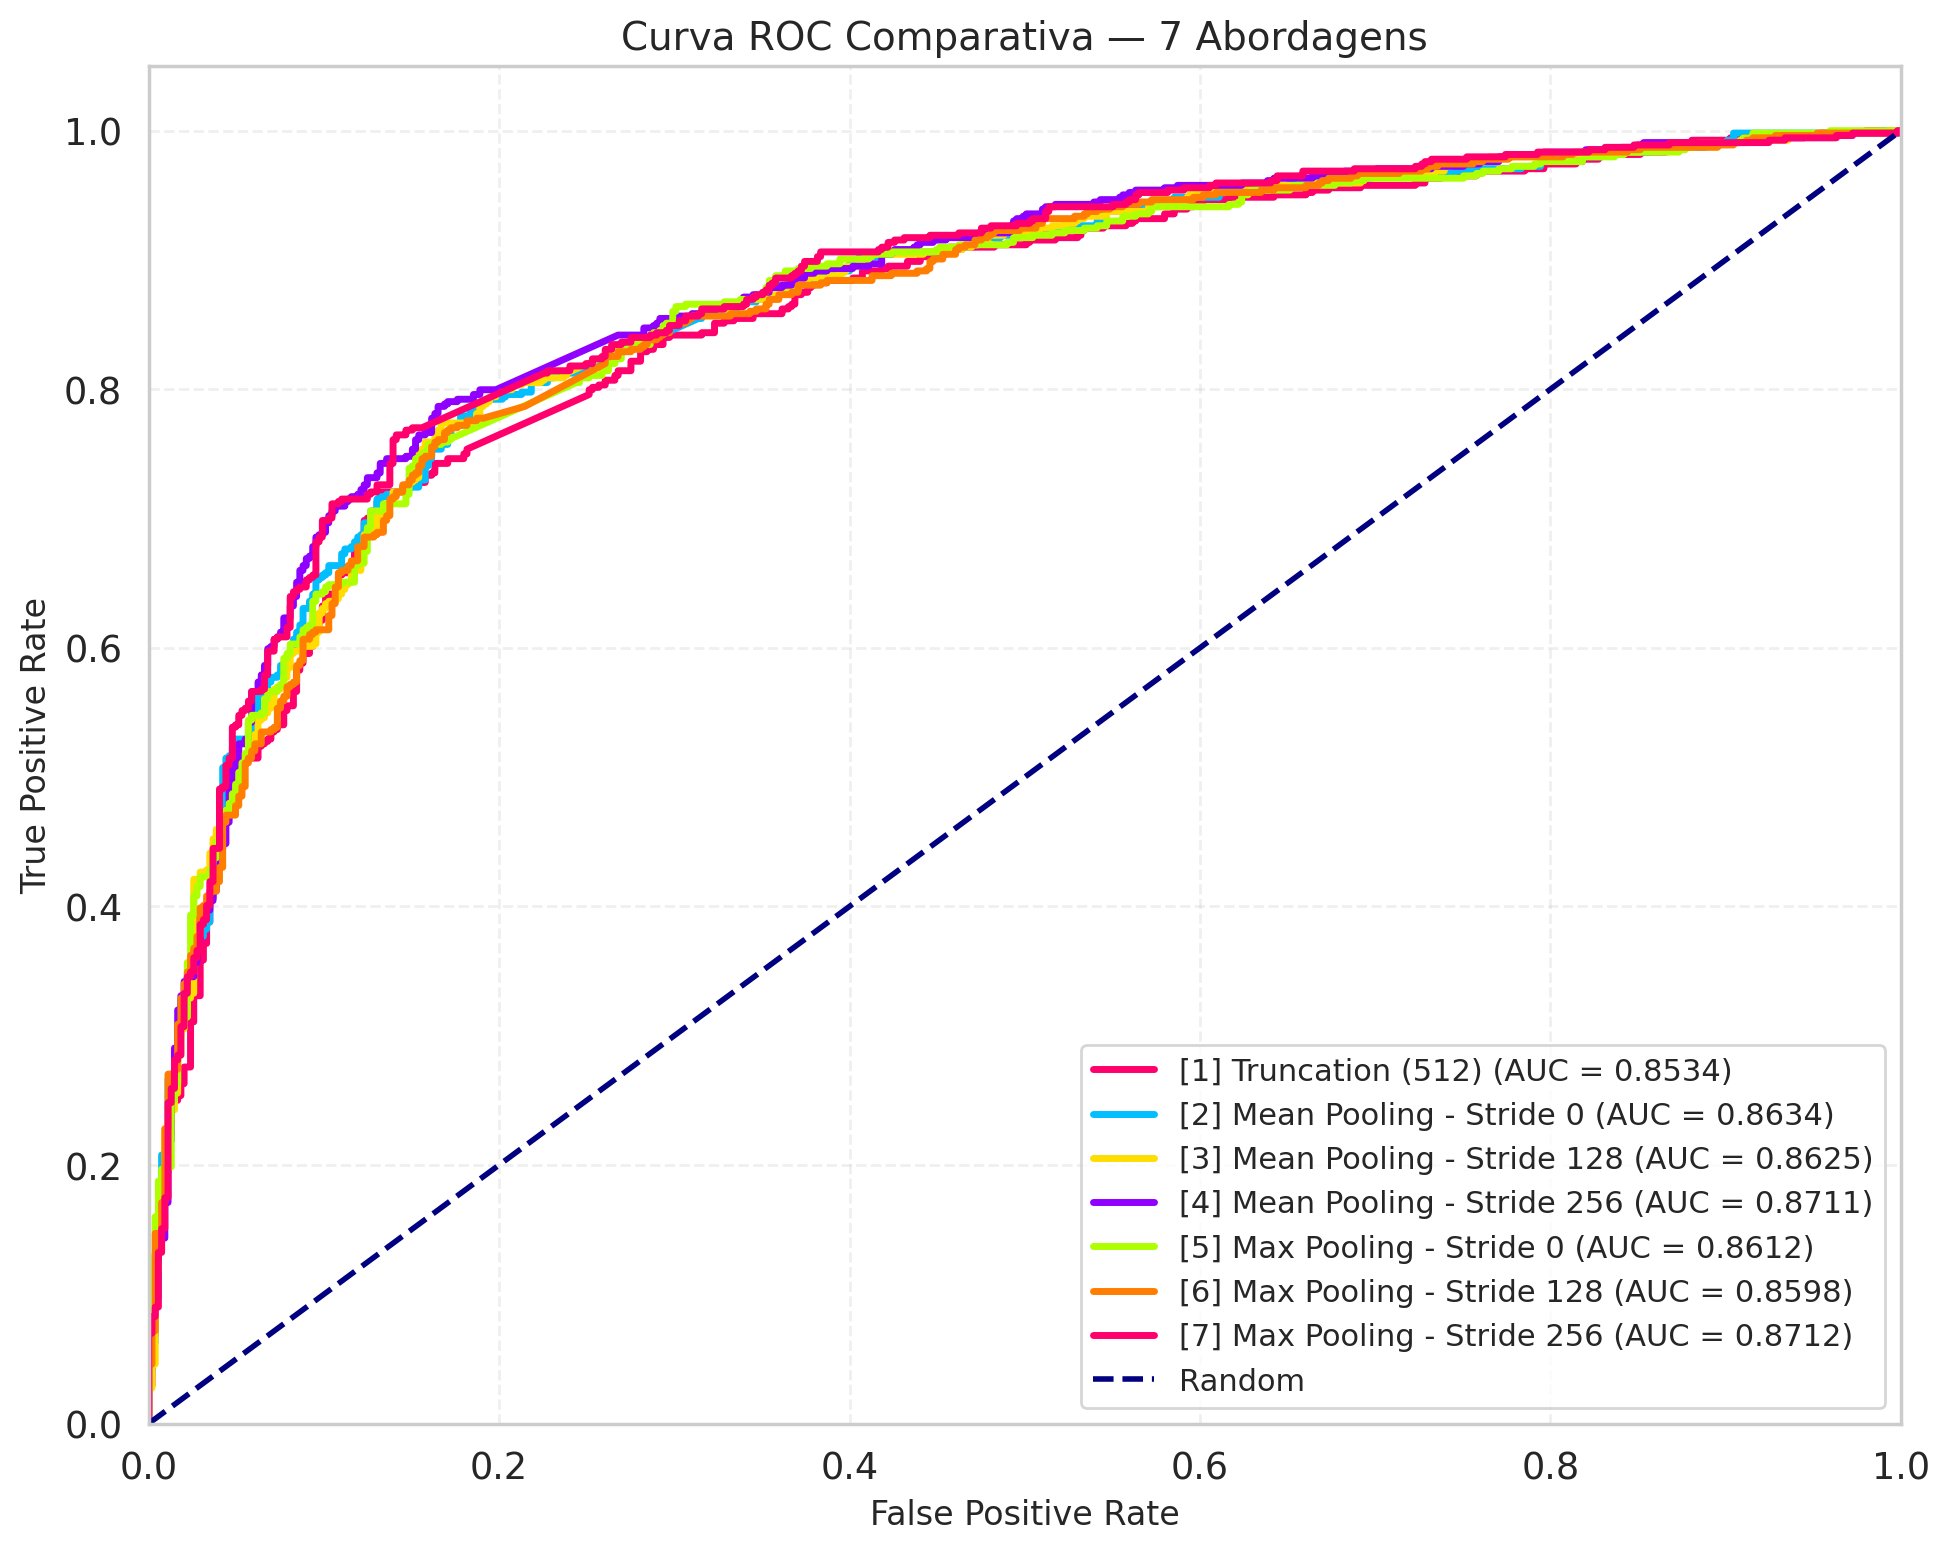

In [13]:
plt.figure(figsize=(10, 8))
colors = ['#FF006D', '#01BEFE', '#FFDD00', '#8F00FF', '#ADFF02', '#FF7D00']

for i, (approach_id, label, fpr, tpr, roc_auc) in enumerate(all_roc_data):
    plt.plot(fpr, tpr, color=colors[i % len(colors)], lw=2.5,
             label=f'[{approach_id}] {label} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'navy', lw=2, linestyle='--', label='Random')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Curva ROC Comparativa — 7 Abordagens', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

## Tabela Comparativa de Metricas

In [14]:
df_metrics = pd.DataFrame(all_metrics)
df_metrics = df_metrics.sort_values('ID', ascending=True).reset_index(drop=True)

print("=" * 80)
print("TABELA COMPARATIVA — 7 ABORDAGENS (Truncation | Mean/Max Pooling × Stride 0/128/256)")
print("=" * 80)
display(
    df_metrics.style
    .highlight_max(subset=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC'], color='lightgreen')
    .highlight_min(subset=['FPR'], color='lightblue')
)


TABELA COMPARATIVA — 7 ABORDAGENS (Truncation | Mean/Max Pooling × Stride 0/128/256)


,ID,Model,Approach,Accuracy,Precision,Recall,FPR,F1-Score,AUC
0,1,raquelsilveira/legalbertpt_fp,Truncation (512),0.791600,0.797500,0.791500,0.137600,0.790500,0.853400
1,2,raquelsilveira/legalbertpt_fp,Mean Pooling - Stride 0,0.796100,0.796100,0.796100,0.201800,0.796100,0.863400
2,3,raquelsilveira/legalbertpt_fp,Mean Pooling - Stride 128,0.798000,0.798000,0.798000,0.194500,0.798000,0.862500
3,4,raquelsilveira/legalbertpt_fp,Mean Pooling - Stride 256,0.806200,0.807500,0.806200,0.161500,0.806000,0.871100
4,5,raquelsilveira/legalbertpt_fp,Max Pooling - Stride 0,0.797100,0.799900,0.797000,0.154100,0.796600,0.861200
5,6,raquelsilveira/legalbertpt_fp,Max Pooling - Stride 128,0.797100,0.798900,0.797000,0.163300,0.796700,0.859800
6,7,raquelsilveira/legalbertpt_fp,Max Pooling - Stride 256,0.809900,0.813100,0.809900,0.139400,0.809400,0.871200


## Apuração para Textos Longos (> 512 palavras)

Filtra a base de teste mantendo apenas os registros cujo campo `RELATORIO` possui mais de 512 palavras.
Para cada abordagem, recarrega o melhor modelo salvo e realiza inferência nesse subconjunto,
calculando total de acertos, erros e percentuais.


In [15]:
# ===========================================================================
# Apuração para Textos Longos (> 512 palavras)
# ===========================================================================
import os, gc

# --- Filtra registros com RELATORIO acima de 512 palavras ---
long_test_df = (
    df_test[df_test["RELATORIO"].fillna("").astype(str)
            .str.split().str.len() > 512]
    .copy()
    .reset_index(drop=True)
)
print(f"Total de registros no teste:              {len(df_test)}")
print(f"Registros com RELATORIO > 512 palavras:   {len(long_test_df)}")

if len(long_test_df) == 0:
    raise RuntimeError("Nenhum registro com RELATORIO > 512 palavras encontrado no conjunto de teste.")

all_long_metrics = []

for approach_idx, approach_cfg in enumerate(APPROACHES):
    APPROACH_LABEL = approach_cfg["label"]
    APPROACH_STRIDE = approach_cfg["stride"]
    APPROACH_MAX_CHUNKS = approach_cfg["max_chunks"]
    APPROACH_BATCH_SIZE = approach_cfg["batch_size"]
    APPROACH_POOLING = approach_cfg["pooling"]
    APPROACH_MIN_CHUNK_TOKENS = approach_cfg.get("min_chunk_tokens", MIN_CHUNK_TOKENS)

    # Reutiliza o mesmo padrão do loop principal
    model_save_path = build_model_save_path(APPROACH_LABEL)

    print(f"\n[{approach_idx+1}/{len(APPROACHES)}] {APPROACH_LABEL}")

    if not os.path.exists(model_save_path):
        print(f"  AVISO: modelo n?o encontrado em {model_save_path} ? abordagem ignorada.")
        all_long_metrics.append({
            "Approach": APPROACH_LABEL,
            "Total de registros": len(long_test_df),
            "Total de acertos": None,
            "Total de erros": None,
            "Percentual de acertos (%)": None,
            "Percentual de erros (%)": None,
        })
        continue

    # Carrega o modelo
    model = HCAcordaoClassifier(
        n_classes=len(class_names),
        num_layers=NUM_LAYERS,
        model_name=MODEL_CHECKPOINT,
        pooling_strategy=APPROACH_POOLING,
    )
    model.load_state_dict(torch.load(model_save_path, map_location=device))
    model = model.to(device)
    model.eval()

    # DataLoader apenas para textos longos
    long_loader = create_data_loader(
        long_test_df,
        tokenizer,
        CHUNK_SIZE,
        APPROACH_STRIDE,
        APPROACH_BATCH_SIZE,
        APPROACH_MAX_CHUNKS,
        APPROACH_MIN_CHUNK_TOKENS,
        shuffle=False,
    )

    # Inferência
    long_y_pred, _, long_y_test = get_predictions(model, long_loader, device)

    long_total   = int(long_y_test.shape[0])
    long_correct = int((long_y_pred == long_y_test).sum().item())
    long_errors  = long_total - long_correct
    long_acc_pct = round(100.0 * long_correct / long_total, 2) if long_total > 0 else 0.0
    long_err_pct = round(100.0 * long_errors  / long_total, 2) if long_total > 0 else 0.0

    print(f"  Total: {long_total} | Acertos: {long_correct} ({long_acc_pct}%) | Erros: {long_errors} ({long_err_pct}%)")

    all_long_metrics.append({
        "Approach": APPROACH_LABEL,
        "Total de registros": long_total,
        "Total de acertos": long_correct,
        "Total de erros": long_errors,
        "Percentual de acertos (%)": long_acc_pct,
        "Percentual de erros (%)": long_err_pct,
    })

    # Libera memória
    del model, long_loader
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

# --- Tabela final ---
df_long_metrics = pd.DataFrame(all_long_metrics)

print("\n" + "=" * 80)
print("TABELA ? ACERTO POR ABORDAGEM ? SOMENTE TEXTOS LONGOS (> 512 PALAVRAS)")
print("=" * 80)

display(
    df_long_metrics.style
    .highlight_max(subset=["Percentual de acertos (%)"], color="lightgreen")
    .highlight_min(subset=["Percentual de erros (%)"],   color="lightblue")
    .format({
        "Percentual de acertos (%)": "{:.2f}%",
        "Percentual de erros (%)":   "{:.2f}%",
    }, na_rep="N/A")
)


Total de registros no teste:              1089
Registros com RELATORIO > 512 palavras:   46

[1/7] Truncation (512)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: raquelsilveira/legalbertpt_fp
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Freezing embeddings + first 12 encoder layers...
Layers freezing complete.
  [Dataset] Documentos: 46
  [Dataset] Chunks/doc antes do filtro (min=1):  3.85  (total=177)
  [Dataset] Chunks/doc ap?s  filtro (min=1):  3.85  (removidos=0, 0.0%)
  [Dataset] Chunks/doc ap?s max_chunks=1:  1.00  (total=46)
  Total: 46 | Acertos: 34 (73.91%) | Erros: 12 (26.09%)

[2/7] Mean Pooling - Stride 0


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

...

Freezing embeddings + first 12 encoder layers...
Layers freezing complete.
  [Dataset] Documentos: 46
  [Dataset] Chunks/doc antes do filtro (min=64):  10.65  (total=490)
  [Dataset] Chunks/doc ap?s  filtro (min=64):  10.65  (removidos=0, 0.0%)
  [Dataset] max_chunks=None ? sem limita??o adicional
  Total: 46 | Acertos: 38 (82.61%) | Erros: 8 (17.39%)

[7/7] Max Pooling - Stride 256


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: raquelsilveira/legalbertpt_fp
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Freezing embeddings + first 12 encoder layers...
Layers freezing complete.
  [Dataset] Documentos: 46
  [Dataset] Chunks/doc antes do filtro (min=64):  6.07  (total=279)
  [Dataset] Chunks/doc ap?s  filtro (min=64):  6.07  (removidos=0, 0.0%)
  [Dataset] max_chunks=None ? sem limita??o adicional
  Total: 46 | Acertos: 36 (78.26%) | Erros: 10 (21.74%)

TABELA ? ACERTO POR ABORDAGEM ? SOMENTE TEXTOS LONGOS (> 512 PALAVRAS)


,Approach,Total de registros,Total de acertos,Total de erros,Percentual de acertos (%),Percentual de erros (%)
0,Truncation (512),46,34,12,73.91%,26.09%
1,Mean Pooling - Stride 0,46,33,13,71.74%,28.26%
2,Mean Pooling - Stride 128,46,32,14,69.57%,30.43%
3,Mean Pooling - Stride 256,46,35,11,76.09%,23.91%
4,Max Pooling - Stride 0,46,35,11,76.09%,23.91%
5,Max Pooling - Stride 128,46,38,8,82.61%,17.39%
6,Max Pooling - Stride 256,46,36,10,78.26%,21.74%


In [ ]:
# Define the correct file path
file_path = f"{BASE_PATH_DATASET}preprocessed_acordaos_HC_geral_.csv"

if os.path.exists(file_path):
    try:
        dataset_geral = pd.read_csv(file_path, sep=';')
        loaded_from = file_path
        print(f"✅ Arquivo carregado com sucesso de: {file_path}")
        print(f"Shape: {dataset_geral.shape}")
        display(dataset_geral.head(3))
    except Exception as e:
        print(f"❌ Erro ao ler {file_path}: {e}")
else:
    print(f"⚠️ Arquivo CSV não encontrado no caminho: {file_path}")
    print("Por favor, verifique se o arquivo existe ou o caminho está correto.")

In [ ]:
# ===========================================================================
# Subconjunto para inferencia: textos longos fora de treino/teste
# ===========================================================================
required_cols_geral = {"RELATORIO", "SEQDOCUMENTO", "MINISTRO"}
missing_cols_geral = required_cols_geral - set(dataset_geral.columns)
if missing_cols_geral:
    raise KeyError(f"dataset_geral sem colunas obrigatorias: {sorted(missing_cols_geral)}")

required_cols_train_test = {"SEQDOCUMENTO", "MINISTRO"}
for df_name, df_ref in (("df_train", df_train), ("df_test", df_test)):
    missing = required_cols_train_test - set(df_ref.columns)
    if missing:
        raise KeyError(f"{df_name} sem colunas obrigatorias: {sorted(missing)}")

# 1) Textos com mais de 512 palavras no RELATORIO
mask_long_text = dataset_geral["RELATORIO"].fillna("").astype(str).str.split().str.len() > 512

# 2) Excluir SEQDOCUMENTO ja presentes em df_train e df_test
seq_train_test = set(
    pd.concat([df_train["SEQDOCUMENTO"], df_test["SEQDOCUMENTO"]], ignore_index=True)
    .dropna()
    .astype(str)
    .str.strip()
)
seq_geral = dataset_geral["SEQDOCUMENTO"].fillna("").astype(str).str.strip()
mask_seq_not_in_train_test = ~seq_geral.isin(seq_train_test)

# 3) Manter apenas ministros presentes em df_train
ministros_train = set(df_train["MINISTRO"].dropna().astype(str).str.strip())
ministro_geral = dataset_geral["MINISTRO"].fillna("").astype(str).str.strip()
mask_ministro_in_train = ministro_geral.isin(ministros_train)

# DataFrame final
mask_final = mask_long_text & mask_seq_not_in_train_test & mask_ministro_in_train
df_diff_long_text = dataset_geral.loc[mask_final].copy().reset_index(drop=True)

print(f"Total dataset_geral: {len(dataset_geral)}")
print(f"Textos longos (>512 palavras): {int(mask_long_text.sum())}")
print(f"Apos remover SEQDOCUMENTO de treino/teste: {int((mask_long_text & mask_seq_not_in_train_test).sum())}")
print(f"Total df_diff_long_text: {len(df_diff_long_text)}")

print("\nPrimeiros 5 registros de df_diff_long_text:")
display(df_diff_long_text.head(5))

ministros_unicos_diff = sorted(
    df_diff_long_text["MINISTRO"].dropna().astype(str).str.strip().unique().tolist()
)
print("\nMinistros unicos em df_diff_long_text:")
print(ministros_unicos_diff)


In [ ]:
# ===========================================================================
# Proxima etapa: inferencia em df_diff_long_text por abordagem
# ===========================================================================
if df_diff_long_text.empty:
    raise RuntimeError("df_diff_long_text esta vazio. Nao ha dados para inferencia.")

# Prepara base para DataLoader (cria/alinha coluna de classe quando possivel)
df_diff_infer = df_diff_long_text.copy()
has_ground_truth = False

if "classe" in df_diff_infer.columns:
    has_ground_truth = True
elif "DECISAO_FAVORAVEL" in df_diff_infer.columns:
    df_diff_infer["classe"] = df_diff_infer["DECISAO_FAVORAVEL"].apply(cast_decisao_to_int)
    has_ground_truth = True
else:
    # Necessario para reutilizar o DataLoader/dataset existentes
    df_diff_infer["classe"] = 0

pred_label_map = {0: class_names[0], 1: class_names[1]}
all_diff_metrics = []

for approach_idx, approach_cfg in enumerate(APPROACHES):
    APPROACH_LABEL = approach_cfg["label"]
    APPROACH_STRIDE = approach_cfg["stride"]
    APPROACH_MAX_CHUNKS = approach_cfg["max_chunks"]
    APPROACH_BATCH_SIZE = approach_cfg["batch_size"]
    APPROACH_POOLING = approach_cfg["pooling"]
    APPROACH_MIN_CHUNK_TOKENS = approach_cfg.get("min_chunk_tokens", MIN_CHUNK_TOKENS)

    model_save_path = build_model_save_path(APPROACH_LABEL)

    print(f"\n[{approach_idx + 1}/{len(APPROACHES)}] {APPROACH_LABEL}")
    if not os.path.exists(model_save_path):
        print(f"  AVISO: modelo nao encontrado em {model_save_path}. Abordagem ignorada.")
        all_diff_metrics.append({
            "Approach": APPROACH_LABEL,
            "Total de registros": len(df_diff_infer),
            "Pred 0": None,
            "Pred 1": None,
            "Percentual Pred 1 (%)": None,
            "Total de acertos": None,
            "Total de erros": None,
            "Percentual de acertos (%)": None,
            "Percentual de erros (%)": None,
        })
        continue

    model = HCAcordaoClassifier(
        n_classes=len(class_names),
        num_layers=NUM_LAYERS,
        model_name=MODEL_CHECKPOINT,
        pooling_strategy=APPROACH_POOLING,
    )
    model.load_state_dict(torch.load(model_save_path, map_location=device))
    model = model.to(device)
    model.eval()

    diff_loader = create_data_loader(
        df_diff_infer,
        tokenizer,
        CHUNK_SIZE,
        APPROACH_STRIDE,
        APPROACH_BATCH_SIZE,
        APPROACH_MAX_CHUNKS,
        APPROACH_MIN_CHUNK_TOKENS,
        shuffle=False,
    )

    y_pred, y_pred_logits, y_real = get_predictions(model, diff_loader, device)
    probs = F.softmax(y_pred_logits, dim=1).numpy()
    pred_np = y_pred.numpy()

    pred_0 = int((pred_np == 0).sum())
    pred_1 = int((pred_np == 1).sum())
    total = int(len(pred_np))
    pred_1_pct = round(100.0 * pred_1 / total, 2) if total > 0 else 0.0

    if has_ground_truth:
        y_real_np = y_real.numpy()
        correct = int((pred_np == y_real_np).sum())
        errors = total - correct
        acc_pct = round(100.0 * correct / total, 2) if total > 0 else 0.0
        err_pct = round(100.0 * errors / total, 2) if total > 0 else 0.0
        print(f"  Total: {total} | Acertos: {correct} ({acc_pct}%) | Erros: {errors} ({err_pct}%)")
    else:
        correct = None
        errors = None
        acc_pct = None
        err_pct = None
        print(f"  Total: {total} | Pred 0: {pred_0} | Pred 1: {pred_1} ({pred_1_pct}%)")

    # Guarda previsoes por abordagem para analise posterior
    df_diff_long_text[f"pred_{approach_idx + 1}"] = pred_np
    df_diff_long_text[f"pred_label_{approach_idx + 1}"] = pd.Series(pred_np).map(pred_label_map)
    df_diff_long_text[f"pred_prob_favoravel_{approach_idx + 1}"] = probs[:, 1]

    all_diff_metrics.append({
        "Approach": APPROACH_LABEL,
        "Total de registros": total,
        "Pred 0": pred_0,
        "Pred 1": pred_1,
        "Percentual Pred 1 (%)": pred_1_pct,
        "Total de acertos": correct,
        "Total de erros": errors,
        "Percentual de acertos (%)": acc_pct,
        "Percentual de erros (%)": err_pct,
    })

    del model, diff_loader
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

df_diff_infer_metrics = pd.DataFrame(all_diff_metrics)

print("\n" + "=" * 80)
print("INFERENCIA EM DF_DIFF_LONG_TEXT — RESUMO POR ABORDAGEM")
print("=" * 80)
display(df_diff_infer_metrics)

print("\nExemplo de previsoes adicionadas em df_diff_long_text (5 primeiras linhas):")
display(df_diff_long_text.head(5))

